# Лекция 4. ООП и декораторы: кто владеет данными и кто зовёт функцию

В прошлый раз я обещал: следующая лекция — про классы и объекты. Обещания надо выполнять, особенно тому, у кого вы сдаёте зачёт. Сегодня наконец станет понятно, что за `__mro__` мы видели в родословной ошибок и почему у строки есть `.upper()`, а у числа нет.

Начну с ситуации. Сюжет ДЗ2 вы знаете: компания съездила на шашлыки, траты записаны в чате, все выясняют, кто кому должен. ДЗ2 вы решаете словарями и функциями — и это нормальное решение. Копейки — ваша боль в ДЗ2, сегодня их не будет: все суммы — целые рубли.

А теперь жизнь усложняет задачу. Поездок одновременно две: «Последний шашлык» и «Поминки дедлайна». Появилось правило: отрицательную трату не принимаем — Граф Дебажный уже пытался записать «моральный ущерб, минус пятьсот». И отчёт должен строиться одинаково, откуда бы его ни попросили: из консоли сегодня или из Telegram-бота через неделю. Попробуем на словарях:

# Bài 4. OOP và decorator: ai sở hữu dữ liệu và ai gọi hàm

Lần trước tôi đã hứa: bài tiếp theo sẽ nói về class và object. Đã hứa thì phải làm, nhất là khi người hứa lại là người chấm điểm môn của các bạn. Hôm nay cuối cùng cũng sẽ rõ `__mro__` mà ta từng thấy trong "gia phả" của các lỗi là cái gì, và vì sao string có `.upper()` còn số thì không.

Bắt đầu từ một tình huống. Cốt truyện BTVN2 các bạn đã biết: cả nhóm đi nướng thịt (шашлык), các khoản chi được ghi trong chat, mọi người đang tính xem ai nợ ai. BTVN2 các bạn giải bằng dictionary và hàm — đó là một lời giải bình thường. Số lẻ kopeck là nỗi đau của các bạn ở BTVN2, hôm nay sẽ không có: mọi số tiền đều là rúp nguyên.

Nhưng giờ cuộc đời làm bài toán phức tạp hơn. Có đồng thời hai chuyến đi: «Последний шашлык» ("Buổi nướng thịt cuối cùng") và «Поминки дедлайна» ("Đám tang deadline"). Xuất hiện một quy tắc: không nhận khoản chi âm — Graf Debazhny (Граф Дебажный, "Bá tước Debug") đã từng thử ghi «моральный ущерб, минус пятьсот» ("tổn thất tinh thần, âm năm trăm"). Và báo cáo phải được dựng giống hệt nhau dù được yêu cầu từ đâu: từ console hôm nay hay từ Telegram bot một tuần nữa. Thử với dictionary:

In [1]:
trip = {"title": "Последний шашлык", "expenses": []}


def add_expense(trip, payer, amount, reason):
    if amount <= 0:
        raise ValueError(f"Сумма должна быть положительной: {amount}")
    trip["expenses"].append({"payer": payer, "amount": amount, "reason": reason})


add_expense(trip, "Бобр Иваныч", 1200, "уголь для последнего шашлыка")
# а Граф Дебажный про функцию не знает и пишет в словарь напрямую
trip["expenses"].append({"payer": "Граф Дебажный", "amount": -500, "reason": "моральный ущерб"})

print(sum(e["amount"] for e in trip["expenses"]), "₽")

700 ₽


Итого 700 рублей, и никто ничего не заметил. Правило есть, но живёт оно в функции, а данные лежат отдельно, в словаре, и до них может дотянуться кто угодно. Старая версия этой лекции начиналась так же: сначала 300 переменных на сто студентов, потом словари, а потом выясняется, что данные отдельно, поведение отдельно, и их ничто не связывает. Класс их связывает: данные поездки и правила работы с ними лежат в одном месте, и правило не обойти случайно.

Tổng cộng 700 rúp, và không ai nhận ra gì cả. Quy tắc có đó, nhưng nó nằm trong hàm, còn dữ liệu nằm riêng trong dictionary, ai cũng với tay vào được. Phiên bản cũ của bài giảng này cũng bắt đầu như thế: đầu tiên là 300 biến cho một trăm sinh viên, rồi dictionary, rồi hóa ra dữ liệu một nơi, hành vi một nơi, và không gì liên kết chúng. Class liên kết chúng: dữ liệu của chuyến đi và các quy tắc làm việc với dữ liệu đó nằm cùng một chỗ, và không thể vô tình lách qua quy tắc.

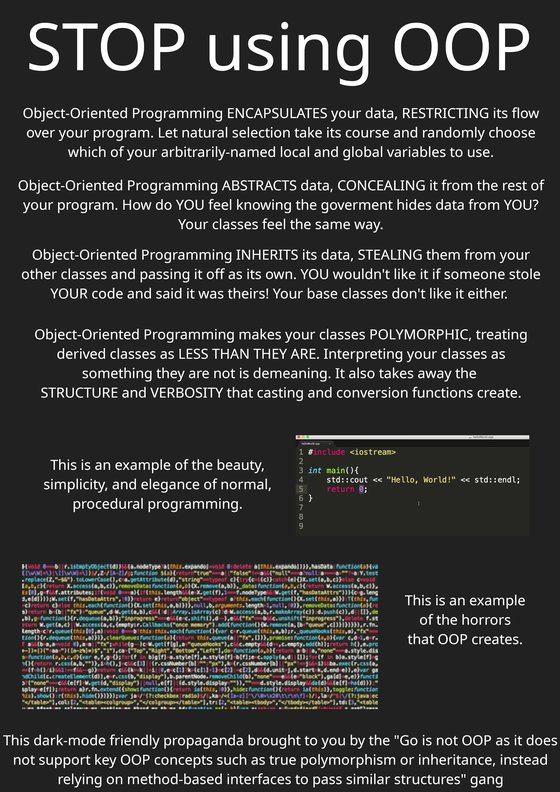

*Манифест сторонников подхода, с которого мы начали лекцию. «Пусть естественный отбор сам выберет, какую из как попало названных переменных взять» — ровно так Граф Дебажный и дописал свои минус пятьсот мимо `add_expense`. Перечитайте пункты внимательно: каждый аргумент «против» ООП здесь — аргумент «за». Инкапсуляция действительно ограничивает, куда ходят данные. В этом и смысл.*

*Bản tuyên ngôn của những người ủng hộ cách tiếp cận mà ta đã bắt đầu bài giảng. «Hãy để chọn lọc tự nhiên tự chọn xem dùng biến nào trong số những biến được đặt tên tùy tiện» — đúng kiểu Graf Debazhny đã ghi thêm âm năm trăm của mình bỏ qua `add_expense`. Hãy đọc kỹ lại các điểm: mỗi lập luận "chống" OOP ở đây thực ra là lập luận "ủng hộ". Encapsulation đúng là hạn chế dữ liệu được đi đâu. Ý nghĩa của nó nằm ở đó.*

**План на сегодня.** Вся лекция — про два навыка. Первый: **кто владеет состоянием** — где живут данные и кто имеет право их менять. Второй: **кто, когда и какую функцию вызывает** — на этом стоят декораторы и все библиотеки для ботов.

**Блок 1 — объекты и их состояние.**

1. **Класс и экземпляр** — `class`, `__init__`, `self`.
2. **Кто владеет состоянием** — два ярлыка на одном объекте и холодильник на всё общежитие.
3. **Объект в обычном Python** — `print`, `len` и загадочное `object at 0x…`.
4. **Композиция и инвариант** — журнал, который сам следит за правилами.
5. **Наследование там, где уместно** — свои исключения и наконец-то `__mro__`.
6. 🧨 **ООП на собеседовании** — что спросят и как не утонуть.

**Блок 2 — кто вызывает функцию.**

7. **Функция как объект** — передать функцию, не вызывая её.
8. **Обёртка** — декоратор, который подменяет функцию (и замеряет время).
9. **Регистрация, фабрика, порядок** — `@command("/итого")`, как в настоящих ботах.

**Блок 3 — современный класс и мост к ботам.**

10. **`@dataclass`** — пусть типовые бумажки заполняет робот.
11. **`property`** — атрибут, который считается на лету.
12. **Мост к ботам** — два чата, два журнала, один обработчик; пять минут про `async`.
13. Резерв, если осталось время, — 🧨 «Архитектурная космонавтика».
14. **Итоги.**

Как и раньше: **🧨 Экстра** можно пропустить — тогда читаете дома; **📚 Самостоятельно** — сразу дома, они в конце тетрадки. Подразделы со значком **⏩** я пропущу, если вы уверенно ответите на контрольный вопрос перед ними — их два, в разделах 2 и 7. Своего ДЗ у лекции нет: всё сегодняшнее понадобится в ДЗ4 про Telegram-ботов. Поехали.

**Kế hoạch hôm nay.** Cả bài chỉ xoay quanh hai kỹ năng. Thứ nhất: **ai sở hữu state** — dữ liệu sống ở đâu và ai có quyền sửa chúng. Thứ hai: **ai, khi nào và gọi hàm nào** — decorator và mọi thư viện viết bot đều đứng trên nền này.

**Khối 1 — object và state của chúng.**

1. **Class và instance** — `class`, `__init__`, `self`.
2. **Ai sở hữu state** — hai nhãn trên cùng một object và cái tủ lạnh chung cho cả ký túc xá.
3. **Object trong Python thông thường** — `print`, `len` và dòng bí ẩn `object at 0x…`.
4. **Composition và invariant** — cuốn sổ tự giám sát các quy tắc.
5. **Inheritance ở chỗ thích hợp** — exception riêng và cuối cùng là `__mro__`.
6. 🧨 **OOP trong phỏng vấn** — sẽ hỏi gì và làm sao không chìm.

**Khối 2 — ai gọi hàm.**

7. **Hàm như một object** — truyền hàm đi mà không gọi nó.
8. **Wrapper** — decorator thay thế hàm (và đo thời gian).
9. **Đăng ký, factory, thứ tự** — `@command("/итого")`, như trong các bot thật.

**Khối 3 — class hiện đại và cầu nối sang bot.**

10. **`@dataclass`** — để robot điền những tờ giấy mẫu.
11. **`property`** — thuộc tính được tính ngay khi truy cập.
12. **Cầu nối sang bot** — hai chat, hai cuốn sổ, một handler; năm phút về `async`.
13. Dự phòng, nếu còn thời gian — 🧨 «Du hành vũ trụ kiến trúc».
14. **Tổng kết.**

Như trước: phần **🧨 Extra** có thể bỏ qua — khi đó các bạn đọc ở nhà; phần **📚 Tự học** làm ở nhà luôn, chúng nằm cuối notebook. Các mục con có biểu tượng **⏩** tôi sẽ bỏ qua nếu các bạn trả lời chắc chắn câu hỏi kiểm tra đứng trước chúng — có hai câu, ở mục 2 và mục 7. Bài này không có BTVN riêng: mọi thứ hôm nay sẽ cần cho BTVN4 về Telegram bot. Bắt đầu thôi.

# 1. Класс и экземпляр

Начнём с самого маленького объекта нашей истории — одной траты. У траты есть кто заплатил, сколько и за что. И есть одно действие: описать себя человеческим языком. Вот как это выглядит в виде класса:

# 1. Class và instance

Bắt đầu từ object nhỏ nhất trong câu chuyện — một khoản chi. Khoản chi có ai trả, bao nhiêu và vì cái gì. Và có một hành động: mô tả bản thân bằng ngôn ngữ con người. Dưới dạng class nó trông thế này:

In [2]:
class Expense:
    def __init__(self, payer: str, amount: int, reason: str):
        self.payer = payer      # кто заплатил
        self.amount = amount    # целые рубли
        self.reason = reason    # за что

    def describe(self) -> str:
        return f"{self.payer}: {self.reason} — {self.amount} ₽"


expense = Expense("Бобр Иваныч", 1200, "уголь для последнего шашлыка")
print(expense.describe())

Бобр Иваныч: уголь для последнего шашлыка — 1200 ₽


Давайте разберём этот код по органам, хоть мы и не в Питере.

**`class Expense:`** — объявляем новый тип данных. Имя класса — с большой буквы и без подчёркиваний, `CamelCase`: в Л2 я обещал, что имена с большой буквы мы прибережём для классов. Вот они. Всё, что написано с отступом под `class`, — тело класса.

**Класс и экземпляр.** Класс — бланк акта о происшествии. Экземпляр — конкретный заполненный акт. Происшествия похожи, виноватые разные. `Expense` — бланк: в нём написано, какие поля бывают и что с ними можно делать. А `Expense("Бобр Иваныч", 1200, …)` — заполненный акт, конкретная трата. По одному бланку можно заполнить сколько угодно актов, и каждый будет хранить свои данные.

**`__init__`** — метод с двумя подчёркиваниями с каждой стороны. Python вызывает его сам, в момент, когда вы пишете `Expense(...)`. Его часто называют конструктором, но честнее — инициализатор. Это не создание Вселенной, а заселение уже выделенного помещения: пустой объект Python создал до вас, а `__init__` расставляет мебель — имя сюда, сумму сюда, надежды на возврат долга в мусор.

**`self`** — первый параметр каждого метода. Это носитель тайного знания: в нём лежит тот самый объект, с которым сейчас работаем. `self.payer = payer` значит: «возьми **этот** объект и приклей к нему ярлык `payer`». Без `self` метод не знает, чей именно бардак ему разгребать. Имя `self` — не ключевое слово, а договорённость. В исходнике этой лекции был метод с первым параметром `sosisochka` — и он работал. Но если вы так сделаете в рабочем коде, на ревью вас убьют, и будут правы.

**`describe`** — обычная функция, только живёт внутри класса. Такие функции называются **методами**. А `payer`, `amount`, `reason` — **атрибуты**: переменные, которые принадлежат объекту. Удобно думать так: атрибуты — существительные объекта, его данные и состояние («плательщик», «сумма»), методы — глаголы, то, что объект умеет делать («опиши себя»). Обратите внимание: `describe` не принимает ни плательщика, ни сумму — всё нужное он берёт из `self`. Данные и поведение наконец оказались в одном месте, ради этого всё и затевалось. Сравните с `add_expense(trip, payer, amount, reason)` из вступления, которой словарь приходилось таскать за собой в каждом вызове.

Hãy "giải phẫu" đoạn code này theo từng cơ quan, dù ta không ở Peterburg.

**`class Expense:`** — khai báo một kiểu dữ liệu mới. Tên class viết hoa chữ cái đầu và không có dấu gạch dưới, `CamelCase`: ở B2 tôi đã hứa rằng tên viết hoa ta dành cho class. Đây rồi. Mọi thứ thụt lề dưới `class` là thân của class.

**Class và instance.** Class là mẫu biên bản sự cố. Instance là một biên bản cụ thể đã điền. Các sự cố giống nhau, thủ phạm khác nhau. `Expense` là mẫu: trong đó ghi có những trường nào và có thể làm gì với chúng. Còn `Expense("Бобр Иваныч", 1200, …)` là biên bản đã điền, một khoản chi cụ thể. Từ một mẫu có thể điền bao nhiêu biên bản tùy ý, và mỗi biên bản giữ dữ liệu riêng của mình.

**`__init__`** — method có hai dấu gạch dưới mỗi bên. Python tự gọi nó đúng lúc bạn viết `Expense(...)`. Người ta hay gọi nó là constructor, nhưng chính xác hơn là initializer. Đây không phải là việc tạo ra Vũ trụ, mà là việc dọn vào một căn phòng đã được cấp sẵn: object trống Python đã tạo trước bạn, còn `__init__` xếp đồ đạc — tên để đây, số tiền để đây, hy vọng đòi lại nợ thì vứt vào sọt rác.

**`self`** — tham số đầu tiên của mỗi method. Nó mang "tri thức bí mật": trong đó chứa chính object mà ta đang làm việc. `self.payer = payer` nghĩa là: "lấy **object này** và dán lên nó nhãn `payer`". Không có `self`, method không biết phải dọn đống bừa bộn của ai. Tên `self` không phải từ khóa mà là một quy ước. Trong bản gốc của bài giảng này từng có method với tham số đầu tiên tên `sosisochka` ("cái xúc xích") — và nó vẫn chạy. Nhưng nếu bạn làm vậy trong code thật, review sẽ "giết" bạn, và họ đúng.

**`describe`** — một hàm bình thường, chỉ khác là nó sống bên trong class. Những hàm như vậy gọi là **method**. Còn `payer`, `amount`, `reason` là **attribute**: các biến thuộc về object. Có thể hình dung thế này: attribute là danh từ của object, là dữ liệu và state của nó («người trả», «số tiền»), method là động từ, là những gì object biết làm («hãy mô tả bản thân»). Lưu ý: `describe` không nhận người trả hay số tiền — mọi thứ cần thiết nó lấy từ `self`. Dữ liệu và hành vi cuối cùng đã nằm cùng một chỗ, mọi chuyện bày ra là vì điều này. So sánh với `add_expense(trip, payer, amount, reason)` ở phần mở đầu, hàm mà lúc nào cũng phải kéo theo dictionary trong mỗi lần gọi.

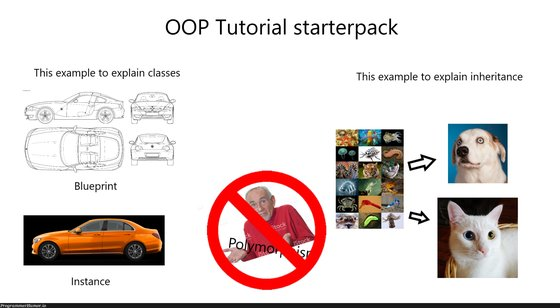

*Стартовый набор любого учебника. Чертёж — это класс `Expense`, машина — экземпляр `Expense("Бобр Иваныч", 1200, …)`. Только присмотритесь: на чертеже двухдверное купе, а с конвейера съехал седан. В Python так не бывает — экземпляр всегда того класса, который вы вызвали, и `type(expense)` это подтвердит. Кошки с собаками справа нам ещё встретятся в разделе 5.*

*Bộ khởi đầu của mọi giáo trình. Bản vẽ là class `Expense`, chiếc xe là instance `Expense("Бобр Иваныч", 1200, …)`. Chỉ có điều hãy nhìn kỹ: trên bản vẽ là coupe hai cửa, còn từ dây chuyền lăn ra lại là sedan. Trong Python không có chuyện đó — instance luôn thuộc class mà bạn đã gọi, và `type(expense)` sẽ xác nhận. Mèo và chó bên phải ta còn gặp lại ở mục 5.*

## Два экземпляра — два набора данных

Создадим вторую трату и посмотрим, что у каждой своё:

## Hai instance — hai bộ dữ liệu

Tạo khoản chi thứ hai và xem mỗi khoản có gì riêng:

In [3]:
water = Expense("Граф Дебажный", 300, "вода")

print(expense.describe())
print(water.describe())
print(vars(expense))
print(vars(water))

Бобр Иваныч: уголь для последнего шашлыка — 1200 ₽
Граф Дебажный: вода — 300 ₽
{'payer': 'Бобр Иваныч', 'amount': 1200, 'reason': 'уголь для последнего шашлыка'}
{'payer': 'Граф Дебажный', 'amount': 300, 'reason': 'вода'}


Бланк один, актов два, и данные у них не перемешались. Функция `vars()` показывает, что лежит **внутри** конкретного объекта: словарь его атрибутов. У `expense` — Бобр и уголь, у `water` — Граф и вода. Метода `describe` в этих словарях нет. Запомните это, через минуту пригодится.

Mẫu chỉ một, biên bản có hai, và dữ liệu của chúng không lẫn vào nhau. Hàm `vars()` cho thấy cái gì nằm **bên trong** một object cụ thể: dictionary các attribute của nó. Ở `expense` — Bobr và than củi, ở `water` — Graf và nước. Method `describe` không có trong các dictionary này. Hãy nhớ điều đó, một phút nữa sẽ cần.

## Как Python находит метод

Откуда же объект знает про `describe`, если внутри у него только три атрибута? Когда вы пишете `water.describe()`, Python делает вот что:

1. Ищет `describe` у самого объекта `water`. Не находит.
2. Идёт в класс, по которому объект создан, — в `Expense`. Находит там функцию.
3. Вызывает её и **сам подставляет** `water` первым аргументом — в `self`.

То есть запись `water.describe()` — это просто удобное сокращение для `Expense.describe(water)`. Проверим:

## Python tìm method như thế nào

Vậy object biết về `describe` từ đâu, nếu bên trong nó chỉ có ba attribute? Khi bạn viết `water.describe()`, Python làm như sau:

1. Tìm `describe` ở chính object `water`. Không thấy.
2. Đi tới class mà object được tạo từ đó — `Expense`. Tìm thấy hàm ở đó.
3. Gọi nó và **tự truyền** `water` làm đối số đầu tiên — vào `self`.

Tức là `water.describe()` chỉ là cách viết tắt tiện lợi của `Expense.describe(water)`. Kiểm tra:

In [4]:
print(water.describe())
print(Expense.describe(water))
print("шашлык".upper(), str.upper("шашлык"))

Граф Дебажный: вода — 300 ₽
Граф Дебажный: вода — 300 ₽
ШАШЛЫК ШАШЛЫК


Одно и то же. А третья строка закрывает ещё один долг прошлой лекции: почему у строки есть `.upper()`, а у числа нет. Потому что `"шашлык"` — экземпляр класса `str`, а метод `upper` живёт в классе `str`. У класса `int` такого метода просто нет. Вы с первой лекции пользуетесь объектами и методами — сегодня впервые пишете свои.

Giống hệt nhau. Còn dòng thứ ba trả nốt một món nợ của bài trước: vì sao string có `.upper()` còn số thì không. Vì `"шашлык"` là instance của class `str`, và method `upper` sống trong class `str`. Class `int` đơn giản là không có method như vậy. Từ bài đầu tiên các bạn đã dùng object và method — hôm nay lần đầu tiên tự viết.

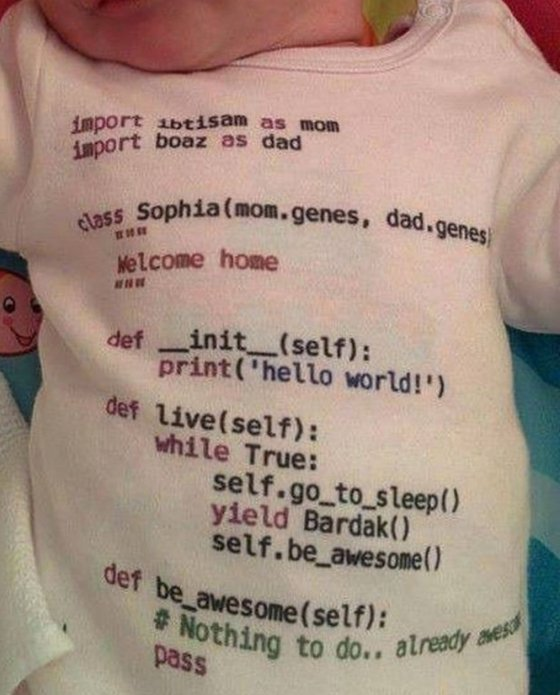

*Код на бодике новорождённой. Каждый метод начинается с `self`: `sophia.live()` Python превратит в `Sophia.live(sophia)` и подставит ребёнка сам — ровно как `water` в ячейке выше. Наследование сразу от двух классов, маминых и папиных генов, — тоже настоящий Python. А вот бардак метод `live` не разгребает, а производит: `yield Bardak()` в бесконечном цикле. `yield` делает метод генератором — до них дойдём в 📚 в конце лекции. Разгребать будут родители.*

*Code trên bodysuit của em bé sơ sinh. Mỗi method đều bắt đầu bằng `self`: `sophia.live()` Python sẽ biến thành `Sophia.live(sophia)` và tự truyền đứa bé vào — y như `water` ở ô code phía trên. Kế thừa từ hai class cùng lúc, gen của mẹ và gen của bố, cũng là Python thật. Nhưng method `live` không dọn đống bừa bộn mà là sản xuất ra nó: `yield Bardak()` trong vòng lặp vô hạn. `yield` biến method thành generator — ta sẽ nói tới ở phần 📚 cuối bài. Việc dọn dẹp sẽ là của bố mẹ.*

## `Expense` и `Expense(...)` — не одно и то же

Скобки решают всё. Без скобок `Expense` — это сам класс, бланк. Со скобками — вызов класса, который создаёт новый экземпляр. Кстати, класс в Python — тоже объект, у него тоже есть тип:

## `Expense` và `Expense(...)` — không phải một thứ

Dấu ngoặc quyết định tất cả. Không có ngoặc thì `Expense` là chính class, cái mẫu. Có ngoặc thì là lời gọi class, tạo ra instance mới. Nhân tiện, class trong Python cũng là một object, nó cũng có type:

In [5]:
print(type(expense))
print(type(Expense))

<class '__main__.Expense'>
<class 'type'>


Тип траты — `Expense`, а тип самого класса — `type`. Да, в Python всё объект, даже бланк для объектов. Не пугайтесь, глубже этой кроличьей норы мы сегодня не полезем.

А вот что бывает, когда скобки забыли. Ячейка падает специально:

Type của khoản chi là `Expense`, còn type của chính class là `type`. Đúng, trong Python mọi thứ đều là object, kể cả cái mẫu để tạo object. Đừng sợ, hôm nay ta không đào sâu hơn cái hang thỏ này.

Còn đây là chuyện xảy ra khi quên ngoặc. Ô này cố ý báo lỗi:

In [6]:
blank = Expense      # забыли скобки: это не трата, а ещё одно имя для класса
print(blank.payer)   # ⚠️ упадёт специально

AttributeError: type object 'Expense' has no attribute 'payer'

`AttributeError: type object 'Expense' has no attribute 'payer'`. Слово `type object` — подсказка: вы обращаетесь к классу, а не к экземпляру. У бланка нет плательщика — плательщик бывает только у заполненного акта. Вы дали классу второе имя, а не вызвали его.

`AttributeError: type object 'Expense' has no attribute 'payer'`. Cụm `type object` là gợi ý: bạn đang truy cập vào class chứ không phải instance. Mẫu biên bản không có người trả — người trả chỉ có ở biên bản đã điền. Bạn đã đặt cho class một cái tên thứ hai chứ không gọi nó.

## Метод без скобок

С методами та же история. `water.describe()` — вызов, результат — строка. `water.describe` без скобок — сам метод, ещё не вызванный:

## Method không có ngoặc

Với method cũng vậy. `water.describe()` là lời gọi, kết quả là string. `water.describe` không ngoặc là chính method, chưa được gọi:

In [7]:
print(water.describe)

<bound method Expense.describe of <__main__.Expense object at 0x7434a4e5dbd0>>


`bound method Expense.describe of <__main__.Expense object at 0x…>` — «привязанный метод». Адрес после `0x` у вас будет другой, это номер ячейки памяти. Главное слово тут — «привязанный»: Python уже запомнил, к какому объекту относится этот метод, и при вызове сам подставит его в `self`. Пока скобок нет — ничего не выполнилось. Запомните это различие «с функцией, но без вызова»: во второй половине лекции на нём будут стоять все декораторы.

`bound method Expense.describe of <__main__.Expense object at 0x…>` — "bound method" (method đã ràng buộc). Địa chỉ sau `0x` của bạn sẽ khác, đó là số ô nhớ. Từ quan trọng ở đây là "bound": Python đã nhớ method này thuộc về object nào, và khi gọi sẽ tự truyền object đó vào `self`. Chừng nào chưa có ngoặc thì chưa có gì được thực thi. Hãy nhớ sự khác biệt "có hàm nhưng chưa gọi" này: nửa sau bài giảng, mọi decorator đều đứng trên nó.

## 🎤 Угадай вывод: привязанный метод

*🎤 Вопрос залу. Дайте полминуты, соберите версии, потом запускайте следующую ячейку.*

```python
class Counter:
    def add(self, n):
        return n + 1


c = Counter()
f = c.add
print(f(4), Counter.add(c, 4))
```

Что напечатает последняя строка? Будет ли ошибка, ведь `f(4)` вызвали с одним аргументом, а параметров у метода два?

## 🎤 Đoán output: bound method

*🎤 Câu hỏi cho cả lớp. Cho nửa phút, gom các phương án, rồi chạy ô tiếp theo.*

```python
class Counter:
    def add(self, n):
        return n + 1


c = Counter()
f = c.add
print(f(4), Counter.add(c, 4))
```

Dòng cuối sẽ in ra gì? Có lỗi không, vì `f(4)` gọi với một đối số, mà method có hai tham số?

In [8]:
class Counter:
    def add(self, n):
        return n + 1


c = Counter()
f = c.add
print(f(4), Counter.add(c, 4))

5 5


`5 5`. Ошибки нет: `f` — привязанный метод, он уже помнит объект `c` и при вызове `f(4)` сам передаст его в `self`. А `Counter.add(c, 4)` — длинная запись, где объект передаём руками. Два способа сказать одно и то же.

`5 5`. Không có lỗi: `f` là bound method, nó đã nhớ object `c` và khi gọi `f(4)` sẽ tự truyền nó vào `self`. Còn `Counter.add(c, 4)` là cách viết dài, trong đó ta truyền object bằng tay. Hai cách nói cùng một điều.

## Грабли: забыли `self`

Первая ошибка, которую делает каждый, кто пишет классы, — забыть `self` в списке параметров. Ячейка падает специально:

## Cạm bẫy: quên `self`

Lỗi đầu tiên mà ai viết class cũng mắc — quên `self` trong danh sách tham số. Ô này cố ý báo lỗi:

In [9]:
class Grill:
    def light():            # забыли self
        return "угли горят"


Grill().light()   # ⚠️ упадёт специально

TypeError: Grill.light() takes 0 positional arguments but 1 was given

`TypeError: Grill.light() takes 0 positional arguments but 1 was given` — «метод принимает ноль аргументов, а получил один». Какой один? Мы же ничего не передавали! Передавали — Python сам подставил объект первым аргументом, как обещал. А места для него вы не оставили. Увидели «takes 0, but 1 was given» у метода — первым делом проверьте `self`.

`TypeError: Grill.light() takes 0 positional arguments but 1 was given` — "method nhận không đối số nào mà lại nhận được một". Một nào? Ta có truyền gì đâu! Có truyền — Python tự truyền object làm đối số đầu tiên, đúng như đã hứa. Còn chỗ cho nó thì bạn không chừa. Thấy "takes 0, but 1 was given" ở một method — việc đầu tiên là kiểm tra `self`.

## Грабли: `__init__` что-то возвращает

Вторая классика — попытаться вернуть что-нибудь из `__init__`. Например, «вернуть готовый объект», как в другом языке. Ячейка падает специально:

## Cạm bẫy: `__init__` trả về cái gì đó

Kinh điển thứ hai — cố trả về gì đó từ `__init__`. Ví dụ "trả về object đã làm xong", như ở ngôn ngữ khác. Ô này cố ý báo lỗi:

In [10]:
class Grill:
    def __init__(self):
        self.coal = 3
        return "мангал готов"   # инициализатор ничего не возвращает


Grill()   # ⚠️ упадёт специально

TypeError: __init__() should return None, not 'str'

`TypeError: __init__() should return None, not 'str'`. Объект к моменту вызова `__init__` уже создан, и вызов `Grill()` вернёт именно его. Инициализатор заполняет объект, а не подменяет результат. Его дело — заселить помещение, а не выдать ключи от другого.

Итак, у нас есть класс `Expense` и две траты, у каждой свои данные. В следующем разделе выясним, что бывает, когда данные начинают принадлежать не тому, кому вы думаете.

`TypeError: __init__() should return None, not 'str'`. Đến lúc gọi `__init__` thì object đã được tạo xong, và lời gọi `Grill()` sẽ trả về chính nó. Initializer điền vào object chứ không thay thế kết quả. Việc của nó là dọn vào phòng, chứ không phải đưa chìa khóa của một phòng khác.

Vậy là ta có class `Expense` và hai khoản chi, mỗi khoản có dữ liệu riêng. Ở mục tiếp theo sẽ làm rõ chuyện gì xảy ra khi dữ liệu bắt đầu thuộc về không phải người mà bạn nghĩ.

# 2. Кто владеет состоянием

Этот раздел — фундамент для ботов. Бот одновременно разговаривает с сотней людей, и если вы перепутаете, чьи данные где лежат, Бобр Иваныч увидит траты Графа Дебажного. В лучшем случае. Поэтому медленно и с проверками.

# 2. Ai sở hữu state

Mục này là nền móng cho bot. Bot nói chuyện với cả trăm người cùng lúc, và nếu bạn lẫn lộn dữ liệu của ai nằm ở đâu, Bobr Ivanych sẽ thấy các khoản chi của Graf Debazhny. Trường hợp tốt nhất là vậy. Vì thế — chậm rãi và có kiểm tra.

## Два ярлыка — не резервная копия

Помните из Л2: переменная — не коробка, а ярлык, приклеенный к объекту. С нашими объектами ровно так же. Смотрите:

## Hai nhãn — không phải bản sao dự phòng

Nhớ lại từ B2: biến không phải cái hộp mà là cái nhãn dán lên object. Với object của ta cũng y hệt. Xem này:

In [11]:
another = expense
another.amount = 5000

print(expense.amount)
print(another is expense)

5000
True


Мы меняли `another`, а изменился `expense`. Потому что `another = expense` не создаёт вторую трату — она приклеивает второй ярлык на **ту же самую**. `is` это подтверждает: объект один. Два ярлыка на одной папке не создают резервную копию. Бухгалтерия, к сожалению, тоже это узнала — после того как «копию» отчёта поправили, а оригинал ушёл в налоговую уже исправленным.

Вернём Бобру его законные 1200, пока он не заметил:

Ta sửa `another`, mà `expense` thay đổi. Vì `another = expense` không tạo khoản chi thứ hai — nó dán nhãn thứ hai lên **chính khoản chi đó**. `is` xác nhận: object chỉ có một. Hai nhãn trên một tập hồ sơ không tạo ra bản sao dự phòng. Phòng kế toán, tiếc là, cũng đã biết điều này — sau khi "bản sao" báo cáo bị sửa mà bản gốc đã đến cơ quan thuế trong trạng thái đã sửa.

Trả lại cho Bobr 1200 chính đáng của anh ấy trước khi anh ấy kịp nhận ra:

In [12]:
expense.amount = 1200
print(expense.describe())

Бобр Иваныч: уголь для последнего шашлыка — 1200 ₽


## Атрибут класса и атрибут экземпляра

До сих пор все атрибуты мы создавали через `self.… = …` внутри `__init__`. Это **атрибуты экземпляра**: у каждого объекта свои. Но переменную можно написать и прямо в теле класса, без всякого `self`. Тогда это **атрибут класса**: он один на всех.

Заведём класс поездки. Валюта у всех поездок одна — её логично держать в классе. А заодно положим туда же список участников. Кажется, так короче:

## Class attribute và instance attribute

Cho đến giờ mọi attribute ta tạo qua `self.… = …` bên trong `__init__`. Đó là **instance attribute**: mỗi object có riêng của mình. Nhưng cũng có thể viết biến ngay trong thân class, không cần `self`. Khi đó là **class attribute**: nó chỉ có một cho tất cả.

Tạo class chuyến đi. Tiền tệ của mọi chuyến đi như nhau — hợp lý khi đặt trong class. Nhân tiện đặt luôn danh sách thành viên vào đó. Có vẻ ngắn hơn:

In [13]:
class Trip:
    currency = "₽"   # атрибут класса: один на всех — и это нормально
    members = []     # тоже атрибут класса… и это бомба

    def __init__(self, title):
        self.title = title

    def join(self, name):
        self.members.append(name)


shashlik = Trip("Последний шашлык")
wake = Trip("Поминки дедлайна")
shashlik.join("Бобр Иваныч")
wake.join("Граф Дебажный")

print(shashlik.title, shashlik.members)
print(wake.title, wake.members)

Последний шашлык ['Бобр Иваныч', 'Граф Дебажный']
Поминки дедлайна ['Бобр Иваныч', 'Граф Дебажный']


Бобр поехал на шашлык, Граф — на поминки дедлайна. А в обеих поездках числятся оба. Посмотрим, где на самом деле живёт список:

Bobr đi nướng thịt, Graf đi đám tang deadline. Vậy mà ở cả hai chuyến đều có cả hai người. Xem danh sách thực sự sống ở đâu:

In [14]:
print(vars(shashlik))
print(shashlik.members is wake.members is Trip.members)

{'title': 'Последний шашлык'}
True


Внутри объекта `shashlik` — только `title`. Списка `members` там нет. Когда вы пишете `self.members`, Python ищет так же, как с методами: сначала у объекта, не находит, идёт в класс — и находит там **один** список на всех. `append` меняет этот единственный список. Вы хотели личный холодильник каждому жильцу, а создали один на всё общежитие. Колбаса исчезает строго по спецификации.

С `currency` такой беды нет: строку мы только читаем и не меняем. Атрибут класса годится для общих **констант**. Для изменяемого состояния — списков, словарей, счётчиков — нет.

Исправление — одна строка: создавать список в `__init__`, через `self`. Тогда каждый вызов `Trip(...)` заводит свой:

Bên trong object `shashlik` chỉ có `title`. Không có danh sách `members` ở đó. Khi bạn viết `self.members`, Python tìm giống như với method: trước hết ở object, không thấy thì đi tới class — và tìm thấy ở đó **một** danh sách dùng chung cho tất cả. `append` sửa danh sách duy nhất đó. Bạn muốn mỗi người ở một tủ lạnh riêng, nhưng lại tạo một tủ cho cả ký túc xá. Xúc xích biến mất đúng theo đặc tả.

Với `currency` thì không có rắc rối này: string ta chỉ đọc chứ không sửa. Class attribute phù hợp cho **hằng số** dùng chung. Cho state có thể thay đổi — list, dictionary, bộ đếm — thì không.

Cách sửa chỉ một dòng: tạo list trong `__init__`, qua `self`. Khi đó mỗi lần gọi `Trip(...)` sẽ tạo list riêng:

In [15]:
class Trip:
    currency = "₽"

    def __init__(self, title):
        self.title = title
        self.members = []   # у каждой поездки — свой список

    def join(self, name):
        self.members.append(name)


shashlik = Trip("Последний шашлык")
wake = Trip("Поминки дедлайна")
shashlik.join("Бобр Иваныч")
wake.join("Граф Дебажный")

print(shashlik.title, shashlik.members, shashlik.currency)
print(wake.title, wake.members, wake.currency)

Последний шашлык ['Бобр Иваныч'] ₽
Поминки дедлайна ['Граф Дебажный'] ₽


Каждому своё. Обратите внимание: мы переопределили класс `Trip`, и старые `shashlik` и `wake` остались объектами старого класса — поэтому мы создали их заново. Это правило работает весь день: переопределили класс — пересоздайте объекты.

Если это напомнило вам `def add_task(task, tasks=[])` из прошлой лекции — правильно. Та же болезнь: один изменяемый объект создаётся один раз и потом достаётся всем.

> 🤖 **Где ошибается ваш ИИ.** Попросите ассистента «бот, который помнит корзину каждого пользователя», и вполне можете получить правдоподобное `class ShopBot:` с `carts = {}` прямо в теле класса. С одним тестовым пользователем всё работает. Не обсуждайте стиль, пока не проверили главное: создайте два объекта, измените один и посмотрите на второй. Если изменились оба — это не бот, а общая корзина на весь Telegram.

Mỗi người một cái. Lưu ý: ta đã định nghĩa lại class `Trip`, còn `shashlik` và `wake` cũ vẫn là object của class cũ — vì thế ta tạo chúng lại. Quy tắc này đúng suốt hôm nay: định nghĩa lại class thì tạo lại object.

Nếu điều này khiến bạn nhớ tới `def add_task(task, tasks=[])` của bài trước — đúng vậy. Cùng một căn bệnh: một object mutable được tạo một lần rồi chia cho tất cả.

> 🤖 **AI của bạn sai ở đâu.** Hãy nhờ trợ lý "bot nhớ giỏ hàng của từng người dùng", và rất có thể bạn nhận được một `class ShopBot:` trông hợp lý với `carts = {}` ngay trong thân class. Với một người dùng thử nghiệm thì mọi thứ chạy tốt. Đừng bàn về style khi chưa kiểm tra điều chính: tạo hai object, sửa một cái và xem cái còn lại. Nếu cả hai cùng đổi — đây không phải bot mà là một giỏ hàng chung cho cả Telegram.

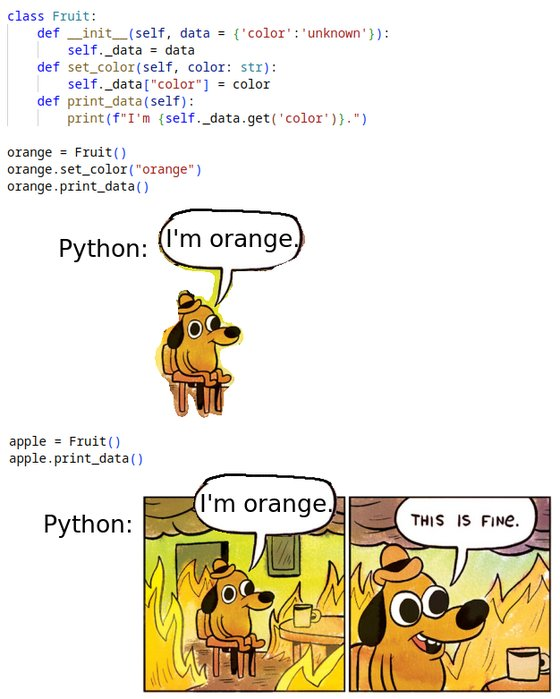

*Тот же общий холодильник, только другим путём: словарь `{'color': 'unknown'}` в значении по умолчанию создаётся один раз, когда Python читает `def`. Яблоко ничего не красило, но оно оранжевое: апельсин уже лежит в общем холодильнике. Лечится так же, как наш `Trip`: свой словарь каждому — внутри `__init__`.*

*Cũng là tủ lạnh chung đó, chỉ là đi đường khác: dictionary `{'color': 'unknown'}` ở giá trị mặc định chỉ được tạo một lần, khi Python đọc `def`. Quả táo chẳng sơn gì cả, nhưng nó màu cam: quả cam đã nằm trong tủ lạnh chung rồi. Chữa theo cách như với `Trip` của ta: mỗi object một dictionary riêng — bên trong `__init__`.*

## 🎤 Угадай вывод: банка для чаевых

*🎤 Контрольный вопрос №1 — по нему решаете, ускоряться ли. Если зал уверенно и правильно отвечает — дальше подразделы с ⏩ пропускаем.*

```python
class Jar:
    amount = 0


a = Jar()
b = a
b.amount = 7
print(a.amount, Jar.amount)
```

Банка для чаевых. Что напечатается: `7 7`, `7 0`, `0 0` или ошибка?

## 🎤 Đoán output: hũ tiền tip

*🎤 Câu hỏi kiểm tra số 1 — dựa vào đó ta quyết định có tăng tốc hay không. Nếu cả lớp trả lời chắc chắn và đúng — các mục con có ⏩ ta bỏ qua.*

```python
class Jar:
    amount = 0


a = Jar()
b = a
b.amount = 7
print(a.amount, Jar.amount)
```

Hũ tiền tip. Sẽ in ra: `7 7`, `7 0`, `0 0` hay lỗi?

In [16]:
class Jar:
    amount = 0


a = Jar()
b = a
b.amount = 7
print(a.amount, Jar.amount)
print(vars(a))

7 0
{'amount': 7}


`7 0`. Здесь сразу две ловушки. Первая: `a` и `b` — два ярлыка на одной банке, поэтому `a.amount` тоже семь. Вторая: `b.amount = 7` — это **присваивание**, а не изменение. Присваивание через объект создаёт атрибут у самого объекта, `vars(a)` это показывает. Атрибут класса `Jar.amount` никто не трогал, он заслонён, но цел.

Почему же со списком `members` вышло по-другому? Потому что там было `self.members.append(...)` — не присваивание, а изменение объекта, который нашёлся в классе. Это ровно то, что в Л3 мы называли «переприсвоить» и «друг покрасил дверь»: переклеить ярлык и изменить объект по ярлыку — разные операции.

`7 0`. Ở đây có ngay hai cái bẫy. Thứ nhất: `a` và `b` là hai nhãn trên cùng một cái hũ, nên `a.amount` cũng bằng bảy. Thứ hai: `b.amount = 7` là **phép gán**, không phải sự thay đổi. Gán qua object tạo attribute ở chính object đó, `vars(a)` cho thấy điều này. Class attribute `Jar.amount` không ai đụng tới, nó bị che đi, nhưng vẫn nguyên vẹn.

Vậy sao với list `members` lại ra khác? Vì ở đó là `self.members.append(...)` — không phải phép gán mà là thay đổi object tìm được trong class. Đây chính là điều mà ở B3 ta gọi là "gán lại" và "bạn sơn cửa hộ": dán lại nhãn và sửa object theo nhãn là hai thao tác khác nhau.

## ⏩ Атрибуты на лету и опечатка, которая не падает

*⏩ Если зал уверенно ответил на вопрос про банку — пропускаем, читаете сами.*

Python разрешает приклеить атрибут к объекту в любой момент, не только в `__init__`. Удобно? Смотрите, чем это оборачивается:

## ⏩ Attribute thêm "trên đường đi" và lỗi chính tả không báo lỗi

*⏩ Nếu cả lớp trả lời chắc câu hỏi về cái hũ — ta bỏ qua, các bạn tự đọc.*

Python cho phép dán attribute lên object bất kỳ lúc nào, không chỉ trong `__init__`. Tiện không? Xem nó dẫn tới gì:

In [17]:
water.ammount = 999          # опечатка: две «m»
print(water.amount, water.ammount)
print(vars(water))

300 999
{'payer': 'Граф Дебажный', 'amount': 300, 'reason': 'вода', 'ammount': 999}


Ни ошибки, ни предупреждения. Python молча создал **новый** атрибут `ammount`, а настоящая сумма осталась 300. В таблице расходов теперь два поля с похожими именами, и одно из них врёт. Такие опечатки ловят редактор с подсветкой и линтер `ruff` — ещё одна причина ими пользоваться.

А атрибут, приклеенный на лету, есть только у того объекта, к которому его приклеили. Ячейка падает специально:

Không lỗi, không cảnh báo. Python lặng lẽ tạo **attribute mới** `ammount`, còn số tiền thật vẫn là 300. Trong bảng chi tiêu giờ có hai trường tên na ná nhau, và một trong số đó nói dối. Lỗi chính tả như vậy được bắt bởi editor có highlight và linter `ruff` — thêm một lý do để dùng chúng.

Và attribute dán "trên đường đi" chỉ tồn tại ở object mà nó được dán lên. Ô này cố ý báo lỗi:

In [18]:
print(expense.ammount)   # ⚠️ упадёт специально

AttributeError: 'Expense' object has no attribute 'ammount'

`AttributeError: 'Expense' object has no attribute 'ammount'`. У `water` опечатка есть, у `expense` — нет. Объекты одного класса начали отличаться набором полей — именно поэтому все атрибуты принято заводить в `__init__`: открываешь его и видишь, из чего объект состоит. Уберём мусор, чтобы он не путал нас дальше:

`AttributeError: 'Expense' object has no attribute 'ammount'`. `water` có lỗi chính tả, `expense` thì không. Các object cùng class bắt đầu khác nhau về tập trường — chính vì thế người ta quy ước khai báo mọi attribute trong `__init__`: mở nó ra là thấy object gồm những gì. Dọn rác đi để nó không làm ta rối về sau:

In [19]:
del water.ammount
print(vars(water))

{'payer': 'Граф Дебажный', 'amount': 300, 'reason': 'вода'}


Чисто. `del` отклеивает ярлык — как `del print` в Л2, только теперь ярлык висел на объекте.

Sạch. `del` gỡ nhãn ra — như `del print` ở B2, chỉ là lần này nhãn gắn trên object.

# 3. Объект в обычном Python

Наш класс пока живёт в своём маленьком мире: чтобы узнать, что за трата, надо специально звать `describe()`. А встроенные типы Python отвечают на `print`, `len`, `str` сами. Научим наши объекты тому же.

# 3. Object trong Python thông thường

Class của ta tạm sống trong thế giới nhỏ của nó: để biết khoản chi là gì, phải cố ý gọi `describe()`. Còn các kiểu built-in của Python tự đáp ứng `print`, `len`, `str`. Hãy dạy object của ta làm như vậy.

## `object at 0x…`: Python не знает, как вас показать

Что будет, если просто напечатать трату?

## `object at 0x…`: Python không biết cách hiển thị bạn

Chuyện gì xảy ra nếu chỉ đơn giản in khoản chi ra?

In [20]:
print(expense)
print([expense, water])

[<__main__.Expense object at 0x7434a435acf0>, <__main__.Expense object at 0x7434a4e5dbd0>]


`<__main__.Expense object at 0x…>` — и шестнадцатеричный адрес, у вас он будет другой. Перевожу: «объект класса `Expense` из главной программы, живёт вот по этому адресу в памяти». Абсолютно честно и абсолютно бесполезно. Это как спросить у дежурного, кто лежит в палате, и услышать «пациент, койка номер 0x7f3a». Python не знает, как показывать ваш объект, — вы ему не сказали.

`<__main__.Expense object at 0x…>` — và một địa chỉ hệ thập lục phân, của bạn sẽ khác. Dịch ra: "object của class `Expense` từ chương trình chính, sống ở địa chỉ này trong bộ nhớ". Hoàn toàn trung thực và hoàn toàn vô dụng. Giống như hỏi trực ban xem trong phòng bệnh có ai, rồi nghe "bệnh nhân, giường số 0x7f3a". Python không biết hiển thị object của bạn thế nào — bạn chưa bảo nó.

## `__repr__` и `__str__`

Сказать можно двумя специальными методами. Таких методов с двойными подчёркиваниями по бокам мы уже видели один — `__init__`. Их называют «dunder-методами», от *double underscore*, или «магическими». Магии в них нет: это просто имена, которые Python вызывает сам в определённых ситуациях.

- **`__str__`** — представление для человека. Его вызывают `print()`, `str()` и f-строки.
- **`__repr__`** — представление для разработчика: однозначное, чтобы при отладке было видно, что это за объект и с какими данными. Хороший `__repr__` по возможности выглядит как код, которым такой объект можно создать; если так не получается — хотя бы показывает главное, как наш журнал чуть ниже.

Запомнить проще так: `str` — что написали родственникам, `repr` — что оставили дежурному инженеру. Родственникам — «Бобр Иваныч заплатил за уголь 1200 рублей». Инженеру — точный состав, с кавычками и типами.

Добавим оба метода. Класс переопределяем целиком — и это его финальная версия на первую половину лекции:

## `__repr__` và `__str__`

Có hai method đặc biệt để bảo nó. Method có hai gạch dưới hai bên như vậy ta đã thấy một cái — `__init__`. Chúng được gọi là "dunder method", từ *double underscore*, hay "magic method". Trong chúng không có phép màu: đó chỉ là những cái tên mà Python tự gọi trong những tình huống nhất định.

- **`__str__`** — biểu diễn cho con người. Được gọi bởi `print()`, `str()` và f-string.
- **`__repr__`** — biểu diễn cho developer: rõ ràng, không nhập nhằng, để khi debug thấy được đây là object gì và với dữ liệu nào. Một `__repr__` tốt, nếu có thể, trông như đoạn code dùng để tạo ra object đó; nếu không được — thì ít nhất cho thấy điều chính, như cuốn sổ của ta ngay bên dưới.

Nhớ cho dễ: `str` — điều ta viết cho người thân, `repr` — điều ta để lại cho kỹ sư trực. Cho người thân — "Bobr Ivanych đã trả 1200 rúp cho than củi". Cho kỹ sư — thành phần chính xác, có dấu ngoặc kép và kiểu dữ liệu.

Thêm cả hai method. Định nghĩa lại toàn bộ class — và đây là phiên bản cuối của nó cho nửa đầu bài giảng:

In [21]:
class Expense:
    def __init__(self, payer: str, amount: int, reason: str):
        self.payer = payer      # кто заплатил
        self.amount = amount    # целые рубли
        self.reason = reason    # за что

    def describe(self) -> str:
        return f"{self.payer}: {self.reason} — {self.amount} ₽"

    def __repr__(self) -> str:
        return f"Expense({self.payer!r}, {self.amount!r}, {self.reason!r})"

    def __str__(self) -> str:
        return self.describe()


expense = Expense("Бобр Иваныч", 1200, "уголь для последнего шашлыка")
water = Expense("Граф Дебажный", 300, "вода")
print(expense)
print(repr(expense))
print(f"В чате: {water}")

Бобр Иваныч: уголь для последнего шашлыка — 1200 ₽
Expense('Бобр Иваныч', 1200, 'уголь для последнего шашлыка')
В чате: Граф Дебажный: вода — 300 ₽


Помните правило из прошлого раздела: класс переопределили — объекты пересоздали. Старые `expense` и `water` были сделаны по старому бланку и про `__repr__` ничего не знают.

Теперь `print` и f-строка зовут `__str__` и получают человеческий текст. `repr()` зовёт `__repr__`. А `!r` внутри f-строки — это «подставь `repr` значения, а не `str`»: поэтому имя и причина в кавычках, а сумма — без. Именно по кавычкам видно, что `1200` — число, а не строка `"1200"`. Для дежурного инженера в три часа ночи разница — как между «пациент дышит» и «на мониторе нарисовано, что дышит».

Где ещё срабатывает `__repr__`? В Jupyter, если объект стоит последней строкой ячейки без `print`:

Nhớ quy tắc ở mục trước: định nghĩa lại class thì tạo lại object. `expense` và `water` cũ được tạo theo mẫu cũ và không biết gì về `__repr__`.

Giờ `print` và f-string gọi `__str__` và nhận được văn bản cho con người. `repr()` gọi `__repr__`. Còn `!r` trong f-string nghĩa là "thay giá trị bằng `repr` chứ không phải `str`": vì thế tên và lý do nằm trong dấu ngoặc kép, còn số tiền thì không. Chính nhờ dấu ngoặc kép mà thấy `1200` là số chứ không phải string `"1200"`. Với kỹ sư trực lúc ba giờ sáng, khác biệt giống như giữa "bệnh nhân đang thở" và "trên màn hình vẽ là đang thở".

`__repr__` còn được kích hoạt ở đâu nữa? Trong Jupyter, nếu object đứng ở dòng cuối ô và không có `print`:

In [22]:
water

Expense('Граф Дебажный', 300, 'вода')

И внутри коллекций:

Và bên trong các collection:

In [23]:
print([expense, water])

[Expense('Бобр Иваныч', 1200, 'уголь для последнего шашлыка'), Expense('Граф Дебажный', 300, 'вода')]


Список печатает свои элементы через `repr`, а не через `str`. Это сделано специально: в списке `['1', 1]` вы должны видеть, что первый элемент — строка, а второй — число. Поэтому если писать только один из двух методов, пишите `__repr__`: без `__str__` Python возьмёт его и для `print`. А наоборот — не возьмёт.

List in các phần tử của nó qua `repr`, không phải `str`. Điều này là có chủ ý: trong list `['1', 1]` bạn phải thấy phần tử đầu là string còn phần tử hai là số. Vì thế nếu chỉ viết một trong hai method thì hãy viết `__repr__`: không có `__str__` thì Python sẽ lấy nó cho cả `print`. Còn ngược lại — thì không.

## Грабли: `__str__` есть, а в списке опять адрес

Вот как это выглядит, когда написан только `__str__`:

## Cạm bẫy: có `__str__` mà trong list lại là địa chỉ

Đây là khi chỉ viết `__str__`:

In [24]:
class Bill:
    def __str__(self):
        return "Чек на поминки дедлайна"


bill = Bill()
print(bill)
print([bill])

Чек на поминки дедлайна


Первая строка — красиво, вторая — снова `object at 0x…`. Ошибки нет, но при отладке списка трат вы увидите стену адресов. Лекарство — `__repr__`.

Dòng đầu — đẹp, dòng hai — lại `object at 0x…`. Không có lỗi, nhưng khi debug list khoản chi bạn sẽ thấy cả bức tường địa chỉ. Thuốc chữa — `__repr__`.

## Грабли: `__str__` печатает вместо того, чтобы вернуть

Контракт у `__str__` и `__repr__` один: **вернуть** строку. Не напечатать — вернуть. Ячейка падает специально:

## Cạm bẫy: `__str__` in ra thay vì trả về

Hợp đồng của `__str__` và `__repr__` chỉ có một: **trả về** string. Không phải in — mà trả về. Ô này cố ý báo lỗi:

In [25]:
class Bill:
    def __str__(self):
        print("Чек на поминки дедлайна")   # напечатали, а вернули None


print(Bill())   # ⚠️ упадёт специально

Чек на поминки дедлайна


TypeError: __str__ returned non-string (type NoneType)

Сначала текст всё-таки появился: `print` внутри метода честно отработал. А потом — `TypeError: __str__ returned non-string (type NoneType)`. Метод ничего не вернул, значит вернул `None`, а внешнему `print` нужна строка. Та же история, что `return` против `print` в Л3: функция, которая кричит в пустоту вместо того, чтобы отдать бумажку с ответом.

Lúc đầu văn bản vẫn xuất hiện: `print` bên trong method đã chạy đàng hoàng. Rồi sau đó — `TypeError: __str__ returned non-string (type NoneType)`. Method không trả về gì, tức là trả `None`, mà `print` bên ngoài cần một string. Cùng chuyện với `return` so với `print` ở B3: hàm hét vào hư không thay vì đưa ra tờ giấy có câu trả lời.

## `__len__`: научим объект отвечать на `len()`

Теперь заведём журнал поездки — объект, который хранит много трат. Пока самый простой: название, список и метод `add`. И научим его отвечать на `len()` — сколько в журнале трат:

## `__len__`: dạy object trả lời `len()`

Giờ tạo sổ chuyến đi — object lưu nhiều khoản chi. Tạm thời đơn giản nhất: tên, list và method `add`. Và dạy nó trả lời `len()` — trong sổ có bao nhiêu khoản chi:

In [26]:
class TripLedger:
    def __init__(self, title: str):
        self.title = title
        self.expenses = []

    def add(self, expense: Expense) -> None:
        self.expenses.append(expense)

    def __len__(self) -> int:
        return len(self.expenses)

    def __repr__(self) -> str:
        return f"TripLedger({self.title!r}, трат: {len(self)})"


ledger = TripLedger("Последний шашлык")
ledger.add(expense)
ledger.add(water)

print(len(ledger))
print(ledger.__len__())
print(ledger)

2
2
TripLedger('Последний шашлык', трат: 2)


`len(ledger)` — два. Смотрите, что произошло: функция `len()` ничего не знает про журналы. Она просто вызывает у объекта метод `__len__` — вторая строка показывает, что результат тот же. Внутри `__repr__` мы и сами пользуемся этим: `len(self)`.

Это и есть главная идея dunder-методов. В Python есть **протоколы** — договорённости вида «если у объекта есть метод `__len__`, ему можно сказать `len()`». Строка, список и словарь отвечают на `len()` не потому, что `len` знает каждого в лицо, а потому, что у каждого есть свой `__len__`. Теперь он есть и у нашего журнала. Без него `len(ledger)` упал бы с `TypeError: object of type 'TripLedger' has no len()`.

`len(ledger)` — hai. Xem chuyện gì đã xảy ra: hàm `len()` không biết gì về các cuốn sổ. Nó chỉ đơn giản gọi method `__len__` của object — dòng thứ hai cho thấy kết quả như nhau. Bên trong `__repr__` ta cũng tự dùng điều này: `len(self)`.

Đây chính là ý tưởng chính của dunder method. Trong Python có các **protocol** — quy ước dạng "nếu object có method `__len__` thì có thể gọi `len()` với nó". String, list và dictionary trả lời `len()` không phải vì `len` biết mặt từng loại, mà vì mỗi loại có `__len__` riêng. Giờ cuốn sổ của ta cũng có. Không có nó, `len(ledger)` sẽ lỗi `TypeError: object of type 'TripLedger' has no len()`.

## Два одинаковых чека не равны

Создадим две одинаковые траты и сравним:

## Hai tờ hóa đơn giống nhau không bằng nhau

Tạo hai khoản chi giống hệt nhau và so sánh:

In [27]:
first = Expense("Бобр Иваныч", 1200, "уголь для последнего шашлыка")
second = Expense("Бобр Иваныч", 1200, "уголь для последнего шашлыка")

print(first == second)
print(first == first)

False
True


`False`, хотя данные совпадают до буквы. Без своего метода `__eq__` оператор `==` у наших объектов работает как `is`: равен только сам себе. Помните из Л2, что `==` спрашивает «равны ли значения», а `is` — «тот же ли это объект»? Для наших объектов Python не знает, что такое «равные значения», и откатывается к самому строгому варианту.

Писать `__eq__` руками можно, но там есть тонкости — о них в 📚 «Свои операторы» в конце тетрадки. А в разделе 10 его за нас напишет `@dataclass`, одной строкой.

`False`, dù dữ liệu trùng từng chữ. Không có method `__eq__` riêng, toán tử `==` ở object của ta hoạt động như `is`: chỉ bằng chính nó. Nhớ từ B2 rằng `==` hỏi "giá trị có bằng nhau không", còn `is` — "có phải cùng một object không"? Với object của ta, Python không biết "giá trị bằng nhau" là gì, và lùi về phương án nghiêm ngặt nhất.

Viết `__eq__` bằng tay thì được, nhưng có những tinh tế — chúng ở phần 📚 «Toán tử riêng» cuối notebook. Còn ở mục 10 `@dataclass` sẽ viết nó hộ ta chỉ bằng một dòng.

# 4. Композиция и инвариант

У нас есть журнал, а в журнале — траты. Объект, который **содержит** другие объекты и пользуется ими, — это и есть композиция. Журнал не является тратой и не является списком. Журнал **хранит** траты и следит за порядком. Вот про «следит за порядком» сейчас и поговорим.

# 4. Composition và invariant

Ta có cuốn sổ, và trong sổ có các khoản chi. Object **chứa** các object khác và sử dụng chúng chính là composition. Sổ không phải khoản chi và không phải list. Sổ **lưu** các khoản chi và giữ trật tự. Chính chuyện "giữ trật tự" ta sẽ bàn ngay bây giờ.

## Где живёт правило

Вспомните начало лекции: Граф Дебажный записал «моральный ущерб, минус пятьсот» мимо функции, прямо в словарь. Наш журнал от этого защищает?

## Quy tắc sống ở đâu

Nhớ lại đầu bài: Graf Debazhny ghi «tổn thất tinh thần, âm năm trăm» bỏ qua hàm, trực tiếp vào dictionary. Cuốn sổ của ta có bảo vệ khỏi điều đó không?

In [28]:
ledger.expenses.append(Expense("Граф Дебажный", -500, "моральный ущерб"))
print(ledger)
print(ledger.expenses[-1])

TripLedger('Последний шашлык', трат: 3)
Граф Дебажный: моральный ущерб — -500 ₽


Не защищает. Список `expenses` лежит на виду, и `append` в него может сделать кто угодно. Мы завели класс, а проблема из словарей переехала вместе с нами.

Правило «отрицательную трату не принимаем» — это **инвариант**: условие, которое должно быть верным для журнала всегда, в любой момент его жизни. И главный вопрос проектирования звучит так: **где гарантируется инвариант?** Правило должно жить в коде, а не в устной традиции племени и не в сообщении «пожалуйста, не пишите минусы» в общем чате.

Ответ: в одном-единственном месте, через которое проходят все траты, — в методе `add`. А сам список убираем с витрины:

Không bảo vệ. List `expenses` nằm lộ thiên, và ai cũng có thể `append` vào đó. Ta đã tạo class, mà vấn đề từ dictionary đã chuyển nhà theo ta.

Quy tắc "không nhận khoản chi âm" là một **invariant**: điều kiện luôn phải đúng với cuốn sổ, ở bất kỳ thời điểm nào của vòng đời nó. Và câu hỏi thiết kế chính là: **invariant được đảm bảo ở đâu?** Quy tắc phải sống trong code, chứ không phải trong truyền thống truyền miệng của bộ lạc, càng không phải trong tin nhắn "xin đừng ghi số âm" ở chat chung.

Câu trả lời: ở một nơi duy nhất mà mọi khoản chi đều đi qua — trong method `add`. Còn list thì gỡ khỏi tủ trưng bày:

In [29]:
class TripLedger:
    def __init__(self, title: str):
        self.title = title
        self._expenses = []      # служебное: снаружи не трогать

    def add(self, expense: Expense) -> None:
        if expense.amount <= 0:
            raise ValueError(f"Сумма должна быть положительной: {expense.amount}")
        self._expenses.append(expense)

    def total(self) -> int:
        total = 0
        for expense in self._expenses:
            total += expense.amount
        return total

    def __len__(self) -> int:
        return len(self._expenses)

    def __repr__(self) -> str:
        return f"TripLedger({self.title!r}, трат: {len(self)})"


ledger = TripLedger("Последний шашлык")
ledger.add(expense)
ledger.add(water)
print(ledger, ledger.total())

TripLedger('Последний шашлык', трат: 2) 1500


Две траты, полторы тысячи. Журнал пересоздали — старый, с моральным ущербом, ушёл вместе со старым классом. Заодно появился метод `total()`: сумма считается в одном месте, и если правило подсчёта поменяется, менять придётся тоже в одном месте.

Теперь Граф пробует ещё раз, уже через `add`. Ячейка падает специально:

Hai khoản chi, một nghìn rưỡi. Cuốn sổ được tạo lại — cái cũ, có tổn thất tinh thần, đã biến mất cùng class cũ. Nhân tiện có thêm method `total()`: tổng được tính ở một chỗ, và nếu quy tắc tính thay đổi thì cũng chỉ phải sửa ở một chỗ.

Giờ Graf thử lần nữa, đã qua `add`. Ô này cố ý báo lỗi:

In [30]:
ledger.add(Expense("Граф Дебажный", -500, "моральный ущерб"))   # ⚠️ упадёт специально

ValueError: Сумма должна быть положительной: -500

`ValueError: Сумма должна быть положительной: -500`. Журнал отказался. И проверьте: в журнале по-прежнему две траты — ошибка случилась **до** `append`, мусор внутрь не попал:

`ValueError: Сумма должна быть положительной: -500`. Cuốn sổ từ chối. Và kiểm tra: trong sổ vẫn là hai khoản chi — lỗi xảy ra **trước** `append`, rác không lọt vào trong:

In [31]:
print(ledger, ledger.total())

TripLedger('Последний шашлык', трат: 2) 1500


## `_expenses`: табличка «служебное помещение»

Что значит подчёркивание в начале `_expenses`? Для Python — ничего. Это договорённость между программистами: «это внутреннее устройство класса, снаружи не трогайте, оно может поменяться без предупреждения». Python вас не остановит:

## `_expenses`: tấm biển "khu vực kỹ thuật"

Dấu gạch dưới ở đầu `_expenses` nghĩa là gì? Với Python — không gì cả. Đó là quy ước giữa các lập trình viên: "đây là cấu trúc nội bộ của class, bên ngoài đừng đụng vào, nó có thể thay đổi không báo trước". Python sẽ không ngăn bạn:

In [32]:
print(ledger._expenses)

[Expense('Бобр Иваныч', 1200, 'уголь для последнего шашлыка'), Expense('Граф Дебажный', 300, 'вода')]


Прочитали — и ничего не случилось. Подчёркивание — это табличка «служебное помещение» на двери. Не бетонная стена и не охрана с автоматом. Зайти можно, но если внутри вас ударит током — претензии не принимаются. Кто пишет `ledger._expenses.append(...)` в обход `add`, тот сам расписался, что знает, что делает.

В других языках вам расскажут про `private` и «настоящую инкапсуляцию». В Python инкапсуляция — это не замки. Это **инвариант** плюс **публичный метод**, который его соблюдает, плюс **табличка** на всём остальном. Есть ещё два подчёркивания, `__x`, — и вот они уже кое-что делают с именем, но приватности тоже не дают. Подробности — в 📚 «`__x` и name mangling» в конце тетрадки.

Đọc được — và không có chuyện gì xảy ra. Dấu gạch dưới là tấm biển "khu vực kỹ thuật" trên cửa. Không phải bức tường bê tông, cũng không phải bảo vệ cầm súng tự động. Vào được, nhưng nếu bên trong bạn bị điện giật — không nhận khiếu nại. Ai viết `ledger._expenses.append(...)` bỏ qua `add`, người đó tự ký xác nhận rằng mình biết mình đang làm gì.

Ở các ngôn ngữ khác người ta sẽ kể cho bạn về `private` và "encapsulation thật sự". Trong Python encapsulation không phải ổ khóa. Đó là **invariant** cộng với **public method** tuân thủ nó, cộng với **tấm biển** trên mọi thứ còn lại. Còn có hai dấu gạch dưới, `__x`, — và chúng đã làm gì đó với tên, nhưng cũng không đem lại tính private. Chi tiết — ở phần 📚 «`__x` và name mangling» cuối notebook.

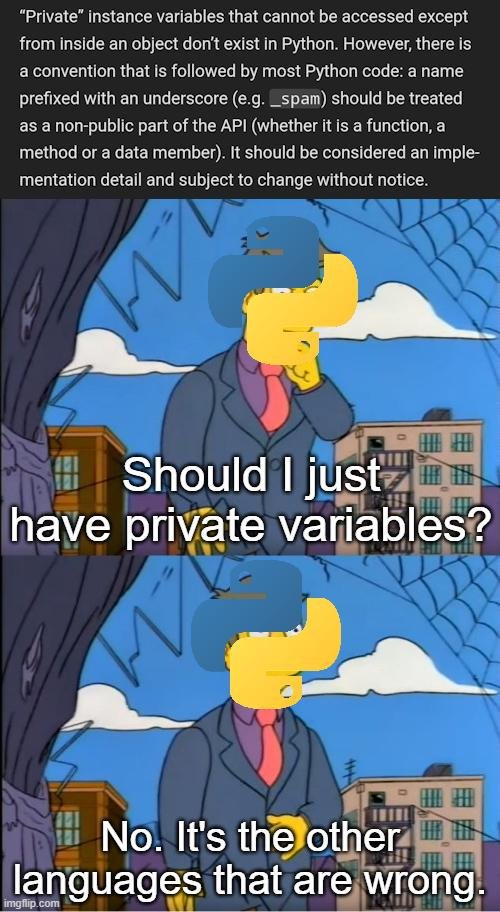

*Сверху — честная цитата из документации Python: приватных переменных нет, есть соглашение про подчёркивание. Скиннер на секунду засомневался, но быстро нашёл виноватых. `_expenses` — не сейф, а табличка на незапертой двери. Python считает вас взрослыми людьми. Python, как обычно, оптимист.*

*Ở trên — trích dẫn trung thực từ tài liệu Python: không có biến private, chỉ có quy ước về dấu gạch dưới. Skinner thoáng nghi ngờ, nhưng nhanh chóng tìm ra thủ phạm. `_expenses` không phải két sắt mà là tấm biển trên cánh cửa không khóa. Python coi các bạn là người trưởng thành. Python, như thường lệ, là người lạc quan.*

## Композиция или наследование

Возникает соблазн: журнал же почти список? Давайте унаследуем журнал от `list`, и все методы списка достанутся бесплатно. Наследование мы подробно разберём в следующем разделе, а пока посмотрите, что именно достанется бесплатно:

## Composition hay inheritance

Cám dỗ xuất hiện: sổ chẳng phải gần như là list sao? Hãy cho sổ kế thừa từ `list`, mọi method của list sẽ có sẵn miễn phí. Inheritance ta sẽ phân tích kỹ ở mục sau, còn bây giờ hãy xem chính xác cái gì được tặng miễn phí:

In [33]:
class BadLedger(list):   # «журнал — это список», в скобках — от кого наследуем
    def add(self, expense):
        if expense.amount <= 0:
            raise ValueError("Сумма должна быть положительной")
        self.append(expense)


bad = BadLedger()
bad.append(Expense("Граф Дебажный", -500, "моральный ущерб"))   # мимо add, без ошибки
print(len(bad), bad[0])
print([name for name in dir(list) if not name.startswith("_")])

1 Граф Дебажный: моральный ущерб — -500 ₽
['append', 'clear', 'copy', 'count', 'extend', 'index', 'insert', 'pop', 'remove', 'reverse', 'sort']


Вместе со списком мы унаследовали одиннадцать публичных методов. Три из них — `append`, `extend`, `insert` — прямые чёрные ходы мимо нашего `add`. Ещё два, `bad[0] = …` и `bad += […]`, в этом списке даже не видны: они спрятаны в методах с подчёркиваниями. Ставить охрану у парадного входа и оставить открытыми пять окон — так себе инвариант.

Правило применимости простое. **Наследование** — когда новый объект действительно **является** разновидностью старого и может использоваться везде, где используется старый. **Композиция** — когда объект **использует** другие объекты. У машины есть двигатель. Машина не наследуется от двигателя — даже если после ремонта от неё остался только он. Журнал хранит список трат, но журнал — не список: у списка нет правил, а у журнала есть.

Cùng với list ta thừa kế mười một public method. Ba trong số đó — `append`, `extend`, `insert` — là cửa sau trực tiếp, đi vòng qua `add` của ta. Hai cái nữa, `bad[0] = …` và `bad += […]`, thậm chí không hiện trong danh sách này: chúng ẩn trong các method có gạch dưới. Đặt bảo vệ ở cửa chính mà để mở năm ô cửa sổ — invariant kiểu đó thì cũng tạm.

Quy tắc áp dụng đơn giản. **Inheritance** — khi object mới thực sự **là** một biến thể của object cũ và có thể dùng ở mọi nơi dùng object cũ. **Composition** — khi object **dùng** các object khác. Xe có động cơ. Xe không kế thừa từ động cơ — dù sau sửa chữa chỉ còn lại mỗi nó. Sổ lưu list khoản chi, nhưng sổ không phải list: list không có quy tắc, còn sổ thì có.

## Утиная типизация: одна функция — разные объекты

Обратная сторона протоколов из прошлого раздела. Функции `len()` всё равно, кто перед ней — строка, словарь или журнал. Ей важно только одно: умеет ли объект отвечать на `len()`.

## Duck typing: một hàm — nhiều object

Mặt kia của protocol ở mục trước. Hàm `len()` không quan tâm trước mặt nó là string, dictionary hay cuốn sổ. Nó chỉ quan tâm một điều: object có biết trả lời `len()` không.

In [34]:
for thing in ["шашлык", ["уголь", "вода"], {"Бобр": 1200}, ledger]:
    print(f"{type(thing).__name__:10} {len(thing)}")

str        6
list       2
dict       1
TripLedger 2


Четыре совершенно разных типа, ни одного общего предка, кроме `object`, — и все отвечают. Это называется **утиная типизация**: если оно ходит как утка и крякает как утка — значит, утка. Python не спрашивает у объекта паспорт, он спрашивает «а крякнуть можешь?». Как объявить «умеет `len`» формально, чтобы это проверял редактор, — в 📚 `Protocol` в конце тетрадки.

Bốn kiểu hoàn toàn khác nhau, không có tổ tiên chung nào ngoài `object` — và tất cả đều trả lời. Đó gọi là **duck typing**: nếu nó đi như vịt và kêu như vịt — thì nó là vịt. Python không hỏi object xem hộ chiếu, nó hỏi "bạn kêu được không?". Cách khai báo chính thức "biết `len`" để editor kiểm tra — ở phần 📚 `Protocol` cuối notebook.

## ⏩ Устарело — не значит неправильно

*⏩ Если зал уверенно ответил на вопрос про банку — пропускаем, читаете сами.*

В старых учебниках, в чужом коде и в ответах ИИ вы встретите классы, написанные по-другому. Не всё старое — ошибка. Вот как к этому относиться:

| Встретили | Что это | Что делаем |
|---|---|---|
| `class Foo(object):` | так писали во времена Python 2 | в Python 3 это лишнее, но работает. Пишем `class Foo:` |
| `from typing import List, Dict` | стиль до Python 3.9 | работает, но у нас 3.13: пишем `list[str]`, `dict[str, int]` |
| геттер и сеттер на каждое поле: `get_amount()`, `set_amount()` | привычка из Java | начинаем с обычного атрибута; `property` — когда появится причина (раздел 11) |
| все поля с двумя подчёркиваниями, `self.__amount` | «так приватнее» | это переименование имени, а не защита; хватит одного `_` |
| наследование, чтобы не копировать три строки | «переиспользование кода» | хватит функции или композиции |

Встретили такое в сгенерированном коде — не паникуйте и не переписывайте всё подряд. Работает — значит работает. Но в свой новый код это не тащите.

## ⏩ Lỗi thời — không có nghĩa là sai

*⏩ Nếu cả lớp trả lời chắc câu hỏi về cái hũ — ta bỏ qua, các bạn tự đọc.*

Trong giáo trình cũ, trong code của người khác và trong câu trả lời của AI, bạn sẽ gặp những class được viết theo cách khác. Không phải cái gì cũ cũng sai. Cách đối xử với chúng:

| Gặp phải | Đó là gì | Ta làm gì |
|---|---|---|
| `class Foo(object):` | cách viết thời Python 2 | trong Python 3 là thừa, nhưng vẫn chạy. Ta viết `class Foo:` |
| `from typing import List, Dict` | style trước Python 3.9 | vẫn chạy, nhưng ta dùng 3.13: viết `list[str]`, `dict[str, int]` |
| getter và setter cho mỗi trường: `get_amount()`, `set_amount()` | thói quen từ Java | bắt đầu bằng attribute thường; `property` — khi có lý do (mục 11) |
| mọi trường đều có hai gạch dưới, `self.__amount` | "như vậy private hơn" | đây là đổi tên, không phải bảo vệ; một `_` là đủ |
| inheritance để khỏi copy ba dòng | "tái sử dụng code" | một hàm hoặc composition là đủ |

Gặp những thứ này trong code do AI sinh ra — đừng hoảng và đừng viết lại tất cả. Chạy được là chạy được. Nhưng đừng mang chúng vào code mới của mình.

# 5. Наследование там, где уместно

В учебниках наследование объясняют на кошках и собаках: `Animal`, от него `Cat` и `Dog`. Мило, но кошек вы будете писать примерно никогда. А вот где наследование нужно прямо сейчас — **свои исключения**.

# 5. Inheritance ở chỗ thích hợp

Trong giáo trình, inheritance được giải thích bằng mèo và chó: `Animal`, từ đó có `Cat` và `Dog`. Dễ thương, nhưng bạn hầu như sẽ không bao giờ viết code về mèo. Còn chỗ cần inheritance ngay bây giờ là — **exception riêng**.

## Своё исключение

Наш журнал бросает `ValueError`. Это честно, но неудобно: `ValueError` бросает половина стандартной библиотеки, от `int("сорок два")` до `fromisoformat` с 02:61. Если код вокруг журнала поймает `ValueError`, он поймает заодно и чужие ошибки, которые ловить не собирался. Хочется сказать точно: «беда именно журнала».

В Л3 вы видели родословную ошибок: `ZeroDivisionError` — частный случай `ArithmeticError`, тот — частный случай `Exception`. Встроимся в эту родословную. Заведём общего предка для всех бед журнала и конкретную беду — «неверная трата»:

## Exception riêng

Cuốn sổ của ta ném `ValueError`. Thế là trung thực, nhưng bất tiện: `ValueError` được ném bởi nửa thư viện chuẩn, từ `int("сорок два")` đến `fromisoformat` với 02:61. Nếu code quanh cuốn sổ bắt `ValueError`, nó sẽ bắt luôn cả các lỗi của người khác mà nó không định bắt. Ta muốn nói chính xác: "rắc rối chính của cuốn sổ".

Ở B3 bạn đã thấy "gia phả" của các lỗi: `ZeroDivisionError` là trường hợp riêng của `ArithmeticError`, nó lại là trường hợp riêng của `Exception`. Ta sẽ hòa vào gia phả đó. Tạo một tổ tiên chung cho mọi rắc rối của cuốn sổ và một rắc rối cụ thể — "khoản chi không hợp lệ":

In [35]:
class LedgerError(Exception):
    """Любая беда журнала трат."""


class InvalidExpense(LedgerError):
    def __init__(self, amount):
        self.amount = amount
        super().__init__(f"Сумма должна быть положительной: {amount}")


print(issubclass(InvalidExpense, LedgerError), issubclass(InvalidExpense, Exception))

True True


Два `True`: `issubclass` спрашивает «является ли первый класс потомком второго» — и наша ошибка оказалась потомком и `LedgerError`, и `Exception`. Разбираем, почему. `class LedgerError(Exception):` — в скобках указан **родитель**, базовый класс. `LedgerError` получает всё, что умеет `Exception`: его можно бросить через `raise`, поймать через `except`, у него есть текст. Тело класса — одна строка документации в тройных кавычках, и больше ничего не нужно: всё остальное унаследовано. Такие пустые классы-исключения — норма, их смысл в самом имени и месте в родословной.

`InvalidExpense(LedgerError)` — потомок `LedgerError`, а значит, внук `Exception`. У него свой `__init__`: он запоминает сумму в атрибуте `amount` — тому, кто поймает ошибку, может пригодиться не только текст, но и само число. А потом вызывает `super().__init__(...)` — передаёт текст сообщения дальше по родословной, чтобы базовый класс сделал свою часть работы и ошибка печаталась с этим текстом.

Теперь финальная версия журнала на первую половину лекции: вместо `ValueError` — наше исключение. Остальное не меняется. Журнал пересоздаём и кладём в него те же две траты:

Hai `True`: `issubclass` hỏi "class thứ nhất có phải hậu duệ của class thứ hai không" — và lỗi của ta hóa ra là hậu duệ của cả `LedgerError` lẫn `Exception`. Phân tích vì sao. `class LedgerError(Exception):` — trong ngoặc là **cha**, base class. `LedgerError` có tất cả những gì `Exception` biết làm: có thể ném bằng `raise`, bắt bằng `except`, có văn bản. Thân class chỉ là một dòng docstring trong ngoặc kép ba, và không cần gì thêm: mọi thứ còn lại đã được kế thừa. Những class exception rỗng như vậy là bình thường, ý nghĩa của chúng nằm ở chính cái tên và vị trí trong gia phả.

`InvalidExpense(LedgerError)` — hậu duệ của `LedgerError`, tức là cháu của `Exception`. Nó có `__init__` riêng: lưu số tiền vào attribute `amount` — người bắt lỗi có thể cần không chỉ văn bản mà cả con số. Rồi nó gọi `super().__init__(...)` — chuyển văn bản thông báo tiếp lên gia phả, để base class làm phần việc của mình và lỗi được in cùng văn bản đó.

Giờ là phiên bản cuối của cuốn sổ cho nửa đầu bài giảng: thay vì `ValueError` — exception của ta. Phần còn lại không đổi. Tạo lại sổ và bỏ vào đó hai khoản chi như cũ:

In [36]:
class TripLedger:
    def __init__(self, title: str):
        self.title = title
        self._expenses = []

    def add(self, expense: Expense) -> None:
        if expense.amount <= 0:
            raise InvalidExpense(expense.amount)
        self._expenses.append(expense)

    def total(self) -> int:
        total = 0
        for expense in self._expenses:
            total += expense.amount
        return total

    def __len__(self) -> int:
        return len(self._expenses)

    def __repr__(self) -> str:
        return f"TripLedger({self.title!r}, трат: {len(self)})"


ledger = TripLedger("Последний шашлык")
ledger.add(Expense("Бобр Иваныч", 1200, "уголь для последнего шашлыка"))
ledger.add(Expense("Граф Дебажный", 300, "вода"))
print(ledger, ledger.total())

TripLedger('Последний шашлык', трат: 2) 1500


Граф, разумеется, не сдаётся. Сначала без всякой защиты — посмотрим, как наша ошибка выглядит в трейсбеке. Ячейка падает специально:

Graf, tất nhiên, không bỏ cuộc. Đầu tiên là không có bảo vệ gì — xem lỗi của ta trông thế nào trong traceback. Ô này cố ý báo lỗi:

In [37]:
ledger.add(Expense("Граф Дебажный", -500, "моральный ущерб"))   # ⚠️ упадёт специально

InvalidExpense: Сумма должна быть положительной: -500

Последняя строка трейсбека: `InvalidExpense: Сумма должна быть положительной: -500`. Имя нашего класса и наш текст — тот, что мы передали в `super().__init__`. Выглядит как родная ошибка Python — она и есть родная, просто младшая ветка семьи.

А теперь главное, ради чего всё затевалось. Ловим **предка**:

Dòng cuối của traceback: `InvalidExpense: Сумма должна быть положительной: -500`. Tên class của ta và văn bản của ta — cái mà ta đã truyền vào `super().__init__`. Trông như lỗi "ruột" của Python — và đúng là ruột, chỉ là nhánh trẻ của gia đình.

Còn giờ là điều chính khiến ta bày ra tất cả. Bắt **tổ tiên**:

In [38]:
try:
    ledger.add(Expense("Граф Дебажный", -500, "моральный ущерб"))
except LedgerError as error:
    print(f"Журнал отказал: {type(error).__name__}: {error}")
    print(f"Сумма из ошибки: {error.amount}")

print(ledger, ledger.total())

Журнал отказал: InvalidExpense: Сумма должна быть положительной: -500
Сумма из ошибки: -500
TripLedger('Последний шашлык', трат: 2) 1500


Мы написали `except LedgerError`, а бросили `InvalidExpense` — и поймали. Как в Л3: `except` ловит указанный класс **и всех его потомков**. Когда у журнала появятся новые беды — «трата из чужой поездки», «журнал закрыт», — вы заведёте новые классы-потомки `LedgerError`, а код, который ловит `LedgerError`, менять не придётся. И при этом чужой `ValueError` из какого-нибудь `int()` пролетит мимо, как и должен. Атрибут `amount` тоже на месте, а журнал по-прежнему чистый: две траты, 1500.

Это и есть правильное место для наследования: `InvalidExpense` действительно **является** ошибкой журнала, а ошибка журнала действительно **является** исключением. Проверка «является» проходит на каждом шаге. А когда вы видите класс `BotWithDatabaseWithLoggerWithCache`, который наследуется от четырёх других, чтобы «переиспользовать код», — это уже не наследование, а крик о помощи.

Ta viết `except LedgerError`, mà ném `InvalidExpense` — và đã bắt được. Như ở B3: `except` bắt class được chỉ định **và mọi hậu duệ của nó**. Khi cuốn sổ có thêm rắc rối mới — "khoản chi từ chuyến đi khác", "sổ đã đóng", — bạn tạo class hậu duệ mới của `LedgerError`, còn code bắt `LedgerError` thì không phải sửa. Và đồng thời `ValueError` của người khác từ một `int()` nào đó sẽ bay qua, đúng như nó nên làm. Attribute `amount` cũng ở đó, còn cuốn sổ vẫn sạch: hai khoản chi, 1500.

Đây chính là chỗ đúng cho inheritance: `InvalidExpense` thực sự **là** lỗi của sổ, và lỗi của sổ thực sự **là** exception. Phép thử "là" đạt ở mỗi bước. Còn khi bạn thấy class `BotWithDatabaseWithLoggerWithCache` kế thừa từ bốn class khác để "tái sử dụng code" — đó không còn là inheritance mà là tiếng kêu cứu.

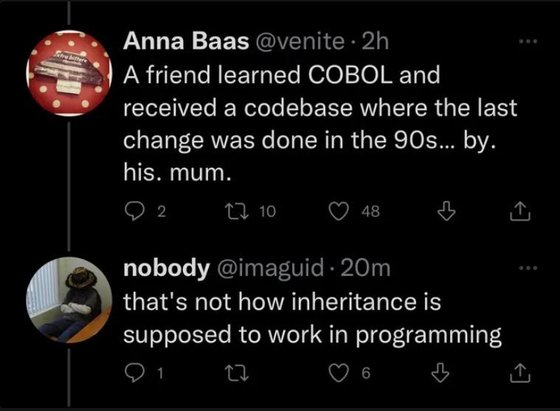

*Получить в работу код, который в девяностые последней правила мама, — наследование в житейском смысле. В программировании, как верно заметили в ответах, оно устроено иначе: потомок **является** разновидностью родителя. `InvalidExpense` является `LedgerError`. Мамин код вашей разновидностью не является — хотя чинить его, похоже, придётся вам.*

*Nhận vào làm việc đoạn code mà lần sửa cuối cùng từ những năm chín mươi là của mẹ — đó là inheritance theo nghĩa đời thường. Trong lập trình, như đã nhận xét đúng ở các phản hồi, nó được tổ chức khác: hậu duệ **là** một biến thể của cha. `InvalidExpense` là `LedgerError`. Code của mẹ không phải biến thể của bạn — dù có vẻ người phải sửa nó sẽ là bạn.*

## `__mro__`: обещание из прошлой лекции

В Л3 мы печатали родословную ошибок через `__mro__` и я обещал объяснить, что это такое. Возвращаю долг:

## `__mro__`: lời hứa từ bài trước

Ở B3 ta đã in "gia phả" của lỗi qua `__mro__` và tôi hứa sẽ giải thích nó là gì. Trả nợ:

In [39]:
print([cls.__name__ for cls in InvalidExpense.__mro__])
print([cls.__name__ for cls in TripLedger.__mro__])

['InvalidExpense', 'LedgerError', 'Exception', 'BaseException', 'object']
['TripLedger', 'object']


**MRO** — *Method Resolution Order*, порядок поиска методов. В Л3 я назвал это «родословной» — это была аналогия. Теперь точно: это **упорядоченный перечень классов (технически — кортеж), в котором Python ищет атрибут**, если не нашёл его у самого объекта. Помните, как Python искал `describe` — сначала у объекта, потом в классе? Если в классе тоже нет, он идёт дальше по этому списку, слева направо, и берёт первое, что нашёл. А в самом конце у всех стоит `object` — общий предок всех классов в Python. Даже у `TripLedger`, хотя мы никого в скобках не указывали.

Посмотрим, откуда наша ошибка берёт, например, умение превращаться в строку — метод `__str__`:

**MRO** — *Method Resolution Order*, thứ tự tìm method. Ở B3 tôi gọi nó là "gia phả" — đó là một phép ví von. Giờ nói chính xác: đây là **danh sách có thứ tự các class (về kỹ thuật là tuple) mà Python tìm attribute trong đó**, nếu không thấy ở chính object. Nhớ cách Python tìm `describe` — trước hết ở object, rồi ở class? Nếu trong class cũng không có, nó đi tiếp theo danh sách này, từ trái sang phải, và lấy cái đầu tiên tìm thấy. Còn ở cuối cùng của mọi class là `object` — tổ tiên chung của mọi class trong Python. Ngay cả `TripLedger`, dù ta không chỉ định ai trong ngoặc.

Xem lỗi của ta lấy từ đâu, chẳng hạn, khả năng biến thành string — method `__str__`:

In [40]:
for cls in InvalidExpense.__mro__:
    print(f"{cls.__name__:15} свой __str__: {'__str__' in vars(cls)}")

InvalidExpense  свой __str__: False
LedgerError     свой __str__: False
Exception       свой __str__: False
BaseException   свой __str__: True
object          свой __str__: True


Python идёт по списку: в `InvalidExpense` своего `__str__` нет, в `LedgerError` нет, в `Exception` нет — а в `BaseException` есть. Его и берёт. Поиск остановился на первой находке, до `object` дело не дошло.

И отсюда точный смысл `super()`. Это не «позвать папу по имени». `super()` значит: **продолжи поиск по MRO со следующего класса после моего**. В нашем `InvalidExpense` следующий — `LedgerError`; своего `__init__` у него нет, поиск идёт дальше и находит `__init__` у `Exception`. При одном родителе это совпадает с «вызвать родителя». При нескольких порядок хитрее, но в этом курсе он не понадобится.

Python đi theo danh sách: `InvalidExpense` không có `__str__` riêng, `LedgerError` không có, `Exception` không có — còn `BaseException` thì có. Nó lấy cái đó. Việc tìm dừng ở lần tìm thấy đầu tiên, chưa kịp đến `object`.

Và từ đó có nghĩa chính xác của `super()`. Đây không phải "gọi cha bằng tên". `super()` nghĩa là: **tiếp tục tìm theo MRO bắt đầu từ class đứng sau class của tôi**. Trong `InvalidExpense` của ta, class kế tiếp là `LedgerError`; nó không có `__init__` riêng, nên việc tìm đi tiếp và thấy `__init__` ở `Exception`. Với một cha thì điều này trùng với "gọi cha". Với nhiều cha thì thứ tự phức tạp hơn, nhưng trong khóa này ta không cần tới.

## Грабли: свой `__init__` без `super().__init__`

Последняя ловушка. Журнал вечеринки — это действительно журнал поездки, только ещё с музыкой. Тут наследование уместно. Пишем свой `__init__` и забываем позвать базовый. Ячейка падает специально:

## Cạm bẫy: `__init__` riêng mà không có `super().__init__`

Cái bẫy cuối. Sổ của bữa tiệc thực sự là sổ của chuyến đi, chỉ thêm âm nhạc. Ở đây inheritance là hợp lý. Ta viết `__init__` riêng và quên gọi `__init__` của base. Ô này cố ý báo lỗi:

In [41]:
class PartyLedger(TripLedger):
    def __init__(self, title: str, music: str):
        self.music = music        # а super().__init__(title) забыли


party = PartyLedger("Корпоратив", "шансон")
print(party.music)
party.total()   # ⚠️ упадёт специально

шансон


AttributeError: 'PartyLedger' object has no attribute '_expenses'

Музыка есть, а дальше — `AttributeError: 'PartyLedger' object has no attribute '_expenses'`. Метод `total` унаследован и честно пошёл в `self._expenses`, а их никто не создал: создавал их `__init__` журнала, который мы своим `__init__` заслонили и не вызвали. Как только вы пишете свой `__init__` в потомке, вся инициализация базы — на вас. Лечится одной строкой первой в методе: `super().__init__(title)`.

Итог первого блока. У нас есть трата `Expense`, журнал `TripLedger`, который хранит траты и сам следит за правилом, и своя ветка исключений `LedgerError` → `InvalidExpense`. В журнале `ledger` две траты на 1500 рублей. С этим состоянием идём дальше.

Nhạc có rồi, rồi — `AttributeError: 'PartyLedger' object has no attribute '_expenses'`. Method `total` được kế thừa và đàng hoàng đi tới `self._expenses`, nhưng chưa ai tạo chúng: người tạo là `__init__` của sổ, mà ta đã che bằng `__init__` của mình và không gọi. Hễ bạn viết `__init__` riêng ở lớp con thì toàn bộ khởi tạo của base là việc của bạn. Chữa bằng một dòng, đặt đầu tiên trong method: `super().__init__(title)`.

Tổng kết khối đầu. Ta có khoản chi `Expense`, cuốn sổ `TripLedger` lưu các khoản chi và tự giám sát quy tắc, và nhánh exception riêng `LedgerError` → `InvalidExpense`. Trong sổ `ledger` có hai khoản chi trị giá 1500 rúp. Với trạng thái này ta đi tiếp.

# 6. 🧨 Экстра: ООП на собеседовании

Можно пропустить — тогда читаете дома.

На собеседовании на стажёра или джуна будет блок про ООП. Хорошая новость: спрашивают в основном то, что мы только что прошли. Плохая: спрашивают понимание, а не определения, и заученное «инкапсуляция, наследование, полиморфизм» не спасает, а топит. Ниже — не стенограмма конкретной компании, а типичные вопросы такого уровня.

*🎤 Вживую — три вопроса и четыре совета, минут десять. Полная таблица — студентам на дом.*

# 6. 🧨 Extra: OOP trong phỏng vấn

Có thể bỏ qua — khi đó các bạn đọc ở nhà.

Trong buổi phỏng vấn thực tập sinh hoặc junior sẽ có phần về OOP. Tin tốt: chủ yếu hỏi chính những gì ta vừa học. Tin xấu: họ hỏi sự hiểu chứ không phải định nghĩa, và câu học thuộc "encapsulation, inheritance, polymorphism" không cứu mà còn dìm. Dưới đây không phải bản ghi của một công ty cụ thể, mà là các câu hỏi điển hình ở mức này.

*🎤 Trực tiếp — ba câu hỏi và bốn lời khuyên, khoảng mười phút. Bảng đầy đủ — cho sinh viên về nhà.*

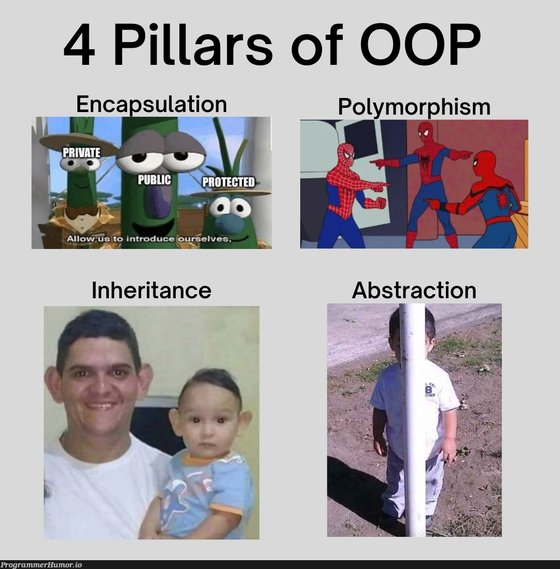

*Четыре столпа в картинках запоминаются лучше, чем по Википедии. Абстракция в исполнении ребёнка за столбом — примерно так выглядит ответ, выученный наизусть. На собеседовании картинку не покажешь: спросят «где у вас инкапсуляция?» — показывайте `TripLedger.add`, который не пустил минус пятьсот. Спросят про наследование — `InvalidExpense` от `LedgerError`.*

*Bốn trụ cột bằng hình ảnh dễ nhớ hơn đọc Wikipedia. Abstraction do đứa trẻ sau cột trình diễn — đại khái đó là hình ảnh của câu trả lời học thuộc lòng. Trong phỏng vấn không đưa hình ra được: hỏi "encapsulation của bạn ở đâu?" — hãy chỉ `TripLedger.add`, cái đã không cho âm năm trăm vào. Hỏi về inheritance — `InvalidExpense` từ `LedgerError`.*

### Вопрос 1. Что такое `self`?

**Провальный ответ:** «Ключевое слово, которое создаёт объект». Тут неверно всё: `self` не ключевое слово и ничего не создаёт.

**Хороший ответ:** «Это принятое имя первого параметра метода. Когда вызываешь метод через экземпляр, Python сам передаёт этот экземпляр первым аргументом: `expense.describe()` — то же самое, что `Expense.describe(expense)`. Назвать параметр можно как угодно, но все пишут `self`». Бонус: `expense.describe` без скобок — привязанный метод, который экземпляр уже запомнил.

### Câu hỏi 1. `self` là gì?

**Câu trả lời thất bại:** "Từ khóa tạo ra object". Ở đây sai hết: `self` không phải từ khóa và không tạo ra gì cả.

**Câu trả lời tốt:** "Đó là tên quy ước của tham số đầu tiên của method. Khi gọi method qua instance, Python tự truyền instance đó làm đối số đầu tiên: `expense.describe()` giống hệt `Expense.describe(expense)`. Đặt tên tham số thế nào cũng được, nhưng mọi người đều viết `self`". Điểm cộng: `expense.describe` không có ngoặc là bound method mà instance đã nhớ.

### Вопрос 2. Почему список в теле класса оказался общим для всех объектов?

Обычно дают код вроде нашего `Trip` с `members = []` и спрашивают, что напечатается.

**Провальный ответ:** «Python случайно переиспользует память» или «это баг Python». Нет, это не баг, это вы.

**Хороший ответ:** «Список в теле класса — атрибут класса, он один. У экземпляров своего атрибута `members` нет, поэтому `self.members` находит список класса, и `append` меняет его для всех. Исправление — создавать список в `__init__` через `self.members = []`». Бонус: упомянуть, что присваивание `obj.members = …` создало бы атрибут у экземпляра и заслонило атрибут класса, — наша банка для чаевых.

### Câu hỏi 2. Vì sao list trong thân class lại dùng chung cho mọi object?

Thường cho đoạn code như `Trip` của ta với `members = []` và hỏi sẽ in ra gì.

**Câu trả lời thất bại:** "Python tình cờ dùng lại bộ nhớ" hoặc "đây là bug của Python". Không, đây không phải bug, đây là bạn.

**Câu trả lời tốt:** "List trong thân class là class attribute, nó chỉ có một. Instance không có attribute `members` riêng, nên `self.members` tìm thấy list của class, và `append` thay đổi nó cho tất cả. Cách sửa — tạo list trong `__init__` qua `self.members = []`". Điểm cộng: nhắc rằng phép gán `obj.members = …` sẽ tạo attribute ở instance và che class attribute — chính là cái hũ tiền tip của ta.

### Вопрос 3. Наследование или композиция?

**Провальный ответ:** «Всегда наследуемся, чтобы не копировать код». Или, наоборот, заученное «композиция всегда лучше наследования» без единого «почему».

**Хороший ответ:** «Зависит от отношения. Если новый объект **является** разновидностью старого и может работать везде вместо него — наследование: `InvalidExpense` является `LedgerError`. Если объект **использует** другой — композиция: журнал хранит траты, но сам тратой или списком не является. Если унаследовать журнал от `list`, достанутся `append` и `insert` в обход проверки».

### Câu hỏi 3. Inheritance hay composition?

**Câu trả lời thất bại:** "Luôn kế thừa để khỏi copy code". Hoặc ngược lại, câu học thuộc "composition luôn tốt hơn inheritance" mà không có lấy một chữ "vì sao".

**Câu trả lời tốt:** "Tùy mối quan hệ. Nếu object mới **là** một biến thể của object cũ và có thể thay thế nó ở mọi nơi — inheritance: `InvalidExpense` là `LedgerError`. Nếu object **dùng** object khác — composition: sổ lưu các khoản chi, nhưng bản thân nó không phải khoản chi hay list. Nếu cho sổ kế thừa từ `list`, sẽ có sẵn `append` và `insert` đi vòng qua kiểm tra".

### Четыре совета, которые важнее любого ответа

**1. Разделяйте знание и предположение.** Не знаете точно — так и скажите, но не останавливайтесь на этом: «Точный порядок не помню. Ожидаю вот это, потому что… Проверил бы минимальным примером». Это ответ инженера. «Ну… наверное… да» — ответ человека, который надеется, что пронесёт.

**2. Уточняйте вопрос.** «Вы про обычное одиночное наследование или про несколько базовых классов?» Это не отмазка, если уточнение действительно меняет ответ.

**3. Показывайте, как бы вы проверили.** Пять строк кода, `type()`, `repr()`, `__mro__`, документация — это лучше, чем перечислять все термины, которые вспомнились. Вот так, например, за пять секунд проверяется то, о чём можно спорить пять минут:

### Bốn lời khuyên quan trọng hơn mọi câu trả lời

**1. Tách biệt điều bạn biết và điều bạn đoán.** Không biết chắc — cứ nói thẳng, nhưng đừng dừng ở đó: "Thứ tự chính xác tôi không nhớ. Tôi kỳ vọng là thế này, vì… Tôi sẽ kiểm tra bằng một ví dụ tối thiểu". Đó là câu trả lời của kỹ sư. "À… chắc là… vâng" — là câu trả lời của người hy vọng qua mặt được.

**2. Hỏi lại cho rõ câu hỏi.** "Anh/chị hỏi về single inheritance thông thường hay nhiều base class?" Đây không phải lấy cớ nếu câu hỏi lại thực sự làm đổi câu trả lời.

**3. Cho thấy bạn sẽ kiểm tra thế nào.** Năm dòng code, `type()`, `repr()`, `__mro__`, tài liệu — tốt hơn liệt kê mọi thuật ngữ nhớ ra được. Ví dụ, điều có thể cãi nhau năm phút thì kiểm tra trong năm giây như sau:

In [42]:
print(type(ledger).__name__, [cls.__name__ for cls in type(ledger).__mro__])
print(repr(ledger), list(vars(ledger)))

TripLedger ['TripLedger', 'object']
TripLedger('Последний шашлык', трат: 2) ['title', '_expenses']


Тип, порядок поиска, представление и что лежит внутри объекта — всё видно, гадать не нужно.

**4. Не превращайте ошибку в защиту диссертации.** Поняли, что сказали ерунду, — «Да, я перепутал атрибут класса и атрибут экземпляра. Исправляю». Спокойная поправка выглядит сильнее, чем двадцать минут уверенного продолжения в неправильную сторону. Ищут не того, кто знает всё, а того, с кем можно работать, когда что-то пошло не так.

И фраза, которую стоит запомнить:

> **Не знать — допустимо. Уверенно сочинять устройство интерпретатора — отдельная профессия, и мы сегодня не на неё собеседуемся.**

Type, thứ tự tìm kiếm, biểu diễn và cái nằm bên trong object — tất cả đều thấy rõ, không cần đoán.

**4. Đừng biến một sai sót thành buổi bảo vệ luận án.** Nhận ra mình nói bậy — "Vâng, tôi đã nhầm class attribute với instance attribute. Tôi sửa lại". Một lời sửa bình tĩnh trông mạnh hơn hai mươi phút tiếp tục tự tin đi sai hướng. Người ta tìm không phải người biết tất cả, mà là người có thể cùng làm việc khi có chuyện không ổn.

Và một câu đáng nhớ:

> **Không biết — chấp nhận được. Tự tin bịa ra cấu tạo của interpreter — là một nghề riêng, và hôm nay ta không phỏng vấn vào nghề đó.**

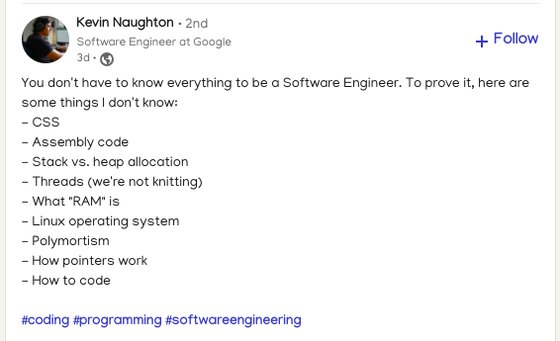

*Иллюстрация к фразе выше — сразу к обеим её частям. Начало списка честное: не знать допустимо. Но последний пункт, «как программировать», уже за границей, а «polymortism» с опечаткой — вишенка: в списке того, чего автор не знает, полиморфизм честно стоит, только написать его он тоже не смог. На собеседовании честное «не знаю, но вот как бы я проверил» лучше уверенного «полиморфизма» с ошибкой в каждом слоге.*

*Minh họa cho câu trên — cùng lúc cho cả hai nửa của nó. Phần đầu danh sách trung thực: không biết là chấp nhận được. Nhưng mục cuối, "cách lập trình", đã vượt ranh giới, còn "polymortism" viết sai chính tả là quả cherry trên bánh: trong danh sách những thứ tác giả không biết, polymorphism đứng đó đàng hoàng, chỉ là viết nó ra thì tác giả cũng không nổi. Trong phỏng vấn, "tôi không biết, nhưng tôi sẽ kiểm tra thế này" trung thực còn tốt hơn "polymorphism" tự tin với lỗi ở mỗi âm tiết.*

## ⏩ Все двенадцать вопросов: шпаргалка на дом

*⏩ На лекции не читаем — это для подготовки дома.*

Вопросы 10–12 — про то, что мы пройдём во второй половине лекции: `dataclass` и декораторы. Вернитесь к ним вечером, когда всё будет пройдено. Колонка «Что проверяет» — что на самом деле хочет услышать интервьюер.

| Вопрос | Короткий правильный ответ | Провальный ответ | Что проверяет |
|---|---|---|---|
| 1. Чем класс отличается от экземпляра? | Класс описывает тип и поведение, экземпляр — конкретный объект со своими данными. Сам класс в Python тоже объект, его тип — `type` | «Класс — это переменная с функциями» | Разделяете ли вы описание и конкретное состояние |
| 2. Что такое `self`? | Принятое имя первого параметра метода; при вызове через экземпляр туда передаётся этот экземпляр | «Ключевое слово, создающее объект» | Понимаете ли, как вызывается метод |
| 3. Что делает `__init__`? | Инициализирует уже созданный объект; создаёт его специальный метод `__new__` (его почти никогда не пишут руками). Возвращать ничего не нужно — вернёте не `None`, получите `TypeError` | «Создаёт объект и должен вернуть `self`» | Модель жизни объекта |
| 4. Почему список в теле класса оказался общим? | Это один атрибут класса; экземпляры находят его, пока у них нет своего одноимённого атрибута | «Python случайно переиспользует память» | Кто владеет изменяемым состоянием |
| 5. Чем `_x` отличается от `__x`? | `_x` — договорённость «внутреннее, не трогать»; `__x` — Python переименовывает атрибут, чтобы потомок случайно его не затёр. Приватности не даёт ни то, ни другое | «Один protected, другой настоящий private» | Не переносите ли вы модель другого языка |
| 6. Нужен ли общий предок, чтобы передавать объекты в одну функцию? | Нет: достаточно, чтобы объекты умели то, что функция с ними делает (утиная типизация) | «Без наследования полиморфизма нет» | Утиную типизацию |
| 7. Когда выбрать композицию? | Когда объект использует другой объект, а не является его разновидностью | «Всегда наследуемся, чтобы не копировать код» | Умение разложить задачу на части |
| 8. Что делает `super()`? | Даёт доступ к следующей реализации по MRO | «Всегда вызывает непосредственного родителя» | Понимание механизма, а не картинки |
| 9. Зачем нужны `__str__` и `__repr__`? | `__str__` — для человека, `__repr__` — однозначное представление для отладки; списки печатают элементы через `__repr__` | «Первый для консоли, второй для JSON» | Умеете ли вы наблюдать объекты |
| 10. `amount: int` в dataclass запрещает строку? | Нет. Аннотация — подсказка; нужна явная проверка или библиотека, которая валидирует | «Да, это строгая типизация» | Разницу между аннотацией и проверкой |
| 11. Когда выполняется декоратор? | Один раз — когда выполняется определение функции, часто при импорте модуля | «При каждом вызове функции» | Разницу между регистрацией и вызовом |
| 12. Что даёт `functools.wraps`? | Переносит имя, документацию и другие метаданные на обёртку и сохраняет ссылку на исходную функцию в `__wrapped__` | «Делает декоратор правильным и сохраняет вообще всё» | Понимаете ли вы границы инструмента |

Обратите внимание на колонку провальных ответов: почти все они звучат уверенно. Именно поэтому они провальные. На этом первый блок закончен: объекты и их состояние у нас есть. Дальше — второй навык: кто, когда и какую функцию вызывает.

## ⏩ Cả mười hai câu hỏi: bảng nhớ nhanh để về nhà

*⏩ Trên lớp không đọc — dành cho việc chuẩn bị ở nhà.*

Các câu 10–12 nói về những gì ta sẽ học ở nửa sau bài: `dataclass` và decorator. Hãy quay lại chúng vào buổi tối, khi đã học xong tất cả. Cột "Kiểm tra điều gì" — điều người phỏng vấn thực sự muốn nghe.

| Câu hỏi | Câu trả lời đúng ngắn gọn | Câu trả lời thất bại | Kiểm tra điều gì |
|---|---|---|---|
| 1. Class khác instance ở đâu? | Class mô tả kiểu và hành vi, instance là object cụ thể với dữ liệu riêng. Bản thân class trong Python cũng là object, type của nó là `type` | "Class là biến có các hàm" | Bạn có phân biệt mô tả và trạng thái cụ thể không |
| 2. `self` là gì? | Tên quy ước của tham số đầu của method; khi gọi qua instance, instance đó được truyền vào | "Từ khóa tạo ra object" | Có hiểu method được gọi thế nào không |
| 3. `__init__` làm gì? | Khởi tạo object đã được tạo; việc tạo object do method đặc biệt `__new__` (hầu như không bao giờ viết tay). Không cần trả về gì — trả về khác `None` sẽ ra `TypeError` | "Tạo object và phải trả về `self`" | Mô hình vòng đời object |
| 4. Vì sao list trong thân class lại dùng chung? | Đó là một class attribute; instance tìm thấy nó chừng nào chúng chưa có attribute cùng tên của riêng mình | "Python tình cờ dùng lại bộ nhớ" | Ai sở hữu state mutable |
| 5. `_x` khác `__x` thế nào? | `_x` — quy ước "nội bộ, đừng đụng"; `__x` — Python đổi tên attribute để lớp con không vô tình ghi đè. Cả hai đều không đem lại tính private | "Một cái protected, cái kia private thật" | Có mang mô hình của ngôn ngữ khác sang không |
| 6. Có cần tổ tiên chung để truyền object vào cùng một hàm không? | Không: chỉ cần các object biết làm điều hàm yêu cầu (duck typing) | "Không có inheritance thì không có polymorphism" | Duck typing |
| 7. Khi nào chọn composition? | Khi object dùng object khác, chứ không phải là một biến thể của nó | "Luôn kế thừa để khỏi copy code" | Khả năng chia bài toán thành các phần |
| 8. `super()` làm gì? | Cho truy cập tới implementation kế tiếp theo MRO | "Luôn gọi cha trực tiếp" | Hiểu cơ chế chứ không phải hình vẽ |
| 9. `__str__` và `__repr__` để làm gì? | `__str__` — cho con người, `__repr__` — biểu diễn rõ ràng để debug; list in các phần tử qua `__repr__` | "Cái đầu cho console, cái sau cho JSON" | Có biết quan sát object không |
| 10. `amount: int` trong dataclass có cấm string không? | Không. Annotation chỉ là gợi ý; cần kiểm tra tường minh hoặc thư viện có validate | "Có, đó là strict typing" | Khác biệt giữa annotation và kiểm tra |
| 11. Decorator chạy khi nào? | Một lần — khi định nghĩa hàm được thực thi, thường là lúc import module | "Mỗi lần gọi hàm" | Khác biệt giữa đăng ký và gọi |
| 12. `functools.wraps` cho ta cái gì? | Chuyển tên, docstring và metadata khác sang wrapper và giữ tham chiếu tới hàm gốc trong `__wrapped__` | "Làm decorator đúng và giữ lại tất cả" | Có hiểu giới hạn của công cụ không |

Hãy để ý cột câu trả lời thất bại: hầu hết đều nghe rất tự tin. Chính vì thế chúng thất bại. Đến đây khối đầu kết thúc: object và state của chúng ta đã có. Tiếp theo — kỹ năng thứ hai: ai, khi nào và gọi hàm nào.

# 7. Функция как объект

С первым навыком — кто владеет состоянием — разобрались: журнал хранит траты, трата хранит свои поля, никто не лезет в чужой холодильник. Переходим ко второму: **кто, когда и какую функцию вызывает**. Через неделю это будет главный вопрос вашей жизни. В боте функции вызываете не вы, а библиотека — когда пользователь написал `/итого`. Значит, функцию надо куда-то **отдать**, не вызывая. А для этого надо понять, что функция — такой же объект, как строка или наш журнал.

# 7. Hàm như một object

Với kỹ năng thứ nhất — ai sở hữu state — ta đã xong: sổ lưu các khoản chi, khoản chi lưu các trường của mình, không ai chui vào tủ lạnh của người khác. Chuyển sang kỹ năng thứ hai: **ai, khi nào và gọi hàm nào**. Một tuần nữa đây sẽ là câu hỏi chính của đời bạn. Trong bot, hàm không phải do bạn gọi mà do thư viện — khi người dùng viết `/итого`. Nghĩa là hàm phải được **trao** đi đâu đó mà không gọi. Và để làm vậy cần hiểu rằng hàm cũng là object như string hay cuốn sổ của ta.

## У функции два имени — как у разведчика

Объявим функцию и спросим у Python, что это такое:

## Hàm có hai tên — như điệp viên

Khai báo một hàm và hỏi Python nó là gì:

In [43]:
def shalom_world():
    print("shalom world!")


type(shalom_world)

function

`function`. Не магическое заклинание, не кусок текста — объект класса `function`, ровно как `"привет"` — объект класса `str`, а `ledger` — объект класса `TripLedger`. Раз объект — на него можно повесить второй ярлык. Помните из Л2: переменная — ярлык, а не коробка.

`function`. Không phải câu thần chú, không phải một mẩu văn bản — object của class `function`, y như `"привет"` là object của class `str`, còn `ledger` là object của class `TripLedger`. Đã là object thì có thể dán nhãn thứ hai lên nó. Nhớ từ B2: biến là nhãn, không phải cái hộp.

In [44]:
privet = shalom_world   # без скобок! Не вызываем, а вешаем второй ярлык
privet()
print(privet is shalom_world, privet.__name__)

shalom world!
True shalom_world


`privet()` напечатал `shalom world!`, `is` ответил `True` — это **одна и та же** функция под двумя именами. А `__name__` у неё по-прежнему `shalom_world`: имя в паспорте записано при рождении, в `def`, и от новых кличек не меняется. Запомните этот паспорт, через пятнадцать минут его у нас украдут.

`privet()` in ra `shalom world!`, `is` trả lời `True` — đây là **cùng một** hàm dưới hai tên. Còn `__name__` của nó vẫn là `shalom_world`: tên trong hộ chiếu được ghi lúc sinh, ở `def`, và không đổi theo các biệt danh mới. Hãy nhớ cái hộ chiếu này, mười lăm phút nữa nó sẽ bị đánh cắp.

## Передать функцию, не вызывая

Раз функция — объект, её можно передать в другую функцию аргументом. Вы это уже делали в Л3: `sorted(students, key=get_gpa)` — отдали `sorted` функцию `get_gpa`, и `sorted` сама вызывала её для каждого студента. Напишем свою такую:

## Truyền hàm đi mà không gọi

Đã là object thì hàm có thể truyền vào hàm khác làm đối số. Bạn đã làm điều này ở B3: `sorted(students, key=get_gpa)` — đưa cho `sorted` hàm `get_gpa`, và `sorted` tự gọi nó cho từng sinh viên. Viết một cái như vậy của riêng ta:

In [45]:
def run(func):
    print(f"Получил {func.__name__}, запускаю:")
    func()


run(privet)

Получил shalom_world, запускаю:
shalom world!


Скобки решают всё. `run(privet)` — отдали **функцию**, `run` вызвала её, когда захотела. А `run(privet())` — сначала вызвали `privet` сами, а в `run` отдали её **результат**. Функция, которая только печатает, возвращает `None`:

Dấu ngoặc quyết định tất cả. `run(privet)` — đưa **hàm**, `run` gọi nó khi muốn. Còn `run(privet())` — ta tự gọi `privet` trước, và đưa vào `run` **kết quả** của nó. Hàm chỉ in thì trả về `None`:

In [46]:
run(privet())   # ⚠️ упадёт специально: в run попал None, а не функция

shalom world!


AttributeError: 'NoneType' object has no attribute '__name__'

Сначала честно напечаталось `shalom world!` — это мы вызвали `privet` сами, до `run`. Потом `AttributeError: 'NoneType' object has no attribute '__name__'`: внутрь пришёл `None`, а у `None` паспорта нет. Две лишние скобки — и бот отвечает не на команду, а один раз при запуске программы.

Đầu tiên `shalom world!` được in ra đàng hoàng — đó là ta tự gọi `privet`, trước `run`. Rồi `AttributeError: 'NoneType' object has no attribute '__name__'`: vào trong là `None`, mà `None` không có hộ chiếu. Hai dấu ngoặc thừa — và bot trả lời không phải theo lệnh mà một lần duy nhất khi chương trình khởi động.

## Реестр: `handle = register(handle)`

Теперь главное. Библиотека для ботов должна где-то **запомнить** ваши функции, чтобы вызвать их потом. Сделаем игрушечную версию: список-реестр и функцию, которая кладёт в него функцию и возвращает её же, ничего не меняя.

## Registry: `handle = register(handle)`

Giờ là phần chính. Thư viện cho bot phải ở đâu đó **ghi nhớ** các hàm của bạn để gọi sau. Làm phiên bản đồ chơi: một list-registry và hàm bỏ hàm vào đó rồi trả lại chính nó, không đổi gì.

In [47]:
registry = []


def register(func):
    registry.append(func)
    return func


def handle():
    return "ответ обработчика"


handle = register(handle)
print([f.__name__ for f in registry], registry[0]())

['handle'] ответ обработчика


Функция `handle` теперь лежит в реестре, и её можно вызвать оттуда — `registry[0]()` вернул `ответ обработчика`. Строка `handle = register(handle)` значит: отдай функцию в `register`, а то, что она вернёт, повесь обратно на имя `handle`. Вернула ту же функцию — имя указывает туда же, куда и раньше.

Писать имя три раза в одной строке скучно, поэтому в Python есть сокращение — знак `@`:

Hàm `handle` giờ nằm trong registry, và có thể gọi từ đó — `registry[0]()` trả về `ответ обработчика`. Dòng `handle = register(handle)` nghĩa là: đưa hàm vào `register`, còn cái nó trả về thì treo lại lên tên `handle`. Nó trả về chính hàm đó — tên trỏ đến chỗ như trước.

Viết tên ba lần trong một dòng thì chán, nên Python có cách viết tắt — dấu `@`:

In [48]:
@register
def ping():
    return "понг"


print([f.__name__ for f in registry])

['handle', 'ping']


Это **декоратор**. Никакого волшебства: `@register` над `def ping` — ровно то же самое, что `ping = register(ping)` сразу после `def`. Декоратор — любая функция, которая принимает функцию и что-то возвращает; что вернула — то и будет висеть на имени.

Đây là **decorator**. Không có phép màu nào: `@register` đặt trên `def ping` — chính xác là `ping = register(ping)` ngay sau `def`. Decorator là hàm bất kỳ nhận hàm và trả về thứ gì đó; cái nó trả về sẽ được treo lên tên.

## 🎤 Угадай вывод: когда работает декоратор

*🎤 Контрольный вопрос №2 — второй контроль темпа. Если зал уверенно отвечает — ⏩-подразделы раздела 11 пропускаем.*

```python
def mark(func):
    print("реестр")
    return func

@mark
def alarm():
    print("паника")

print("готово")
alarm()
```

Что и в каком порядке напечатается? Проверяем:

## 🎤 Đoán output: decorator chạy khi nào

*🎤 Câu hỏi kiểm tra số 2 — lần kiểm tra tốc độ thứ hai. Nếu cả lớp trả lời chắc chắn — các mục con ⏩ của mục 11 ta bỏ qua.*

```python
def mark(func):
    print("реестр")
    return func

@mark
def alarm():
    print("паника")

print("готово")
alarm()
```

Sẽ in ra gì và theo thứ tự nào? Kiểm tra:

In [49]:
def mark(func):
    print("реестр")
    return func


@mark
def alarm():
    print("паника")


print("готово")
alarm()

реестр
готово
паника


`реестр`, `готово`, `паника`. Декоратор выполняется **один раз, в момент определения функции** — когда Python дочитал `def`, функцию ещё никто не вызывал. Тело `alarm` выполняется потом, при каждом вызове. Именно поэтому бот «знает» ваши команды сразу после запуска программы: декораторы сработали, пока Python читал файл сверху вниз.

`реестр`, `готово`, `паника`. Decorator chạy **một lần, tại thời điểm định nghĩa hàm** — khi Python đọc xong `def`, hàm chưa ai gọi. Thân `alarm` chạy sau đó, mỗi lần gọi. Chính vì vậy bot "biết" các lệnh của bạn ngay sau khi chương trình khởi động: decorator đã chạy trong lúc Python đọc file từ trên xuống.

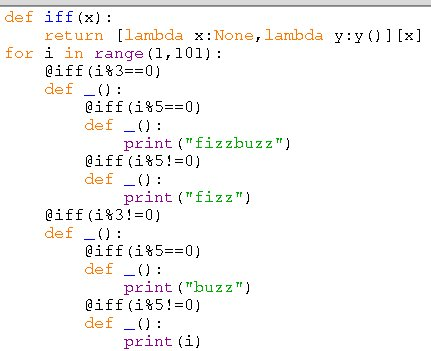

*FizzBuzz без единого `if` — на декораторах. Работает ровно потому, что вы только что увидели: декоратор выполняется в момент определения функции. `iff(True)` возвращает `lambda y: y()` — она сразу вызывает `_`, а `iff(False)` возвращает функцию, которая молча её выбрасывает. Объясните соседу, почему `_` печатает, хотя её никто не вызывал, — и вы поняли декораторы. Только не пишите так на работе: это работает, и это худшее, что о нём можно сказать.*

*FizzBuzz không một `if` nào — bằng decorator. Chạy được đúng vì điều bạn vừa thấy: decorator chạy ngay lúc định nghĩa hàm. `iff(True)` trả về `lambda y: y()` — nó gọi `_` ngay lập tức, còn `iff(False)` trả về hàm lặng lẽ vứt `_` đi. Hãy giải thích cho bạn bên cạnh vì sao `_` in ra dù không ai gọi nó — và bạn đã hiểu decorator. Chỉ đừng viết thế ở chỗ làm: nó chạy được, và đó là điều tệ nhất có thể nói về nó.*

## Уточнение к обещанию Л3

В Л3, в 📚 про замыкания, я написал: «на замыканиях построены декораторы». Пора уточнить, пока это не вытатуировали. `register` — полноценный декоратор, а замыкания в нём нет: ни вложенной функции, ни запомненных переменных. Взял функцию, записал в реестр, вернул как есть. Правильно так: **замыкания часто нужны декораторам** — когда декоратор меняет поведение функции. Именно такой мы сейчас и напишем.

## Đính chính lời hứa ở B3

Ở B3, trong phần 📚 về closure, tôi viết: "decorator được xây trên closure". Đã đến lúc đính chính trước khi ai đó xăm nó lên người. `register` là decorator hoàn chỉnh, mà trong nó không có closure: không có hàm lồng, không có biến được nhớ. Nhận hàm, ghi vào registry, trả về nguyên xi. Đúng thế này: **decorator thường cần closure** — khi decorator thay đổi hành vi của hàm. Đúng loại như vậy ta sẽ viết ngay bây giờ.

# 8. Обёртка: декоратор, который подменяет

Задача: хотим знать, сколько времени работает функция. Лезть в её код не хотим — функций двадцать, и в каждую вставлять замер времени скучно и опасно. Нужно, чтобы снаружи накрутили что-то, что засечёт время, вызовет оригинал и вернёт его ответ. Это называется **обёртка**.

# 8. Wrapper: decorator thay thế hàm

Bài toán: muốn biết hàm chạy mất bao lâu. Không muốn chui vào code của nó — có hai chục hàm, chèn đo thời gian vào từng hàm vừa chán vừa nguy hiểm. Cần từ bên ngoài bọc vào thứ gì đó bấm giờ, gọi bản gốc và trả về câu trả lời của nó. Cái đó gọi là **wrapper**.

## Замыкание: функция с памятью

Сначала инструмент. `make_counter` был в 📚 Л3 — кто дома дочитал, узнает, кто нет, вот он ещё раз:

## Closure: hàm có trí nhớ

Trước hết là công cụ. `make_counter` đã có ở phần 📚 B3 — ai đọc ở nhà thì nhận ra, ai chưa thì đây lại là nó:

In [50]:
def make_counter():
    count = 0

    def increment():
        nonlocal count   # count — из make_counter, а не новая локальная
        count += 1
        return count

    return increment     # саму функцию, без скобок


counter = make_counter()
print(counter(), counter(), counter())

1 2 3


`1 2 3`. `make_counter` давно закончила работу, её локальные переменные должны были умереть по правилу Лас-Вегаса. Но `increment` унесла `count` с собой и помнит его между вызовами. Функция, которая помнит переменные места, где её создали, — **замыкание**. Обёртке нужна ровно такая память: только помнить она будет не счётчик, а **исходную функцию**.

`1 2 3`. `make_counter` đã chạy xong từ lâu, các biến local của nó lẽ ra phải chết theo luật Las Vegas. Nhưng `increment` đã mang `count` theo và nhớ nó giữa các lần gọi. Hàm nhớ các biến của nơi nó được tạo ra — là **closure**. Wrapper cần chính loại trí nhớ đó: chỉ khác là nó nhớ không phải bộ đếm mà là **hàm gốc**.

## Первая обёртка

Снаружи новая матрёшка, внутри — старая функция. Декоратор принимает функцию, внутри себя создаёт новую, `wrapper`, и возвращает **её**:

## Wrapper đầu tiên

Bên ngoài là búp bê matryoshka mới, bên trong — hàm cũ. Decorator nhận hàm, bên trong tạo hàm mới `wrapper` và trả về **nó**:

In [51]:
def loud(func):
    def wrapper():
        print(f"→ звоним {func.__name__}")
        result = func()
        print(f"← {func.__name__} ответила")
        return result
    return wrapper


@loud
def ping():
    return "понг"


print(ping())

→ звоним ping
← ping ответила
понг


Теперь на имени `ping` висит не исходная функция, а `wrapper`. Вызываем `ping()` — на самом деле работает `wrapper`: печатает «звоним», вызывает оригинал (он у неё в замыкании под именем `func`), печатает «ответила» и возвращает `понг`. Исходный код `ping` мы не тронули ни на букву.

Обратите внимание на **два `return`**. Внутренний, `return result`, — `wrapper` отдаёт наружу ответ оригинала. Внешний, `return wrapper`, — декоратор отдаёт обёртку, чтобы её повесили на имя. Забудете любой — получите баг.

Giờ trên tên `ping` treo không phải hàm gốc mà là `wrapper`. Gọi `ping()` — thực ra chạy `wrapper`: in "звоним" ("đang gọi"), gọi bản gốc (nó có trong closure dưới tên `func`), in "ответила" ("đã trả lời") và trả về `понг`. Code gốc của `ping` ta không đụng một chữ.

Hãy chú ý **hai `return`**. Trong, `return result`, — `wrapper` trả ra ngoài kết quả của bản gốc. Ngoài, `return wrapper`, — decorator trả wrapper để treo lên tên. Quên cái nào cũng có bug.

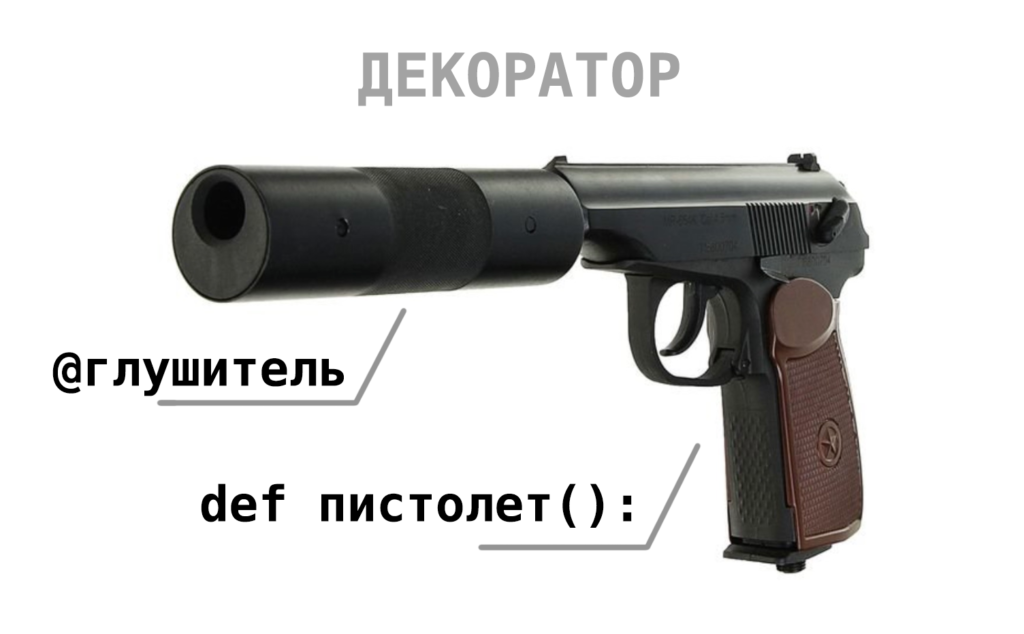

*Классика жанра. Глушитель не переделывает пистолет — его накручивают снаружи, и стреляет всё тот же пистолет, просто по-другому. Как и с `@loud`: функция прежняя, поведение вокруг неё — новое.*

*Kinh điển của thể loại. Ống giảm thanh không làm lại khẩu súng — nó được vặn từ bên ngoài, và vẫn là khẩu súng đó bắn, chỉ là theo cách khác. Cũng như với `@loud`: hàm vẫn như cũ, hành vi xung quanh nó — mới.*

## Две забытые строчки

Забыли внешний `return wrapper`:

## Hai dòng bị quên

Quên `return wrapper` bên ngoài:

In [52]:
def broken(func):
    def wrapper():
        return func()


@broken
def ping():
    return "понг"


ping()   # ⚠️ упадёт специально

TypeError: 'NoneType' object is not callable

`TypeError: 'NoneType' object is not callable`. Функция без `return` возвращает `None` — и `@broken` честно повесил `None` на имя `ping`. Функции больше нет, есть `None` с чужим именем.

Забыли внутренний `return`:

`TypeError: 'NoneType' object is not callable`. Hàm không có `return` trả về `None` — và `@broken` đàng hoàng treo `None` lên tên `ping`. Hàm không còn, chỉ còn `None` mang tên người khác.

Quên `return` bên trong:

In [53]:
def broken(func):
    def wrapper():
        func()   # вызвали — а ответ выбросили
    return wrapper


@broken
def answer():
    return 42


print(answer())

None


`None`. Исходная функция ответила `42`, обёртка этот ответ выкинула. Без ошибок, без предупреждений — самый подлый вариант.

> 🤖 **Где ошибается ваш ИИ.** Попросите «декоратор, который логирует вызов», и вполне можете получить обёртку, где `print(...)` есть, `func(*args, **kwargs)` есть, а `return` перед вызовом — нет. Лог красивый, всё «работает», а декорированная функция теперь возвращает `None`. Проверка за пять секунд: `print(f(...))` до декорирования и после — результат обязан совпасть.

`None`. Hàm gốc đã trả lời `42`, wrapper vứt câu trả lời đó đi. Không lỗi, không cảnh báo — kiểu thâm hiểm nhất.

> 🤖 **AI của bạn sai ở đâu.** Hãy nhờ "decorator ghi log lời gọi", và rất có thể bạn nhận được wrapper có `print(...)`, có `func(*args, **kwargs)`, nhưng không có `return` trước lời gọi. Log đẹp, mọi thứ "chạy", còn hàm được decorate giờ trả về `None`. Kiểm tra trong năm giây: `print(f(...))` trước và sau khi decorate — kết quả phải trùng.

## `*args, **kwargs`: обёртка для любой функции

Наш `wrapper()` не принимает аргументов. Повесим `@loud` на функцию с параметром:

## `*args, **kwargs`: wrapper cho mọi hàm

`wrapper()` của ta không nhận đối số. Treo `@loud` lên hàm có tham số:

In [54]:
@loud
def greet(name):
    return f"Привет, {name}"


greet("Бобр Иваныч")   # ⚠️ упадёт специально

TypeError: loud.<locals>.wrapper() takes 0 positional arguments but 1 was given

`TypeError: loud.<locals>.wrapper() takes 0 positional arguments but 1 was given`. Снаружи вызывают **обёртку**, и это её параметры решают, что можно передать. Чтобы она подходила к любой функции, принимаем всё подряд и всё передаём дальше — `*args` и `**kwargs` из Л3: звёздочки в `def` собирают аргументы в кортеж и словарь, а при вызове `*` раскладывает их обратно, как `flexible_sum(*prices)` в Л3; `**` для словаря работает так же.

`TypeError: loud.<locals>.wrapper() takes 0 positional arguments but 1 was given`. Bên ngoài gọi **wrapper**, và chính tham số của nó quyết định cái gì được truyền. Để nó hợp với mọi hàm, ta nhận tất cả và truyền tiếp tất cả — `*args` và `**kwargs` từ B3: dấu sao trong `def` gom đối số thành tuple và dictionary, còn khi gọi `*` rải chúng ra lại, như `flexible_sum(*prices)` ở B3; `**` với dictionary cũng vậy.

## `@timer`: замер времени с `try/finally`

Теперь честный таймер. Время меряем `time.perf_counter()` — это часы для замеров: монотонные, высокой точности. `time.time()` — настенные: их может перевести синхронизация, и замер может получиться даже отрицательным. Печать времени кладём в `finally`. Напомню: в Л3, в разделе про `with`, мы видели, что `with` — это сокращение для `try/finally`. Код в `finally` выполняется **в любом случае**: и когда `try` закончился нормально или через `return`, и когда в нём вылетела ошибка. «Выключить свет, даже уходя через окно» (подробно — в ⏩-блоке Л3, кто дочитал дома).

## `@timer`: đo thời gian với `try/finally`

Giờ là timer đàng hoàng. Đo thời gian bằng `time.perf_counter()` — đây là đồng hồ để đo: đơn điệu, độ chính xác cao. `time.time()` là đồng hồ treo tường: nó có thể bị đồng bộ hóa chỉnh, và kết quả đo có thể thậm chí âm. In thời gian đặt trong `finally`. Nhắc lại: ở B3, trong phần về `with`, ta đã thấy `with` là cách viết tắt của `try/finally`. Code trong `finally` chạy **trong mọi trường hợp**: cả khi `try` kết thúc bình thường hay qua `return`, và khi trong đó bắn ra lỗi. "Tắt đèn, kể cả khi đi ra bằng cửa sổ" (chi tiết — ở khối ⏩ của B3, ai đọc ở nhà).

In [55]:
import time


def timer(func):
    def wrapper(*args, **kwargs):
        started = time.perf_counter()
        try:
            return func(*args, **kwargs)
        finally:
            print(f"{func.__name__}: {time.perf_counter() - started:.6f} с")
    return wrapper


@timer
def slow_sum(n):
    """Складывает числа от 0 до n-1 — медленно и честно."""
    total = 0
    for i in range(n):
        total += i
    return total


print(slow_sum(1_000_000))

slow_sum: 0.016682 с
499999500000


Сначала строка таймера, потом сумма: `finally` срабатывает **перед** выходом из `wrapper`, а `print` снаружи получает результат только после выхода. Ваше число секунд будет другим — и при следующем запуске тоже. `return` стоит прямо внутри `try`, поэтому результат не теряется.

А если функция упадёт?

Đầu tiên là dòng của timer, rồi mới là tổng: `finally` chạy **trước** khi thoát khỏi `wrapper`, còn `print` bên ngoài chỉ nhận kết quả sau khi thoát. Số giây của bạn sẽ khác — và lần chạy sau cũng khác. `return` nằm ngay trong `try`, nên kết quả không bị mất.

Còn nếu hàm bị lỗi thì sao?

In [56]:
slow_sum("много")   # ⚠️ упадёт специально: range от строки не бывает

slow_sum: 0.000002 с


TypeError: 'str' object cannot be interpreted as an integer

Над трейсбеком — строка таймера: `finally` отработал, хотя функция вылетела в окно с `TypeError`. Ошибку таймер не проглотил, она полетела дальше — так и надо.

Кстати, `@timer` над `def slow_sum` — это ровно `slow_sum = timer(slow_sum)`: старый ярлык сняли с оригинала и повесили на обёртку.

Phía trên traceback là dòng của timer: `finally` đã chạy, dù hàm đã "bay ra cửa sổ" với `TypeError`. Timer không nuốt lỗi, nó bay đi tiếp — đúng như nên làm.

Nhân tiện, `@timer` đặt trên `def slow_sum` chính là `slow_sum = timer(slow_sum)`: nhãn cũ được gỡ khỏi bản gốc và treo lên wrapper.

## Украденный паспорт: `functools.wraps`

Обещал, что паспорт украдут. Спросим у `slow_sum`, кто она:

## Hộ chiếu bị đánh cắp: `functools.wraps`

Tôi đã hứa là hộ chiếu sẽ bị đánh cắp. Hỏi `slow_sum` xem nó là ai:

In [57]:
print(slow_sum.__name__, slow_sum.__doc__)

wrapper None


`wrapper None`. Имя и описание — от обёртки: на имени `slow_sum` висит `wrapper`. В трейсбеках, логах и `help()` все ваши функции теперь называются `wrapper`, и найти виноватого — удачи. Лечится одной строкой — декоратором `wraps` из модуля `functools`, который копирует обёртке паспорт оригинала. Да, декоратор внутри декоратора:

`wrapper None`. Tên và mô tả là của wrapper: trên tên `slow_sum` treo `wrapper`. Trong traceback, log và `help()` mọi hàm của bạn giờ đều tên `wrapper`, và tìm thủ phạm — chúc may mắn. Chữa bằng một dòng — decorator `wraps` từ module `functools`, sao chép hộ chiếu của bản gốc sang wrapper. Đúng, decorator bên trong decorator:

In [58]:
from functools import wraps


def timer(func):
    @wraps(func)   # переносим на wrapper имя, описание и прочий паспорт func
    def wrapper(*args, **kwargs):
        started = time.perf_counter()
        try:
            return func(*args, **kwargs)
        finally:
            print(f"{func.__name__}: {time.perf_counter() - started:.6f} с")
    return wrapper


@timer
def slow_sum(n):
    """Складывает числа от 0 до n-1 — медленно и честно."""
    total = 0
    for i in range(n):
        total += i
    return total


print(slow_sum.__name__, "—", slow_sum.__doc__)

slow_sum — Складывает числа от 0 до n-1 — медленно и честно.


Паспорт на месте. Это финальная версия `timer`, она нам ещё пригодится. Правило простое: пишете обёртку — пишете `@wraps(func)`. Только `wraps` чинит паспорт, а не логику: потерянный `return` он не вернёт.

Hộ chiếu đã về chỗ. Đây là phiên bản cuối của `timer`, nó còn dùng tiếp. Quy tắc đơn giản: viết wrapper — thì viết `@wraps(func)`. Chỉ có điều `wraps` sửa hộ chiếu chứ không sửa logic: `return` bị mất thì nó không trả lại.

## «Раздекорировать нельзя»? Можно

В старых конспектах — и в прошлогодней версии этой лекции — написано: «функцию нельзя раздекорировать». Неправда. `wraps` заодно кладёт в обёртку ссылку на оригинал — атрибут `__wrapped__`:

## "Không thể gỡ decorator"? Có thể

Trong ghi chép cũ — và trong phiên bản năm ngoái của bài này — viết: "không thể gỡ decorator khỏi hàm". Không đúng. `wraps` tiện thể đặt vào wrapper tham chiếu tới bản gốc — attribute `__wrapped__`:

In [59]:
print(slow_sum.__wrapped__(1_000_000))   # оригинал напрямую — таймер молчит

499999500000


Сумма есть, строки таймера нет — вызвали исходную функцию мимо обёртки. Имя `slow_sum` по-прежнему висит на обёртке, но до оригинала можно дотянуться. Это работает, только если декоратор написан с `@wraps`; цепочку из нескольких обёрток разматывает `inspect.unwrap`. А честное «но» из старой версии остаётся в силе: каждая обёртка — лишний вызов, и отлаживать матрёшку сложнее, чем голую функцию.

> 🤖 **Где ошибается ваш ИИ.** Частый подарок — универсальный `@retry`: ловит любой `Exception` и повторяет вызов три раза. Для «прочитать курс валют» терпимо. Для «отправить сообщение» или «списать деньги» — катастрофа: первая попытка могла пройти, а упасть уже ответ, и пользователь получит три сообщения, а карта — три списания. Прежде чем принимать такой код, ответьте: какие ошибки временные, сколько попыток, с какой паузой — и безопасно ли повторять **эту** операцию.

Có tổng, không có dòng timer — ta đã gọi hàm gốc đi vòng qua wrapper. Tên `slow_sum` vẫn treo trên wrapper, nhưng có thể với tới bản gốc. Cái này chỉ hoạt động nếu decorator được viết với `@wraps`; chuỗi nhiều wrapper được gỡ bằng `inspect.unwrap`. Còn cái "nhưng" trung thực từ phiên bản cũ vẫn còn hiệu lực: mỗi wrapper là một lời gọi thừa, và debug búp bê matryoshka khó hơn hàm trần.

> 🤖 **AI của bạn sai ở đâu.** Món quà thường gặp — `@retry` vạn năng: bắt mọi `Exception` và lặp lại lời gọi ba lần. Với "đọc tỷ giá" thì chịu được. Với "gửi tin nhắn" hoặc "trừ tiền" — là thảm họa: lần thử đầu có thể đã thành công, còn lỗi chỉ ở khâu phản hồi, và người dùng nhận ba tin nhắn, còn thẻ bị trừ ba lần. Trước khi chấp nhận code như vậy, hãy trả lời: lỗi nào là tạm thời, thử mấy lần, nghỉ bao lâu — và có an toàn khi lặp lại **thao tác này** không.

# 9. Регистрация, фабрика и порядок

Собираем всё вместе. У нас есть журнал «Последний шашлык», таймер и идея реестра. Хотим, как в настоящем боте: команда `/итого` → функция-обработчик → ответ. Реестр-список из раздела 7 не годится: бот получает **текст команды**, и по нему надо найти функцию. Значит, нужен словарь «команда → функция».

# 9. Đăng ký, factory và thứ tự

Gộp tất cả lại. Ta có sổ «Последний шашлык», timer và ý tưởng về registry. Muốn giống bot thật: lệnh `/итого` → hàm handler → câu trả lời. Registry dạng list ở mục 7 không hợp: bot nhận **văn bản của lệnh**, và theo đó phải tìm hàm. Nghĩa là cần dictionary "lệnh → hàm".

## Фабрика декораторов: `@command("/итого")`

Проблема: `register` получает только функцию. Откуда ей узнать, что это обработчик именно `/итого`? Имя команды надо передать **отдельно**. Поэтому делаем функцию, которая принимает имя команды и **возвращает декоратор** — фабрику декораторов:

## Decorator factory: `@command("/итого")`

Vấn đề: `register` chỉ nhận hàm. Làm sao nó biết đây là handler của đúng `/итого`? Tên lệnh phải được truyền **riêng**. Vì thế ta làm hàm nhận tên lệnh và **trả về decorator** — decorator factory:

In [60]:
handlers = {}


def command(name):
    def register(func):
        handlers[name] = func   # name помнится из command — замыкание
        return func             # функцию возвращаем как есть, без обёртки
    return register


decorator = command("/итого")
print(decorator.__name__, handlers)

register {}


`command("/итого")` вернула функцию `register` — это и есть декоратор. А реестр пока пуст: регистрирует не `command`, а `register`, когда получит функцию. Читаем `@command("/итого")` в два шага. Сначала Python **вызывает** `command("/итого")` — это обычный вызов со скобками, он возвращает `register`, которая помнит `name`. Потом этот `register` работает как обычный декоратор над функцией. Длинная запись — `total_handler = command("/итого")(total_handler)`: две пары скобок, два вызова подряд.

Отсюда классическая грабля: забыть скобки у фабрики. Написали `@command` вместо `@command("/старт")`:

`command("/итого")` trả về hàm `register` — đó chính là decorator. Còn registry thì tạm trống: người đăng ký không phải `command` mà là `register`, khi nó nhận được hàm. Đọc `@command("/итого")` theo hai bước. Trước tiên Python **gọi** `command("/итого")` — đó là lời gọi thông thường có ngoặc, trả về `register` vốn nhớ `name`. Sau đó `register` này hoạt động như decorator thông thường trên hàm. Cách viết dài — `total_handler = command("/итого")(total_handler)`: hai cặp ngoặc, hai lời gọi liên tiếp.

Từ đây có cái bẫy kinh điển: quên ngoặc ở factory. Viết `@command` thay vì `@command("/старт")`:

In [61]:
@command   # забыли ("/старт")
def start_handler():
    return "Привет! Я считаю ваши траты."


print(start_handler.__name__, list(handlers))

register []


Ни ошибки, ни предупреждения. Только функции `start_handler` больше нет. Python вызвал `command(start_handler)` — фабрика послушно приняла функцию за имя команды и вернула `register`. Теперь на имени `start_handler` висит `register`, а в реестре по-прежнему пусто. Бот на `/старт` молчит, вы час ищете ошибку в Telegram. Декораторы библиотек в Л5 тоже пишутся со скобками; потеряете их — получите похожую поломку. Так что запомните это лицо.

Видите, замыкание вернулось — но обёртки по-прежнему нет. Разделим роли: **`command()` возвращает декоратор, `register()` регистрирует, а обёртку делает только `timer`**. Повесим оба на обработчик итога:

Không lỗi, không cảnh báo. Chỉ là hàm `start_handler` không còn nữa. Python đã gọi `command(start_handler)` — factory ngoan ngoãn coi hàm là tên lệnh và trả về `register`. Giờ trên tên `start_handler` treo `register`, còn registry vẫn trống. Bot im lặng với `/старт`, còn bạn mất một giờ đi tìm lỗi trong Telegram. Decorator của thư viện ở B5 cũng viết có ngoặc; làm mất chúng — sẽ hỏng tương tự. Hãy nhớ cái "mặt" này.

Thấy chưa, closure đã quay lại — nhưng wrapper thì vẫn chưa có. Ta tách vai trò: **`command()` trả về decorator, `register()` đăng ký, còn wrapper chỉ do `timer` làm**. Treo cả hai lên handler của phần tổng:

In [62]:
@command("/итого")
@timer
def total_handler(ledger: TripLedger) -> str:
    return f"{ledger.title}: {ledger.total()} ₽"


print(list(handlers))

['/итого']


В реестре одна команда — `/итого`. А теперь сыграем Telegram: пришла команда, ищем обработчик в словаре и вызываем его с журналом. Без всякого бота:

Trong registry có một lệnh — `/итого`. Giờ đóng vai Telegram: lệnh tới, tìm handler trong dictionary và gọi nó với cuốn sổ. Không cần bot nào cả:

In [63]:
print(handlers["/итого"](ledger))

total_handler: 0.000002 с
Последний шашлык: 1500 ₽


Строка таймера `total_handler: … с`, затем `Последний шашлык: 1500 ₽` — уголь за 1200 и вода за 300. Таймер сработал, значит, в реестре лежит **обёртка**, а не голая функция. Почему так, а не наоборот? Чтобы ответить, надо понять, в каком порядке применяются декораторы.

Dòng của timer `total_handler: … с`, rồi `Последний шашлык: 1500 ₽` — than 1200 và nước 300. Timer đã chạy, nghĩa là trong registry nằm **wrapper**, chứ không phải hàm trần. Vì sao như vậy mà không phải ngược lại? Để trả lời, cần hiểu decorator được áp dụng theo thứ tự nào.

## Сэндвич: порядок декораторов

Классика — бутерброд. Два декоратора: хлеб и начинка. Каждый печатает своё до и после вызова. Обёртки тут нарочно урезаны, чтобы влезли на экран: без `*args, **kwargs`, без `return` и без `@wraps`. Для порядка слоёв это неважно, а боевые обёртки пишем как `timer`:

## Sandwich: thứ tự decorator

Kinh điển — cái bánh mì kẹp. Hai decorator: vỏ bánh và nhân. Mỗi cái in phần của mình trước và sau lời gọi. Các wrapper ở đây cố ý được lược bớt để vừa màn hình: không có `*args, **kwargs`, không có `return` và không có `@wraps`. Với thứ tự các lớp thì điều đó không quan trọng, còn wrapper thực chiến ta viết như `timer`:

In [64]:
def bread(func):
    def wrapper():
        print("<‾‾‾‾‾хлеб‾‾‾‾‾>")
        func()
        print("<_____хлеб_____>")
    return wrapper


def ingredients(func):
    def wrapper():
        print("  #помидоры#")
        func()
        print("  ~салат~")
    return wrapper


def sandwich(food="--ветчина--"):
    print("  " + food)


sandwich()

  --ветчина--


Голая ветчина. Грустно, как бутерброд в общаге в четверг. Обернём руками — сначала начинкой, потом хлебом:

Chỉ có giăm bông trần. Buồn như cái bánh mì kẹp trong ký túc xá vào thứ Năm. Bọc bằng tay — trước hết là nhân, rồi mới đến vỏ bánh:

In [65]:
sandwich = bread(ingredients(sandwich))
sandwich()

<‾‾‾‾‾хлеб‾‾‾‾‾>
  #помидоры#
  --ветчина--
  ~салат~
<_____хлеб_____>


Хлеб снаружи, помидоры и салат внутри, ветчина в середине. Через `@` это пишется так — нижний декоратор ближе к `def`, он и оборачивает первым:

```python
@bread
@ingredients
def sandwich(food="--ветчина--"):
    print("  " + food)
```

Vỏ bánh ở ngoài, cà chua và rau xà lách bên trong, giăm bông ở giữa. Qua `@` thì viết như sau — decorator dưới gần `def` hơn, nó bọc đầu tiên:

```python
@bread
@ingredients
def sandwich(food="--ветчина--"):
    print("  " + food)
```

## 🎤 Угадай вывод: сэндвич наоборот

*🎤 Спросите зал до запуска.*

Поменяем декораторы местами. Что напечатает этот код?

```python
@ingredients
@bread
def sandwich(food="--ветчина--"):
    print("  " + food)

sandwich()
```

## 🎤 Đoán output: sandwich ngược

*🎤 Hỏi cả lớp trước khi chạy.*

Đổi chỗ các decorator. Đoạn code này sẽ in gì?

```python
@ingredients
@bread
def sandwich(food="--ветчина--"):
    print("  " + food)

sandwich()
```

In [66]:
@ingredients
@bread
def sandwich(food="--ветчина--"):
    print("  " + food)


sandwich()

  #помидоры#
<‾‾‾‾‾хлеб‾‾‾‾‾>
  --ветчина--
<_____хлеб_____>
  ~салат~


Помидоры **снаружи** хлеба. Это `ingredients(bread(sandwich))`: сначала хлебом обернул нижний декоратор, потом всё это начинкой — верхний. Правило: **оборачивают снизу вверх, при вызове выполняются сверху вниз** — первым начинает работать самый внешний слой. Есть такой бутерброд можно, но руки потом мыть долго. Если путаетесь — расставьте скобки, как мы делали руками: `ingredients(bread(sandwich))` читается однозначно, и никакой мистики в порядке нет.

Cà chua **ở ngoài** vỏ bánh. Đây là `ingredients(bread(sandwich))`: trước hết decorator dưới bọc bằng vỏ bánh, rồi toàn bộ cái đó được bọc bằng nhân — decorator trên. Quy tắc: **bọc từ dưới lên, khi gọi thì thực thi từ trên xuống** — lớp ngoài cùng bắt đầu làm việc trước. Ăn cái bánh mì kẹp như vậy thì được, nhưng sau đó rửa tay rất lâu. Nếu bạn rối — hãy đặt ngoặc như ta làm bằng tay: `ingredients(bread(sandwich))` đọc không nhập nhằng, và trong thứ tự không có chút thần bí nào.

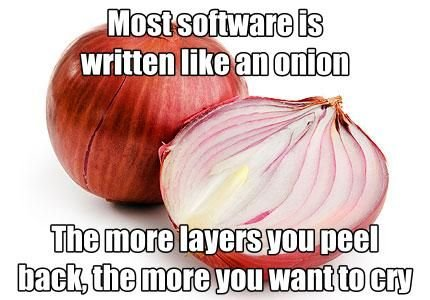

*Говорят, большую часть софта пишут как луковицу: чем больше слоёв снимаешь, тем сильнее хочется плакать. Два-три декоратора над функцией — нормально. Когда их пять, расставляйте скобки, как выше, и готовьте платок. Снимать слои по одному поможет `__wrapped__` из раздела про `wraps`, но легче от этого не станет.*

*Người ta nói phần lớn phần mềm được viết như củ hành: bóc càng nhiều lớp, càng muốn khóc. Hai-ba decorator trên một hàm — bình thường. Khi có năm, hãy đặt ngoặc như trên và chuẩn bị khăn tay. Bóc từng lớp sẽ có `__wrapped__` từ phần về `wraps` giúp, nhưng cũng chẳng dễ chịu hơn.*

## Порядок `@command` и `@timer`

Теперь понятно, что было с `total_handler`. Сначала `@timer` обернул функцию, потом `@command` положил в реестр **результат** — обёртку с таймером. Поменяем местами на учебной команде `/сколько`:

## Thứ tự `@command` và `@timer`

Giờ đã hiểu chuyện gì xảy ra với `total_handler`. Trước hết `@timer` bọc hàm, rồi `@command` đặt vào registry **kết quả** — wrapper có timer. Đổi chỗ trên lệnh học tập `/сколько`:

In [67]:
@timer
@command("/сколько")
def count_handler(ledger):
    return f"{ledger.title}: трат {len(ledger)}"


print(handlers["/сколько"](ledger))   # из реестра
print(count_handler(ledger))          # по имени

Последний шашлык: трат 2
count_handler: 0.000002 с
Последний шашлык: трат 2


Из реестра — ответ без строки таймера: `@command` сработал первым и сохранил **голую** функцию. По имени — с таймером: обёртку `@timer` повесили уже только на имя `count_handler`. А бот вызывает через реестр, так что таймера в боте не было бы вовсе. Отсюда правило: **регистратор — верхним**, чтобы в реестр попало то, что вы собрали ниже.

Từ registry — câu trả lời không có dòng timer: `@command` chạy trước và lưu hàm **trần**. Theo tên — có timer: wrapper `@timer` chỉ được treo lên tên `count_handler`. Mà bot gọi qua registry, nên trong bot sẽ không hề có timer. Từ đây có quy tắc: **bộ đăng ký — đặt trên cùng**, để vào registry là thứ bạn đã lắp ráp ở dưới.

## 🎤 Угадай вывод: подмена

*🎤 Главный вопрос раздела. Кто объяснит его без слова «магия», тот готов к ботам.*

Обычная ситуация в Jupyter: зарегистрировали обработчик, потом «починили» функцию в соседней ячейке — а декоратор написать забыли.

```python
@command("/пинг")
def ping():
    return "пинг"

def ping():
    return "подмена"

print(ping(), handlers["/пинг"]())
```

## 🎤 Đoán output: sự thay thế

*🎤 Câu hỏi chính của mục này. Ai giải thích được mà không dùng chữ "ma thuật" thì sẵn sàng cho bot.*

Tình huống quen thuộc trong Jupyter: đã đăng ký handler, sau đó "sửa" hàm ở ô bên cạnh — mà quên viết decorator.

```python
@command("/пинг")
def ping():
    return "пинг"

def ping():
    return "подмена"

print(ping(), handlers["/пинг"]())
```

In [68]:
@command("/пинг")
def ping():
    return "пинг"


def ping():
    return "подмена"


print(ping(), handlers["/пинг"]())

подмена пинг


`подмена пинг`. Второй `def` повесил ярлык `ping` на новую функцию. Но реестр хранит не **имя** `ping`, а ссылку на **старый объект**, полученную в момент регистрации. Ярлык перевесили — объект в словаре остался прежним. В Л5 это выглядит так: бот отвечает по-старому, хотя код вы «исправили». Лечится перерегистрацией — `@command("/пинг")` над новой версией.

Реестр — обычный словарь. Учебные команды из него уберём, оставим только `/итого`:

`подмена пинг`. `def` thứ hai treo nhãn `ping` lên hàm mới. Nhưng registry lưu không phải **tên** `ping`, mà là tham chiếu tới **object cũ** nhận được lúc đăng ký. Nhãn được treo lại — còn object trong dictionary vẫn như cũ. Ở B5 nó trông thế này: bot trả lời theo kiểu cũ, dù bạn đã "sửa" code. Chữa bằng cách đăng ký lại — `@command("/пинг")` trên phiên bản mới.

Registry là dictionary thường. Bỏ các lệnh học tập ra khỏi đó, chỉ giữ `/итого`:

In [69]:
del handlers["/сколько"], handlers["/пинг"]
print(list(handlers))

['/итого']


В Л5 вы увидите над функциями `@bot.message_handler(commands=["start"])` в telebot или `@router.message(Command("start"))` в aiogram 3. Теперь это не заклинания: фабрика с аргументом возвращает регистратор, а библиотека кладёт вашу функцию в свой реестр и вызывает её, когда придёт сообщение.

Ở B5 bạn sẽ thấy trên các hàm `@bot.message_handler(commands=["start"])` trong telebot hay `@router.message(Command("start"))` trong aiogram 3. Giờ đó không còn là thần chú: factory có đối số trả về bộ đăng ký, còn thư viện đặt hàm của bạn vào registry của nó và gọi khi có tin nhắn tới.

# 10. `@dataclass`: робот для бумажной работы

Теперь, когда вы знаете, что такое `@`, пора признаться: половину кода `Expense` мы писали руками зря. `self.payer = payer` — одно имя три раза на строку, потом те же поля ещё раз в `__repr__`. А в разделе 3 я обещал, что два одинаковых чека, которые почему-то не равны друг другу, починит dataclass. Время платить по счетам.

Такой код называют **бойлерплейтом** (boilerplate) — типовой бумажкой, которую заполняют слово в слово. Робот заполняет типовые бумажки, смысл — ваш. Робот — это декоратор `@dataclass` из модуля `dataclasses`: вы перечисляете поля с аннотациями, он пишет `__init__`, `__repr__` и `__eq__` сам.

Сейчас мы **переопределим** `Expense`. Имя то же, класс новый, а старые объекты в журнале `ledger` остались объектами старого класса — сейчас увидим.

# 10. `@dataclass`: robot cho việc giấy tờ

Giờ khi bạn đã biết `@` là gì, đến lúc thú nhận: một nửa code `Expense` ta đã viết bằng tay vô ích. `self.payer = payer` — một cái tên ba lần trên một dòng, rồi cùng các trường đó thêm một lần nữa trong `__repr__`. Còn ở mục 3 tôi đã hứa rằng hai tờ hóa đơn giống nhau mà vì sao đó không bằng nhau sẽ được dataclass chữa. Đến lúc trả nợ.

Code như vậy gọi là **boilerplate** — tờ giấy mẫu điền từng chữ như nhau. Robot điền giấy mẫu, ý nghĩa là của bạn. Robot đó là decorator `@dataclass` từ module `dataclasses`: bạn liệt kê các trường với annotation, nó tự viết `__init__`, `__repr__` và `__eq__`.

Giờ ta sẽ **định nghĩa lại** `Expense`. Tên như cũ, class mới, còn các object cũ trong sổ `ledger` vẫn là object của class cũ — ngay bây giờ sẽ thấy:

In [70]:
from dataclasses import asdict, dataclass, field


@dataclass
class Expense:
    payer: str      # кто заплатил
    amount: int     # целые рубли
    reason: str     # за что

    def describe(self) -> str:
        return f"{self.payer}: {self.reason} — {self.amount} ₽"

    def __str__(self) -> str:
        return self.describe()


coal = Expense("Бобр Иваныч", 1200, "уголь")
print(repr(coal))
print(coal)

old = ledger._expenses[0]   # заглядываем в служебное помещение — только ради демонстрации
print(type(old).__name__, isinstance(old, Expense))

Expense(payer='Бобр Иваныч', amount=1200, reason='уголь')
Бобр Иваныч: уголь — 1200 ₽
Expense False


Три строки полей вместо `__init__`. `__repr__` мы не писали, а он есть, даже с именами полей. Свои методы — `describe` и `__str__` — dataclass не трогает.

А последняя строка — ловушка переопределения. Старый чек называется `Expense`, но `isinstance` говорит `False`: ярлык `Expense` переклеен на новый класс, а старые объекты остались экземплярами старого — как сотрудники, нанятые по старому штатному расписанию. Дальше создаём **новые** объекты.

Ba dòng trường thay cho `__init__`. `__repr__` ta không viết mà nó vẫn có, thậm chí kèm tên các trường. Method riêng — `describe` và `__str__` — dataclass không đụng tới.

Còn dòng cuối là cái bẫy của việc định nghĩa lại. Hóa đơn cũ tên là `Expense`, nhưng `isinstance` nói `False`: nhãn `Expense` đã được chuyển sang class mới, còn các object cũ vẫn là instance của class cũ — như những nhân viên được tuyển theo biên chế cũ. Từ giờ ta tạo các object **mới**.

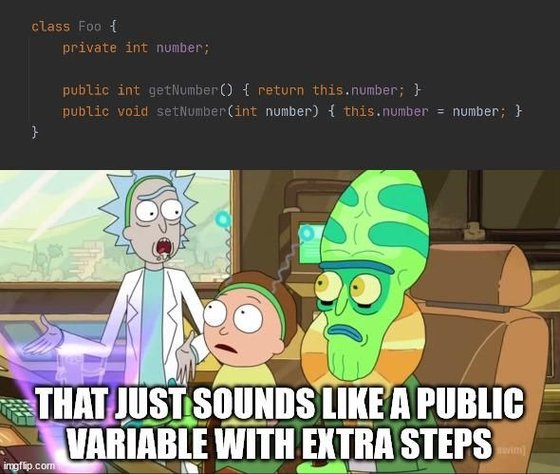

*Шесть строк Java, чтобы хранить одно число, — и ещё по три на каждое следующее поле. В Python поле — это просто поле, а `@dataclass` по трём строкам аннотаций сам пишет `__init__`, `__repr__` и `__eq__`. Понадобится проверка при создании — будет `__post_init__`, итог на лету посчитает `property`; обе штуки чуть ниже. Лишние шаги оставим тем, кому платят за строки.*

*Sáu dòng Java để lưu một con số — và thêm ba dòng nữa cho mỗi trường tiếp theo. Trong Python trường chỉ là trường, còn `@dataclass` từ ba dòng annotation tự viết `__init__`, `__repr__` và `__eq__`. Cần kiểm tra khi tạo — sẽ có `__post_init__`, còn tổng thì `property` tính ngay khi truy cập; cả hai ngay bên dưới. Các bước thừa ta để lại cho những ai được trả tiền theo số dòng.*

## 🎤 Угадай вывод: два одинаковых чека

*🎤 Спросите зал до запуска. В разделе 3 два одинаковых объекта были не равны. А теперь?*

```python
a = Expense("Граф Дебажный", 300, "вода")
b = Expense("Граф Дебажный", 300, "вода")
print(a == b, a is b)
```

## 🎤 Đoán output: hai tờ hóa đơn giống nhau

*🎤 Hỏi cả lớp trước khi chạy. Ở mục 3 hai object giống nhau không bằng nhau. Còn bây giờ?*

```python
a = Expense("Граф Дебажный", 300, "вода")
b = Expense("Граф Дебажный", 300, "вода")
print(a == b, a is b)
```

In [71]:
a = Expense("Граф Дебажный", 300, "вода")
b = Expense("Граф Дебажный", 300, "вода")
print(a == b, a is b)

True False


`True False`. Сгенерированный `__eq__` сравнивает поле за полем — всё совпало, значит, равны. Но это **два разных объекта**, и `is` честно это говорит: `==` — «одинаковые ли?», `is` — «тот же самый ли?». Обещание раздела 3 закрыто.

`True False`. `__eq__` được sinh ra so sánh từng trường — mọi thứ khớp, nên bằng nhau. Nhưng đây là **hai object khác nhau**, và `is` nói đúng điều đó: `==` — "có giống nhau không?", `is` — "có phải chính nó không?". Lời hứa ở mục 3 đã được thực hiện.

## Аннотации — подсказка, а не охрана

`amount: int` выглядит как строгое требование. А если Граф Дебажный запишет в сумму своё честное мнение?

## Annotation — gợi ý, không phải bảo vệ

`amount: int` trông như một yêu cầu nghiêm ngặt. Còn nếu Graf Debazhny ghi vào số tiền ý kiến trung thực của mình thì sao?

In [72]:
weird = Expense("Граф Дебажный", "много", "совесть")
print(weird)
print(weird.amount * 2)

Граф Дебажный: совесть — много ₽
многомного


Прошло, а «много» умножилось на два и стало «многомного». Аннотации — подсказка для вас, редактора и линтера. Python их **не проверяет** — ни в 3.13, ни в 3.15.

Проверять будем сами, в методе `__post_init__`: сгенерированный `__init__` раскладывает аргументы по полям и вызывает его, если он есть. Туда переедет правило «отрицательную трату не принимаем», которое раньше охранял `add()`. Теперь кривой чек нельзя даже создать.

И добавим `frozen=True`: поля замороженного объекта менять нельзя. Чек задним числом не переписывают — ошибся Бобр Иваныч в сумме, пусть выписывает новый.

Финальная версия `Expense`, ошибка — наша, `InvalidExpense` из раздела 5:

Qua rồi, và "много" ("nhiều") nhân hai thành "многомного". Annotation là gợi ý cho bạn, editor và linter. Python **không kiểm tra** chúng — không phải ở 3.13, cũng không phải ở 3.15.

Ta sẽ tự kiểm tra, trong method `__post_init__`: `__init__` được sinh ra rải các đối số vào các trường và gọi nó nếu có. Vào đó sẽ chuyển quy tắc "không nhận khoản chi âm" mà trước đây `add()` canh giữ. Giờ hóa đơn lệch thậm chí không thể tạo ra.

Và thêm `frozen=True`: các trường của object bị đóng băng thì không sửa được. Hóa đơn không viết lại về sau — Bobr Ivanych nhầm số tiền thì cứ lập hóa đơn mới.

Phiên bản cuối của `Expense`, lỗi là của ta, `InvalidExpense` từ mục 5:

In [73]:
@dataclass(frozen=True)
class Expense:
    payer: str
    amount: int     # целые рубли
    reason: str

    def __post_init__(self) -> None:
        if type(self.amount) is not int:
            raise TypeError(f"Сумма — целое число рублей, а не {self.amount!r}")
        if self.amount <= 0:
            raise InvalidExpense(self.amount)

    def describe(self) -> str:
        return f"{self.payer}: {self.reason} — {self.amount} ₽"

    def __str__(self) -> str:
        return self.describe()


print(Expense("Бобр Иваныч", 1200, "уголь"))

for args in [("Граф Дебажный", "много", "совесть"), ("Граф Дебажный", -500, "возврат долга самому себе")]:
    try:
        Expense(*args)
    except (TypeError, LedgerError) as error:
        print(f"{type(error).__name__}: {error}")

Бобр Иваныч: уголь — 1200 ₽
TypeError: Сумма — целое число рублей, а не 'много'
InvalidExpense: Сумма должна быть положительной: -500


Нормальный чек создался, «много» отбито `TypeError`, минус пятьсот — `InvalidExpense`. Почему `type(...) is not int`, а не `isinstance`? Потому что `isinstance(obj, Cls)` спрашивает «экземпляр ли этого класса или его потомка?», а `bool` — потомок `int`: `True == 1`. Чек на `True` рублей я не приму.

Теперь попробуем подправить чек задним числом:

Hóa đơn bình thường được tạo, "много" bị `TypeError` chặn, âm năm trăm — `InvalidExpense`. Vì sao `type(...) is not int` mà không phải `isinstance`? Vì `isinstance(obj, Cls)` hỏi "có phải instance của class này hoặc hậu duệ của nó không?", mà `bool` là hậu duệ của `int`: `True == 1`. Hóa đơn `True` rúp tôi sẽ không nhận.

Giờ thử sửa hóa đơn về sau:

In [74]:
coal = Expense("Бобр Иваныч", 1200, "уголь")
coal.amount = 12   # ⚠️ упадёт специально: чек заморожен

FrozenInstanceError: cannot assign to field 'amount'

`FrozenInstanceError: cannot assign to field 'amount'`. Оговорка: заморозка **неглубокая**. Будь полем список, заменить его было бы нельзя, а `append` в него — пожалуйста. У нас поля — строки и числа, так что заморожено всерьёз.

`FrozenInstanceError: cannot assign to field 'amount'`. Lưu ý: đóng băng là **nông**. Nếu trường là list thì không thể thay nó, nhưng `append` vào nó thì được. Ở ta các trường là string và số, nên đóng băng là thật sự.

## Журнал: ловушка изменяемого дефолта, которую мы уже знаем

Переделаем и журнал. У него есть поле `_expenses` — список, который должен быть пустым при создании. Напрашивается так:

## Sổ: cái bẫy default mutable mà ta đã biết

Làm lại cả cuốn sổ. Nó có trường `_expenses` — list phải rỗng khi tạo. Cách nghĩ ngay ra là thế này:

In [75]:
@dataclass
class TripLedger:
    title: str
    _expenses: list[Expense] = []   # ⚠️ упадёт специально

ValueError: mutable default <class 'list'> for field _expenses is not allowed: use default_factory

Упало ещё **при определении** класса: `ValueError: mutable default <class 'list'> for field _expenses is not allowed: use default_factory` — «изменяемое значение по умолчанию не разрешено».

Узнаёте `def add_task(task, tasks=[])` из прошлой лекции? Все журналы делили бы один список — холодильник на всё общежитие. Только тут dataclass бьёт по рукам сразу.

Подсказка в тексте ошибки: `default_factory`. Нужен не готовый список, а **рецепт** — функция, которую вызовут для каждого нового журнала. `list()` как раз возвращает новый пустой список. А `init=False` убирает поле из параметров `__init__`: список журнал заводит сам.

`total()` пока остаётся методом. И добавим `to_data()` — зачем, увидите через минуту:

Lỗi ngay **khi định nghĩa** class: `ValueError: mutable default <class 'list'> for field _expenses is not allowed: use default_factory` — "giá trị mặc định mutable không được phép".

Nhận ra `def add_task(task, tasks=[])` từ bài trước không? Mọi cuốn sổ sẽ dùng chung một list — cái tủ lạnh cho cả ký túc xá. Chỉ khác là ở đây dataclass đánh vào tay ngay lập tức.

Gợi ý nằm trong văn bản lỗi: `default_factory`. Cần không phải list có sẵn mà là **công thức** — hàm sẽ được gọi cho mỗi cuốn sổ mới. `list()` đúng là trả về list rỗng mới. Còn `init=False` gỡ trường khỏi tham số của `__init__`: list do sổ tự tạo.

`total()` tạm vẫn là method. Và thêm `to_data()` — để làm gì, một phút nữa sẽ thấy:

In [76]:
@dataclass
class TripLedger:
    title: str
    _expenses: list[Expense] = field(default_factory=list, init=False)

    def add(self, expense: Expense) -> None:
        self._expenses.append(expense)   # проверка суммы теперь живёт в Expense

    def total(self) -> int:
        total = 0
        for expense in self._expenses:
            total += expense.amount
        return total

    def __len__(self) -> int:
        return len(self._expenses)

    def to_data(self) -> dict:
        return {
            "title": self.title,
            "expenses": [asdict(expense) for expense in self._expenses],
        }


ledger = TripLedger("Последний шашлык")   # ярлык ledger переклеили на новый журнал
ledger.add(Expense("Бобр Иваныч", 1200, "уголь"))
ledger.add(Expense("Граф Дебажный", 300, "вода"))
print(ledger)
print(TripLedger("Поминки дедлайна"))
print(handlers["/итого"](ledger))

TripLedger(title='Последний шашлык', _expenses=[Expense(payer='Бобр Иваныч', amount=1200, reason='уголь'), Expense(payer='Граф Дебажный', amount=300, reason='вода')])
TripLedger(title='Поминки дедлайна', _expenses=[])
total_handler: 0.000002 с
Последний шашлык: 1500 ₽


Сгенерированный `__repr__` показал и название, и все чеки. Второй журнал пустой — холодильники раздельные.

А обработчик `/итого` из раздела 9 мы не трогали, но он работает и с новым журналом: `timer` напечатал время, ответ — 1500 ₽. Был бы `title` и метод `total()` — утиная типизация из раздела 4. В следующем разделе мы это сломаем.

`__repr__` được sinh ra hiện cả tên lẫn mọi hóa đơn. Cuốn sổ thứ hai rỗng — các tủ lạnh tách riêng.

Còn handler `/итого` từ mục 9 ta không đụng tới, mà nó vẫn chạy với cuốn sổ mới: `timer` in thời gian, câu trả lời — 1500 ₽. Chỉ cần có `title` và method `total()` — duck typing từ mục 4. Ở mục sau ta sẽ làm hỏng nó.

## JSON: закрываем обещание прошлой лекции

В Л3 JSON без проблем съедал словари, списки, строки и числа. А вот, например, множество `json.dumps` не берёт: `Object of type set is not JSON serializable`. Это было в ⏩-блоке «Что JSON не умеет», и там я обещал, что со своими объектами будет то же самое. Проверим:

## JSON: thực hiện lời hứa của bài trước

Ở B3 JSON nuốt trôi dictionary, list, string và số. Còn, chẳng hạn, set thì `json.dumps` không nhận: `Object of type set is not JSON serializable`. Chuyện này nằm trong khối ⏩ "Những gì JSON không làm được", và ở đó tôi hứa rằng với object của riêng mình cũng sẽ như vậy. Kiểm tra:

In [77]:
import json

json.dumps(ledger)   # ⚠️ упадёт специально

TypeError: Object of type TripLedger is not JSON serializable

`TypeError: Object of type TripLedger is not JSON serializable`. Лечится так же, как множество в Л3: **перед записью превращаем в то, что JSON понимает**. Это и делает `to_data()`: `asdict()` превращает чек в словарь, а что положить в словарь журнала и под какими именами — решаем мы, явно:

`TypeError: Object of type TripLedger is not JSON serializable`. Chữa như với set ở B3: **trước khi ghi, chuyển thành thứ JSON hiểu**. Đó là việc của `to_data()`: `asdict()` biến hóa đơn thành dictionary, còn bỏ gì vào dictionary của sổ và dưới tên nào — ta quyết định, tường minh:

In [78]:
text = json.dumps(ledger.to_data(), ensure_ascii=False, indent=2)
print(text)

data = json.loads(text)
print(type(data["expenses"][0]))

restored = TripLedger(data["title"])
for item in data["expenses"]:
    restored.add(Expense(**item))   # ** раскладывает словарь в именованные аргументы
print(restored == ledger)

{
  "title": "Последний шашлык",
  "expenses": [
    {
      "payer": "Бобр Иваныч",
      "amount": 1200,
      "reason": "уголь"
    },
    {
      "payer": "Граф Дебажный",
      "amount": 300,
      "reason": "вода"
    }
  ]
}
<class 'dict'>
True


Нормальный JSON с русскими буквами — хоть сейчас в файл.

А теперь важное: `json.loads` вернул **словари**, а не чеки. JSON не знает ваших классов, магического «обратно в объект» не бывает. Собираем руками: `Expense(**item)` — те же две звёздочки, что в `**kwargs` из прошлой лекции, только наоборот, при вызове: словарь `{"payer": …, "amount": …, "reason": …}` раскладывается в именованные аргументы `payer=…, amount=…, reason=…`. Со списком и одной звёздочкой мы так уже делали — `flexible_sum(*prices)`. И и заодно снова срабатывает `__post_init__`, так что кривой чек из испорченного файла не пролезет. Последняя строка — `True`: журнал восстановлен поле в поле.

> 🤖 **Где ошибается ваш ИИ.** На ошибку «not JSON serializable» правдоподобный ответ — `json.dumps(ledger, default=str)`. Ошибка исчезает, только в файл попадает одна строка — `repr` журнала — вместо структуры с полями. Прочитать её обратно в объект нельзя. Ошибку спрятали, задачу не решили. Нужен явный `to_data()`.

Вот как выглядит такой «JSON»:

JSON bình thường với chữ Nga — có thể ghi vào file ngay.

Còn giờ là điều quan trọng: `json.loads` trả về **dictionary**, không phải hóa đơn. JSON không biết class của bạn, không có chuyện "tự về thành object" bằng phép màu. Lắp bằng tay: `Expense(**item)` — hai dấu sao như trong `**kwargs` ở bài trước, chỉ là ngược lại, ở lời gọi: dictionary `{"payer": …, "amount": …, "reason": …}` được rải thành đối số có tên `payer=…, amount=…, reason=…`. Với list và một dấu sao ta đã làm vậy — `flexible_sum(*prices)`. Và nhân tiện `__post_init__` lại chạy, nên hóa đơn lệch từ file hỏng không lọt qua. Dòng cuối — `True`: sổ được khôi phục từng trường một.

> 🤖 **AI của bạn sai ở đâu.** Trước lỗi "not JSON serializable", câu trả lời trông hợp lý là `json.dumps(ledger, default=str)`. Lỗi biến mất, chỉ là vào file sẽ là một dòng — `repr` của sổ — thay vì cấu trúc có các trường. Đọc ngược nó thành object không được. Lỗi bị giấu, bài toán chưa được giải. Cần `to_data()` tường minh.

Đây là "JSON" như vậy trông ra sao:

In [79]:
print(json.dumps(ledger, default=str, ensure_ascii=False))

"TripLedger(title='Последний шашлык', _expenses=[Expense(payer='Бобр Иваныч', amount=1200, reason='уголь'), Expense(payer='Граф Дебажный', amount=300, reason='вода')])"


Одна строка в кавычках, похожая на код. Достаньте из неё сумму второго чека без регулярных выражений и слёз.

Есть и библиотеки, которые проверяют типы и собирают объекты из JSON сами. Самая известная — Pydantic, на ней стоит aiogram; пара слов о ней — в блоке 📚 в конце тетрадки.

Một dòng trong ngoặc kép, giống code. Hãy lấy từ nó số tiền của hóa đơn thứ hai mà không dùng biểu thức chính quy và không khóc.

Cũng có những thư viện tự kiểm tra kiểu và tự lắp object từ JSON. Nổi tiếng nhất là Pydantic, aiogram đứng trên nó; vài lời về nó — ở khối 📚 cuối notebook.

# 11. `property`: метод, который притворяется полем

Посмотрите на `ledger.total()`. Скобки говорят: «сделай что-нибудь». Отправь сообщение, удали файл, начисли штраф. А итог журнала — не действие, это **свойство** журнала, как название. Мы же не пишем `ledger.title()`. Хочется писать `ledger.total`, но при этом каждый раз честно пересчитывать сумму. Хранить её отдельным полем опасно: добавили чек, забыли обновить итог — и журнал врёт.

Для этого есть декоратор `@property`. Метод под ним вызывается **при чтении атрибута**, без скобок. И да, это тоже декоратор: `property` принимает функцию и возвращает объект, который знает, что делать при обращении `ledger.total`. Декораторы бывают не только над функциями: `@property` стоит над методом, а `@dataclass` из раздела 10 — над целым классом. Это и есть декоратор класса: он получает класс и возвращает класс.

Переопределяем `TripLedger` ещё раз — по традиции, старый журнал остаётся старого класса, создаём новый:

# 11. `property`: method giả làm trường

Hãy nhìn `ledger.total()`. Dấu ngoặc nói: "hãy làm gì đó". Gửi tin nhắn, xóa file, tính tiền phạt. Còn tổng của sổ không phải hành động, mà là **tính chất** của sổ, như tên. Ta đâu viết `ledger.title()`. Muốn viết `ledger.total`, nhưng mỗi lần vẫn tính lại tổng cho đúng. Lưu nó thành trường riêng thì nguy hiểm: thêm hóa đơn, quên cập nhật tổng — và sổ nói dối.

Có decorator `@property` cho việc này. Method bên dưới nó được gọi **khi đọc attribute**, không cần ngoặc. Và đúng, đây cũng là decorator: `property` nhận hàm và trả về object biết cần làm gì khi truy cập `ledger.total`. Decorator không chỉ đặt trên hàm: `@property` đứng trên method, còn `@dataclass` từ mục 10 — trên cả class. Đó chính là class decorator: nó nhận class và trả về class.

Định nghĩa lại `TripLedger` một lần nữa — theo thông lệ, sổ cũ vẫn thuộc class cũ, ta tạo sổ mới:

In [80]:
@dataclass
class TripLedger:
    title: str
    _expenses: list[Expense] = field(default_factory=list, init=False)

    def add(self, expense: Expense) -> None:
        self._expenses.append(expense)

    @property
    def total(self) -> int:
        total = 0
        for expense in self._expenses:
            total += expense.amount
        return total

    def __len__(self) -> int:
        return len(self._expenses)

    def to_data(self) -> dict:
        return {"title": self.title, "expenses": [asdict(expense) for expense in self._expenses]}


ledger = TripLedger("Последний шашлык")
ledger.add(Expense("Бобр Иваныч", 1200, "уголь"))
ledger.add(Expense("Граф Дебажный", 300, "вода"))
print(ledger.total)
ledger.add(Expense("Бобр Иваныч", 450, "шампуры взамен утопленных"))
print(ledger.total)

1500
1950


Без скобок, и итог всегда свежий: 1500, потом 1950. Хранить нечего — нечему и устаревать.

Không ngoặc, và tổng luôn mới: 1500, rồi 1950. Không có gì để lưu — thì cũng không có gì để lỗi thời.

## Мы только что сломали бота

А теперь обещанная поломка. Обработчик `/итого` в реестре всё ещё старый — он вызывает `ledger.total()` со скобками. Вызовем его с новым журналом:

## Ta vừa làm hỏng bot

Giờ là sự cố đã hứa. Handler `/итого` trong registry vẫn là bản cũ — nó gọi `ledger.total()` có ngoặc. Gọi nó với cuốn sổ mới:

In [81]:
handlers["/итого"](ledger)   # ⚠️ упадёт специально: обработчик писали под старый класс

total_handler: 0.000004 с


TypeError: 'int' object is not callable

`TypeError: 'int' object is not callable`. Читаем по слогам: `ledger.total` уже вернул число 1950, а потом мы приписали к нему скобки и попытались число **вызвать**. Обратите внимание: строчка таймера всё равно напечаталась. Это `finally` из обёртки отработал даже при падении — ровно как мы задумывали в разделе 8.

Мораль. Поменяли интерфейс класса — проверьте всех, кто им пользуется. В реестре лежит старый объект функции, и сам он не обновится: словарь хранит то, что в него положили при регистрации. Перерегистрируем обработчик под новый класс — тот же ключ, новая функция:

`TypeError: 'int' object is not callable`. Đọc từng âm tiết: `ledger.total` đã trả về số 1950, rồi ta gắn thêm ngoặc và cố **gọi** con số. Lưu ý: dòng timer vẫn được in ra. Đó là `finally` trong wrapper chạy dù bị lỗi — đúng như ta dự tính ở mục 8.

Bài học. Đổi interface của class — hãy kiểm tra mọi nơi dùng nó. Trong registry nằm object hàm cũ, và tự nó không cập nhật: dictionary lưu cái đã bỏ vào lúc đăng ký. Đăng ký lại handler cho class mới — cùng key, hàm mới:

In [82]:
@command("/итого")
@timer
def total_handler(ledger: TripLedger) -> str:
    return f"{ledger.title}: {ledger.total} ₽"


print(handlers["/итого"](ledger))

total_handler: 0.000002 с
Последний шашлык: 1950 ₽


Заработало. Старая функция выпала из реестра — её место под ключом `/итого` заняла новая.

Chạy rồi. Hàm cũ rơi khỏi registry — chỗ của nó dưới key `/итого` được hàm mới chiếm.

## 🎤 Угадай вывод: можно ли переписать итог?

*🎤 Спросите зал: что напечатает первая строка и что случится на второй?*

```python
print(ledger.total)
ledger.total = 0
```

## 🎤 Đoán output: có thể ghi đè tổng không?

*🎤 Hỏi cả lớp: dòng đầu in gì và dòng hai xảy ra chuyện gì?*

```python
print(ledger.total)
ledger.total = 0
```

In [83]:
print(ledger.total)
ledger.total = 0   # ⚠️ упадёт специально

1950


AttributeError: property 'total' of 'TripLedger' object has no setter

Сначала честные 1950, потом `AttributeError: property 'total' of 'TripLedger' object has no setter` — «у свойства нет сеттера». Свойство только для чтения: итог считается из чеков, и «обнулить» его, не трогая чеки, нельзя. Хотите поменять итог — добавляйте чеки. Это и есть инвариант: журнал не может соврать о собственной сумме. Почему не получилось, как с банкой `Jar`, где присваивание тихо создало атрибут у объекта? `property` — особый атрибут класса: он перехватывает и чтение, и запись раньше, чем Python заглянет в сам объект.

Đầu tiên là 1950 trung thực, rồi `AttributeError: property 'total' of 'TripLedger' object has no setter` — "property không có setter". Property chỉ đọc: tổng được tính từ các hóa đơn, và "đặt về 0" mà không đụng hóa đơn thì không được. Muốn đổi tổng — thêm hóa đơn. Đó chính là invariant: sổ không thể nói dối về tổng của chính nó. Vì sao không giống cái hũ `Jar`, nơi phép gán lặng lẽ tạo attribute ở object? `property` là class attribute đặc biệt: nó chặn cả đọc lẫn ghi trước khi Python nhìn vào chính object.

## ⏩ Сеттер с проверкой

*⏩ Если зал уверенно ответил на контрольный вопрос №2 (когда работает декоратор) — пропускаем, читаете сами.*

Иногда присваивать всё-таки надо, но с проверкой. Тогда к свойству добавляют **сеттер** — метод, который вызывается при `obj.balance = ...`. Значение при этом хранится под другим именем, с подчёркиванием:

## ⏩ Setter có kiểm tra

*⏩ Nếu cả lớp trả lời chắc câu hỏi kiểm tra số 2 (khi nào decorator chạy) — ta bỏ qua, các bạn tự đọc.*

Đôi khi vẫn cần gán, nhưng có kiểm tra. Khi đó thêm vào property một **setter** — method được gọi khi `obj.balance = ...`. Giá trị lúc này được lưu dưới tên khác, có gạch dưới:

In [84]:
class Wallet:
    def __init__(self, owner: str, balance: int):
        self.owner = owner
        self.balance = balance   # уже через сеттер — проверка работает и при создании

    @property
    def balance(self) -> int:
        return self._balance

    @balance.setter
    def balance(self, value: int) -> None:
        if value < 0:
            raise ValueError(f"У {self.owner} не может быть {value} ₽: кредитов не выдаём")
        self._balance = value


wallet = Wallet("Граф Дебажный", 500)
wallet.balance -= 200
print(wallet.balance)
wallet.balance -= 1000   # ⚠️ упадёт специально

300


ValueError: У Граф Дебажный не может быть -700 ₽: кредитов не выдаём

Снаружи `wallet.balance` выглядит как обычное поле, а внутри каждое присваивание проходит проверку: 300 приняли, минус семьсот — `ValueError`. Только не ставьте сеттеры на всё подряд «на всякий случай». Начинайте с обычного атрибута, а `property` добавляйте, когда появилось правило, которое надо охранять.

Từ bên ngoài `wallet.balance` trông như trường thường, còn bên trong mỗi phép gán đều qua kiểm tra: 300 chấp nhận, âm bảy trăm — `ValueError`. Chỉ đừng đặt setter lên mọi thứ "phòng khi". Hãy bắt đầu bằng attribute thường, còn `property` thêm khi đã xuất hiện quy tắc cần canh giữ.

## ⏩ Грабли: свойство, которое зовёт само себя

*⏩ Если зал уверенно ответил на контрольный вопрос №2 (когда работает декоратор) — пропускаем, читаете сами.*

Почему значение лежит в `self._balance`, а не в `self.balance`? Смотрите, что будет, если забыть подчёркивание:

## ⏩ Cạm bẫy: property tự gọi chính mình

*⏩ Nếu cả lớp trả lời chắc câu hỏi kiểm tra số 2 (khi nào decorator chạy) — ta bỏ qua, các bạn tự đọc.*

Vì sao giá trị nằm ở `self._balance`, mà không phải `self.balance`? Xem chuyện gì xảy ra nếu quên gạch dưới:

In [85]:
class BrokenWallet:
    @property
    def balance(self) -> int:
        return self.balance   # чтение balance снова вызывает balance


try:
    BrokenWallet().balance
except RecursionError as error:
    print(f"RecursionError: {error}")   # трейсбек на тысячу одинаковых кадров не печатаем

RecursionError: maximum recursion depth exceeded


`RecursionError: maximum recursion depth exceeded`. Чтение `self.balance` внутри свойства `balance` снова запускает свойство `balance`, оно снова читает `self.balance`… и так, пока Python не сдастся. Свойство и хранилище — разные имена, всегда.

`RecursionError: maximum recursion depth exceeded`. Việc đọc `self.balance` bên trong property `balance` lại khởi động property `balance`, nó lại đọc `self.balance`… và cứ thế đến khi Python bỏ cuộc. Property và nơi lưu trữ — luôn là hai tên khác nhau.

# 12. Мост к ботам: два чата, один код

Вся лекция была подготовкой к этому разделу. Через неделю у вас будет Telegram-бот, и в него напишут из двух чатов: в одном считают «Последний шашлык», в другом — «Поминки дедлайна». Один журнал на всех — и уголь Бобра Иваныча окажется в счёте за поминки.

В Telegram у каждого чата есть номер — `chat_id`. Значит, нужен словарь: номер чата → журнал этого чата. Номера возьмём выдуманные, 101 и 202:

# 12. Cầu nối sang bot: hai chat, một code

Cả bài giảng là sự chuẩn bị cho mục này. Một tuần nữa bạn sẽ có Telegram bot, và người ta sẽ nhắn vào nó từ hai chat: một chat tính «Последний шашлык», chat kia — «Поминки дедлайна». Một cuốn sổ cho tất cả — và than của Bobr Ivanych sẽ nằm trong hóa đơn đám tang.

Trong Telegram mỗi chat có số — `chat_id`. Nghĩa là cần dictionary: số chat → sổ của chat đó. Số ta lấy bịa ra, 101 và 202:

In [86]:
ledgers = {
    101: TripLedger("Последний шашлык"),
    202: TripLedger("Поминки дедлайна"),
}
ledgers[101].add(Expense("Бобр Иваныч", 1200, "уголь"))
ledgers[101].add(Expense("Граф Дебажный", 300, "вода"))
ledgers[202].add(Expense("Граф Дебажный", 990, "пицца на помин души курсовой"))

for chat_id, chat_ledger in ledgers.items():
    print(chat_id, chat_ledger.title, chat_ledger.total, len(chat_ledger))

101 Последний шашлык 1500 2
202 Поминки дедлайна 990 1


Ничего не перепуталось: 1500 у шашлыка, 990 у поминок.

Không lẫn gì cả: 1500 ở chuyến nướng thịt, 990 ở đám tang.

## Тонкий обработчик

В боте обработчик вызываете не вы, а библиотека — когда приходит сообщение, и передаёт ему это сообщение. Значит, журнал обработчик должен найти сам, по номеру чата.

Сообщение изобразим игрушечным dataclass; в пятой лекции его создаст библиотека. И главное правило: обработчик — **тонкий**. Достал из сообщения нужное, позвал прикладной объект, вернул ответ. Суммы он не считает, данные не хранит, с файлами не возится: считает журнал, хранит словарь. Таймер снимаем.

## Handler mỏng

Trong bot, handler không do bạn gọi mà do thư viện — khi tin nhắn tới, và nó truyền tin nhắn đó vào handler. Nghĩa là handler phải tự tìm sổ theo số chat.

Tin nhắn ta mô phỏng bằng dataclass đồ chơi; ở bài thứ năm thư viện sẽ tạo nó. Và quy tắc chính: handler phải **mỏng**. Lấy từ tin nhắn cái cần, gọi object nghiệp vụ, trả câu trả lời. Nó không tính tổng, không lưu dữ liệu, không loay hoay với file: sổ tính, dictionary lưu. Bỏ timer.

In [87]:
@dataclass
class Message:          # игрушка: в Л5 сообщение придёт от библиотеки
    chat_id: int
    text: str


@command("/итого")
def total_command(message: Message) -> str:
    ledger = ledgers.get(message.chat_id)
    if ledger is None:
        return "В этом чате журнала нет. Шашлык без бухгалтерии — просто шашлык."
    return f"{ledger.title}: {ledger.total} ₽, трат: {len(ledger)}"


print(total_command(Message(101, "/итого")))

Последний шашлык: 1500 ₽, трат: 2


Ключ тот же, `/итого`, так что `total_handler` из реестра опять выпал. И мы только что вызвали обработчик бота **без всякого Telegram** — обычной функцией. Тонкий обработчик проверяется за секунду, без сети, токена и телефона. Вот первый в вашей жизни автотест:

Key như cũ, `/итого`, nên `total_handler` trong registry lại rơi ra. Và ta vừa gọi handler của bot **không cần Telegram** — như hàm thông thường. Handler mỏng được kiểm tra trong một giây, không cần mạng, token hay điện thoại. Đây là autotest đầu tiên trong đời bạn:

In [88]:
assert total_command(Message(101, "/итого")) == "Последний шашлык: 1500 ₽, трат: 2"
assert total_command(Message(303, "/итого")).startswith("В этом чате журнала нет")
print("Оба теста прошли")

Оба теста прошли


`assert` молчит, если условие верно, и падает, если нет. Раз дошли до `print` — оба теста зелёные.

`assert` im lặng nếu điều kiện đúng và lỗi nếu sai. Đã tới được `print` — cả hai test đều xanh.

## Кто вызывает обработчик

Теперь изобразим то, что сделает за нас библиотека: пришло сообщение — берём первое слово, ищем в реестре `handlers`, вызываем найденное. Это и есть второй навык лекции — кто, когда и какую функцию вызывает:

## Ai gọi handler

Giờ mô phỏng việc thư viện sẽ làm hộ ta: có tin nhắn tới — lấy từ đầu tiên, tìm trong registry `handlers`, gọi cái tìm được. Đó chính là kỹ năng thứ hai của bài — ai, khi nào và gọi hàm nào:

In [89]:
def dispatch(message: Message) -> str:
    name = message.text.split()[0]
    handler = handlers.get(name)
    if handler is None:
        return f"Не знаю команды {name}"
    return handler(message)


for message in [Message(101, "/итого"), Message(202, "/итого"), Message(303, "/итого"), Message(101, "/шашлык")]:
    print(f"чат {message.chat_id}: {dispatch(message)}")

чат 101: Последний шашлык: 1500 ₽, трат: 2
чат 202: Поминки дедлайна: 990 ₽, трат: 1
чат 303: В этом чате журнала нет. Шашлык без бухгалтерии — просто шашлык.
чат 101: Не знаю команды /шашлык


Четыре сообщения — четыре ответа: у шашлыка свой итог, у поминок свой, в чате 303 журнала нет, а команды `/шашлык` нет вовсе, как бы нам ни хотелось. Про конкретный чат в обработчике ни строчки — всё решает словарь.

В пятой лекции вы напишете `@router.message(...)` или `@bot.message_handler(...)`, и библиотека сделает ровно это: положит функцию в реестр и будет вызывать её на подходящие сообщения. Магии нет — словарь и вызов. Деталь: в настоящем Telegram команды пишут латиницей, `/total`; кириллица у нас для наглядности.

Для диалога с конкретным человеком внутри группы одного `chat_id` мало — ключом станет кортеж `(chat_id, user_id)`.

Bốn tin nhắn — bốn câu trả lời: chuyến nướng thịt có tổng riêng, đám tang có tổng riêng, chat 303 không có sổ, còn lệnh `/шашлык` thì không có hẳn, dù ta có muốn thế nào. Về chat cụ thể trong handler không có một dòng — mọi thứ do dictionary quyết định.

Ở bài thứ năm bạn sẽ viết `@router.message(...)` hoặc `@bot.message_handler(...)`, và thư viện sẽ làm đúng điều đó: đặt hàm vào registry và gọi nó với các tin nhắn phù hợp. Không có ma thuật — dictionary và lời gọi. Chi tiết: trong Telegram thật lệnh viết bằng chữ Latin, `/total`; chữ Cyrillic ở đây chỉ để dễ nhìn.

Với đối thoại với một người cụ thể trong nhóm thì một `chat_id` là chưa đủ — key sẽ là tuple `(chat_id, user_id)`.

## Память — не хранилище

Словарь `ledgers` живёт в оперативной памяти. Перезапустите ядро — и шашлык забыт. С ботом так же: перезапустили скрипт после правки — журналы всех чатов обнулились. Это не баг, так устроена память. Сохранение — отдельная работа: например, `to_data()` и JSON в файл после каждой траты, при старте — загрузка. Сам `class` ничего никуда не сохраняет.

## Bộ nhớ — không phải kho lưu trữ

Dictionary `ledgers` sống trong RAM. Khởi động lại kernel — và buổi nướng thịt bị quên. Với bot cũng vậy: khởi động lại script sau khi sửa — sổ của mọi chat về 0. Đó không phải bug, bộ nhớ vốn thế. Lưu trữ là một công việc riêng: chẳng hạn `to_data()` và JSON vào file sau mỗi khoản chi, còn khi khởi động — nạp lại. Bản thân `class` không lưu gì đi đâu cả.

## Итоговая картинка: из чего состоит бот

Частая ошибка — думать, что бот это один огромный объект `MyBot`, в котором и Telegram, и журналы, и подсчёт, и файлы. Через месяц такой класс на тысячу строк не прочитает даже автор. Правильная картинка из трёх частей:

> **Объект библиотеки** для общения с Telegram + **прикладные объекты** с вашими данными и правилами + **функции-обработчики**, которые их связывают.

Объект библиотеки принимает и отправляет сообщения — его пишете не вы. Прикладные объекты — `Expense`, `TripLedger`, `ledgers` — ничего не знают о Telegram, поэтому проверяются в тетрадке. Обработчики — тонкие функции посередине. Это мы сегодня и построили, только вместо Telegram пока `dispatch`.

> 🔑 **Токен = пароль.** В пятой лекции у бота появится токен. Кто знает токен, тот и есть ваш бот: пишет от его имени вашим пользователям. Поэтому токен — не в репозиторий, не в сохранённый вывод тетрадки и не в скриншот в чат группы. Утёк — сразу перевыпускайте у @BotFather.

## Bức tranh tổng kết: bot gồm những gì

Sai lầm thường gặp — nghĩ rằng bot là một object khổng lồ `MyBot`, trong đó có cả Telegram, sổ, tính toán và file. Một tháng sau class một nghìn dòng như vậy thậm chí tác giả cũng không đọc nổi. Bức tranh đúng gồm ba phần:

> **Object của thư viện** để giao tiếp với Telegram + **object nghiệp vụ** với dữ liệu và quy tắc của bạn + **hàm handler** nối chúng lại.

Object của thư viện nhận và gửi tin nhắn — nó không do bạn viết. Các object nghiệp vụ — `Expense`, `TripLedger`, `ledgers` — không biết gì về Telegram, nên được kiểm tra ngay trong notebook. Handler — các hàm mỏng ở giữa. Hôm nay ta đã xây đúng cái đó, chỉ là thay vì Telegram tạm thời là `dispatch`.

> 🔑 **Token = mật khẩu.** Ở bài thứ năm bot sẽ có token. Ai biết token thì người đó chính là bot của bạn: viết nhân danh nó tới người dùng của bạn. Vì thế token — không để vào repository, không vào output được lưu của notebook và không trong ảnh chụp màn hình gửi vào chat nhóm. Lộ rồi — phát hành lại ngay ở @BotFather.

## Тизер: `async` и `await`

В пятой лекции, скорее всего, будет aiogram 3, а там обработчики начинаются с `async def`. Пять минут, чтобы это не стало шоком. Три тезиса. Первый: вызов `async def`-функции **не выполняет тело**, а создаёт объект-корутину — обещание работы. Второй: `await` запускает корутину и ждёт результат. Третий, его забывают: `async` не ускоряет медленный код — `time.sleep` внутри `async def` всё равно остановит всё.

В Jupyter `await` можно писать прямо в ячейке — это верхнеуровневый `await`:

## Teaser: `async` và `await`

Ở bài thứ năm nhiều khả năng sẽ là aiogram 3, và ở đó handler bắt đầu bằng `async def`. Năm phút để điều này không thành cú sốc. Ba luận điểm. Một: lời gọi hàm `async def` **không thực thi thân hàm**, mà tạo object coroutine — lời hứa về công việc. Hai: `await` chạy coroutine và chờ kết quả. Ba, điều hay bị quên: `async` không làm code chậm nhanh lên — `time.sleep` bên trong `async def` vẫn dừng tất cả.

Trong Jupyter có thể viết `await` ngay trong ô — đó là top-level `await`:

In [90]:
import asyncio


async def total_async(ledger: TripLedger) -> str:
    await asyncio.sleep(0.1)   # делаем вид, что ходим в сеть
    return f"{ledger.title}: {ledger.total} ₽"


coro = total_async(ledgers[101])
print(coro)          # тело ещё не выполнялось
print(await coro)    # а вот теперь выполнилось

<coroutine object total_async at 0x7434a4a8d7d0>
Последний шашлык: 1500 ₽


Первый `print` — `<coroutine object total_async at 0x…>`: функция «вызвалась», тело — нет. После `await` — результат. Снова два разных момента, как у декоратора и обёртки.

В скрипте `.py` корутину запускают через `asyncio.run(...)`, а в Jupyter так нельзя — цикл событий (диспетчер, который по очереди будит корутины) там уже работает:

`print` đầu tiên — `<coroutine object total_async at 0x…>`: hàm "được gọi", thân thì không. Sau `await` — kết quả. Lại hai thời điểm khác nhau, như với decorator và wrapper.

Trong script `.py` coroutine được chạy qua `asyncio.run(...)`, còn trong Jupyter thì không được — event loop (bộ điều phối lần lượt đánh thức các coroutine) ở đó đã đang chạy:

In [91]:
coro = total_async(ledgers[101])
try:
    asyncio.run(coro)
except RuntimeError as error:
    print(f"RuntimeError: {error}")
    coro.close()   # прибираем невыполненную корутину, чтобы Python не ругался

RuntimeError: asyncio.run() cannot be called from a running event loop


«`asyncio.run()` нельзя вызвать из работающего цикла событий». В тетрадке — `await`, в скрипте — `asyncio.run()`, и не лечите это патчем из интернета.

И последнее: что будет, если надеть наш синхронный `timer` на корутину?

"`asyncio.run()` không thể gọi từ event loop đang chạy". Trong notebook — `await`, trong script — `asyncio.run()`, và đừng chữa bằng bản vá từ internet.

Và điều cuối: chuyện gì xảy ra nếu đặt `timer` đồng bộ của ta lên coroutine?

In [92]:
@timer
async def slow_total(ledger: TripLedger) -> str:
    await asyncio.sleep(0.1)
    return f"{ledger.title}: {ledger.total} ₽"


started = time.perf_counter()
print(await slow_total(ledgers[101]))
print(f"на самом деле: {time.perf_counter() - started:.2f} с")

slow_total: 0.000001 с
Последний шашлык: 1500 ₽
на самом деле: 0.10 с


Таймер насчитал ноль с хвостиком — от силы микросекунды, а честный замер снаружи — около десятой доли секунды. Обёртка измерила создание корутины: вернула обещание и сразу отработала `finally`. Асинхронной обёртке нужны `async def wrapper` и `await func(...)` внутри — это за рамками сегодняшнего дня. Запомните главное: синхронный декоратор на `async def` молча меряет не то.

Timer đếm được không phẩy gì đó — cùng lắm là micro giây, còn đo trung thực từ bên ngoài — khoảng một phần mười giây. Wrapper đã đo việc tạo coroutine: trả về lời hứa và `finally` chạy ngay. Wrapper bất đồng bộ cần `async def wrapper` và `await func(...)` bên trong — việc đó ngoài phạm vi hôm nay. Hãy nhớ điều chính: decorator đồng bộ trên `async def` lặng lẽ đo sai thứ.

# 13. Резерв

*🎤 Резерв: читаем, если осталось время. Не успели — студенты читают дома.*

# 13. Dự phòng

*🎤 Dự phòng: đọc nếu còn thời gian. Không kịp — sinh viên đọc ở nhà.*

## 🧨 Экстра: архитектурная космонавтика

Можно пропустить — тогда читаете дома.

Сегодня вы научились писать классы. Поздравляю: теперь вы опасны. Следующие полгода вас будет тянуть превращать в класс всё, что шевелится. Это болезнь с официальным названием — **архитектурная космонавтика**. Так называют увлечение сложными конструкциями без явной причины: архитектор улетает так высоко в абстракции, что задача внизу уже не видна.

Простой признак: если у класса два метода и один из них `__init__`, это функция, которая притворяется классом. Вот как выглядит пациент:

## 🧨 Extra: du hành vũ trụ kiến trúc

Có thể bỏ qua — khi đó các bạn đọc ở nhà.

Hôm nay bạn đã học viết class. Chúc mừng: giờ bạn nguy hiểm rồi. Nửa năm tới bạn sẽ bị kéo vào việc biến mọi thứ cử động thành class. Đây là căn bệnh có tên chính thức — **architecture astronautics** (du hành vũ trụ kiến trúc). Người ta gọi như vậy cho sự mê đắm các cấu trúc phức tạp mà không có lý do rõ ràng: kiến trúc sư bay cao đến mức trong abstraction mà bài toán ở bên dưới đã không còn nhìn thấy.

Dấu hiệu đơn giản: nếu class có hai method và một trong số đó là `__init__`, thì đó là hàm đang giả làm class. Bệnh nhân trông thế này:

In [93]:
class ReportFormatter:
    def __init__(self, ledger: TripLedger):
        self.ledger = ledger

    def format(self) -> str:
        return f"{self.ledger.title}: {self.ledger.total} ₽"


print(ReportFormatter(ledgers[101]).format())

Последний шашлык: 1500 ₽


Чтобы получить одну строку, мы создали объект, сохранили в него журнал, вызвали метод и выбросили объект. Состояния у него нет, правила нет, второго метода нет. А вот то же самое без космоса:

Để có một dòng, ta đã tạo object, lưu sổ vào nó, gọi method rồi vứt object đi. Nó không có state, không có quy tắc, không có method thứ hai. Còn đây là cái đó khi không có vũ trụ:

In [94]:
def format_report(ledger: TripLedger) -> str:
    return f"{ledger.title}: {ledger.total} ₽"


print(format_report(ledgers[101]))

Последний шашлык: 1500 ₽


Результат тот же, кода меньше, читается сразу. Класс нужен там, где есть **состояние, которое живёт между вызовами**, и **правило**, которое это состояние охраняет. У журнала и чека они есть: список трат, который живёт между вызовами, и правило, которое не пускает кривой чек. У форматировщика — нет.

А теперь — как выглядит запущенная стадия. В большой корпоративной Java есть настоящий класс с именем `AbstractSingletonProxyFactoryBean`. Это не шутка, он есть в документации фреймворка Spring. Абстрактная фабрика одиночных прокси-бинов. Там у него своя работа, но если вам для одного `print` понадобится что-то с таким именем, то печатает уже не программа, а бюджет.

В вашем ДЗ4 с ботами симптомы будут такие. Помните `BotWithDatabaseWithLoggerWithCache` от четырёх родителей из раздела 5? Это уже крик о помощи. Классы `ExpenseManager`, `ExpenseService` и `ExpenseHelper`, и никто не может объяснить, чем они отличаются. Базовый класс `AbstractHandler` с единственным наследником «на будущее» — будущее не наступит, а класс останется.

Рецепт на ДЗ4 простой. Начинайте с функций и dataclass. Класс с методами появляется, когда появилось состояние и правило. Наследование — когда «является» звучит честно, как у `InvalidExpense` и `LedgerError`. Всё остальное — композиция: журнал **содержит** чеки, а не наследуется от них.

Kết quả như nhau, code ít hơn, đọc hiểu ngay. Class cần ở nơi có **state sống giữa các lần gọi** và **quy tắc** canh giữ state đó. Sổ và hóa đơn có chúng: list khoản chi sống giữa các lần gọi, và quy tắc không cho hóa đơn lệch vào. Bộ định dạng thì không.

Còn giờ — giai đoạn nặng trông thế nào. Trong Java doanh nghiệp lớn có một class thật tên `AbstractSingletonProxyFactoryBean`. Đây không phải trò đùa, nó có trong tài liệu của framework Spring. Abstract factory của các singleton proxy bean. Ở đó nó có việc của nó, nhưng nếu để in một `print` mà bạn cần thứ gì đó có cái tên như vậy, thì người in lúc này không còn là chương trình mà là ngân sách.

Trong BTVN4 với bot, các triệu chứng sẽ như sau. Nhớ `BotWithDatabaseWithLoggerWithCache` với bốn cha ở mục 5 chứ? Đó đã là tiếng kêu cứu. Các class `ExpenseManager`, `ExpenseService` và `ExpenseHelper`, mà không ai giải thích nổi chúng khác nhau chỗ nào. Base class `AbstractHandler` với một hậu duệ duy nhất "cho tương lai" — tương lai sẽ không đến, còn class thì ở lại.

Công thức cho BTVN4 đơn giản. Bắt đầu bằng hàm và dataclass. Class có method xuất hiện khi đã có state và quy tắc. Inheritance — khi "là" nghe trung thực, như `InvalidExpense` và `LedgerError`. Mọi thứ còn lại — composition: sổ **chứa** hóa đơn, chứ không kế thừa từ chúng.

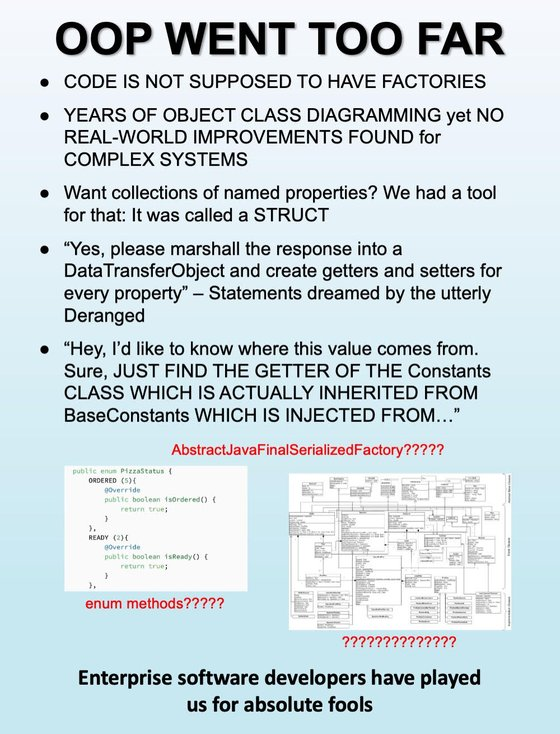

*Запущенная стадия в виде манифеста: фабрики, DTO, геттеры на каждое поле и константы, унаследованные от `BaseConstants`, внедрённого из… Чтобы узнать, откуда взялось одно значение, нужен ордер. Наша фабрика `command` из раздела 9 — не та фабрика: это одна функция в три строки, и делает она ровно одно дело. Мы на этом пути сделали ровно один шаг — `InvalidExpense` от `LedgerError` — и остановились. Правило раздела: нет состояния и правила — нет класса.*

*Giai đoạn nặng dưới dạng tuyên ngôn: factory, DTO, getter cho mỗi trường và hằng số kế thừa từ `BaseConstants`, được inject từ… Để biết một giá trị từ đâu ra thì cần lệnh khám xét. Factory `command` của ta ở mục 9 không phải loại factory đó: đó là một hàm ba dòng và nó làm đúng một việc. Trên con đường này ta chỉ đi đúng một bước — `InvalidExpense` từ `LedgerError` — và dừng lại. Quy tắc của mục: không có state và quy tắc — thì không có class.*

# 14. Итоги

Сегодня было два навыка, и всё остальное работало на них.

**Первый — кто владеет состоянием.** Класс — чертёж, экземпляр — конкретный журнал со своими данными. `self` — тот, с чьим бардаком сейчас разбираемся. Два ярлыка на одном объекте — не копия, а список в теле класса — холодильник на всё общежитие. Правило «кривую трату не принимаем» живёт в коде объекта, а не в устной традиции племени. `dataclass` пишет типовые бумажки, `__post_init__` охраняет правило, `property` считает итог на лету.

**Второй — кто, когда и какую функцию вызывает.** Функция — объект, её можно передать и положить в словарь. Декоратор выполняется один раз, при определении. Обёртка — при каждом вызове. Регистратор `@command` кладёт функцию в реестр, а кто-то другой вызывает её потом. И `async`: вызов `async def` не выполняет тело, а создаёт корутину, `await` её запускает — в Л5 обработчики будут именно такими.

И вот как всё это сложится через неделю. Путь одного сообщения в боте:

> **команда** `/итого` → библиотека находит **обработчик** в реестре → обработчик достаёт по `chat_id` **объект** журнала → журнал считает `total` → **результат** уходит обратно в чат.

Каждое звено этой цепочки вы сегодня написали руками и запустили без Telegram.

Что почитать дома — блоки 📚 ниже. Pydantic — проверка данных, на которой стоит aiogram. `Protocol` и `Enum`. Альтернативный конструктор через `classmethod`. Кэш `@cache`. Свои операторы — сложим завтрак. Двойное подчёркивание и почему это не сейф. Галерея граблей, которые не влезли в лекцию. И напоследок — генераторы, которые я обещал вам в прошлый раз.

Своего ДЗ у этой лекции нет. Всё, что было сегодня, понадобится в ДЗ4 «Три Telegram-бота» — его выдам после следующей лекции. А следующая лекция — боты. Наконец-то ваш код будет отвечать не вам, а людям. Готовьтесь: люди пишут боту такое, до чего не додумается ни один тест.

# 14. Tổng kết

Hôm nay có hai kỹ năng, và mọi thứ còn lại phục vụ chúng.

**Thứ nhất — ai sở hữu state.** Class là bản vẽ, instance là cuốn sổ cụ thể với dữ liệu riêng. `self` — cái mà ta đang dọn đống bừa bộn của nó. Hai nhãn trên một object — không phải bản sao, còn list trong thân class — là tủ lạnh cho cả ký túc xá. Quy tắc "không nhận khoản chi lệch" sống trong code của object, chứ không phải trong truyền thống truyền miệng của bộ lạc. `dataclass` viết giấy mẫu, `__post_init__` canh giữ quy tắc, `property` tính tổng ngay khi truy cập.

**Thứ hai — ai, khi nào và gọi hàm nào.** Hàm là object, có thể truyền đi và bỏ vào dictionary. Decorator chạy một lần, khi định nghĩa. Wrapper — mỗi lần gọi. Bộ đăng ký `@command` đặt hàm vào registry, còn người khác gọi nó sau. Và `async`: lời gọi `async def` không thực thi thân hàm mà tạo coroutine, `await` chạy nó — ở B5 các handler sẽ chính là như vậy.

Và đây là cách mọi thứ sẽ ghép lại sau một tuần. Hành trình của một tin nhắn trong bot:

> **lệnh** `/итого` → thư viện tìm **handler** trong registry → handler lấy theo `chat_id` **object** sổ → sổ tính `total` → **kết quả** quay lại chat.

Mỗi mắt xích của chuỗi này hôm nay bạn đã viết bằng tay và chạy mà không cần Telegram.

Đọc gì ở nhà — các khối 📚 bên dưới. Pydantic — kiểm tra dữ liệu mà aiogram đứng trên đó. `Protocol` và `Enum`. Constructor thay thế qua `classmethod`. Cache `@cache`. Toán tử riêng — ta sẽ làm bữa sáng. Hai dấu gạch dưới và vì sao đó không phải két sắt. Phòng trưng bày các cạm bẫy không vừa trong bài. Và cuối cùng — generator mà tôi đã hứa lần trước.

Bài này không có BTVN riêng. Mọi thứ hôm nay sẽ cần trong BTVN4 "Ba Telegram bot" — tôi sẽ giao sau bài tiếp theo. Còn bài tiếp theo là bot. Cuối cùng code của bạn sẽ trả lời không phải bạn mà là người khác. Hãy chuẩn bị: người ta viết cho bot những thứ mà không test nào nghĩ ra được.

# 📚 Для дома

Дальше — блоки для самостоятельного чтения. На паре я их только анонсировал, весь код здесь запускается.

# 📚 Ở nhà

Tiếp theo — các khối để tự đọc. Trên lớp tôi chỉ giới thiệu, toàn bộ code ở đây đều chạy được.

## 📚 Самостоятельно: Pydantic — проверка данных за вас

В разделе 10 мы проверяли сумму руками в `__post_init__`. Библиотека **Pydantic** делает такие проверки по аннотациям сама. И aiogram 3 построен на ней: каждое сообщение из Telegram там — модель Pydantic. В нашем окружении её нет, поэтому код ниже — для чтения, не для запуска. Захотите попробовать — `uv add pydantic` в терминале своего проекта.

```python
from pydantic import BaseModel, Field, ValidationError

class ExpenseIn(BaseModel):
    payer: str
    amount: int = Field(gt=0)      # целое и больше нуля
    reason: str

expense = ExpenseIn.model_validate({"payer": "Бобр Иваныч", "amount": "1200", "reason": "уголь"})
print(expense.amount + 1)          # 1201: строку "1200" Pydantic превратил в число
print(expense.model_dump())        # обратно в словарь — готово для JSON

try:
    ExpenseIn.model_validate({"payer": "Граф Дебажный", "amount": -5, "reason": "совесть"})
except ValidationError as error:
    print(error)                   # подробно: какое поле и что не так
```

`model_validate` — из словаря в проверенный объект, `model_dump` — обратно в словарь, `model_dump_json` — сразу в JSON-строку. Учтите: по умолчанию Pydantic услужлив. Строку `"1200"` и даже `True` он превратит в число (`True` станет 1 рублём). Если нужна строгость, как в нашем `__post_init__`, пишите `Field(gt=0, strict=True)`. Это вторая версия, Pydantic v2. В интернете полно примеров для первой: `.dict()`, `.parse_obj()`, `@validator`. В v2 они устарели, так что, если ИИ выдал вам такое, — это код из чужой версии библиотеки. То же с aiogram: примеры для aiogram 2 к третьей версии не подходят. Документация: [docs.pydantic.dev](https://docs.pydantic.dev/).

## 📚 Tự học: Pydantic — kiểm tra dữ liệu hộ bạn

Ở mục 10 ta kiểm tra số tiền bằng tay trong `__post_init__`. Thư viện **Pydantic** tự làm các kiểm tra đó theo annotation. Và aiogram 3 được xây trên nó: mỗi tin nhắn từ Telegram ở đó là một model Pydantic. Trong môi trường của ta nó không có, nên code dưới đây để đọc, không để chạy. Muốn thử — `uv add pydantic` trong terminal của project.

```python
from pydantic import BaseModel, Field, ValidationError

class ExpenseIn(BaseModel):
    payer: str
    amount: int = Field(gt=0)      # số nguyên và lớn hơn không
    reason: str

expense = ExpenseIn.model_validate({"payer": "Бобр Иваныч", "amount": "1200", "reason": "уголь"})
print(expense.amount + 1)          # 1201: Pydantic đã biến string "1200" thành số
print(expense.model_dump())        # trở lại dictionary — sẵn sàng cho JSON

try:
    ExpenseIn.model_validate({"payer": "Граф Дебажный", "amount": -5, "reason": "совесть"})
except ValidationError as error:
    print(error)                   # chi tiết: trường nào và sai ở đâu
```

`model_validate` — từ dictionary thành object đã kiểm tra, `model_dump` — trở lại dictionary, `model_dump_json` — thẳng ra chuỗi JSON. Lưu ý: mặc định Pydantic rất dễ tính. String `"1200"` và thậm chí `True` nó cũng biến thành số (`True` thành 1 rúp). Nếu cần nghiêm ngặt như `__post_init__` của ta, hãy viết `Field(gt=0, strict=True)`. Đây là phiên bản thứ hai, Pydantic v2. Trên internet có đầy ví dụ cho bản đầu: `.dict()`, `.parse_obj()`, `@validator`. Ở v2 chúng đã lỗi thời, nên nếu AI đưa cho bạn như vậy — đó là code của phiên bản khác của thư viện. Với aiogram cũng thế: ví dụ cho aiogram 2 không hợp với bản thứ ba. Tài liệu: [docs.pydantic.dev](https://docs.pydantic.dev/).

## 📚 Самостоятельно: `Protocol`

В разделе 4 `len` работал со строкой, списком, словарём и журналом — лишь бы умели. `Protocol` записывает это «умеет» явно: «мне подойдёт любой объект с `title` и `total`». Наследоваться от протокола не нужно:

## 📚 Tự học: `Protocol`

Ở mục 4 `len` làm việc với string, list, dictionary và sổ — miễn là chúng biết. `Protocol` ghi "biết" đó một cách tường minh: "tôi chấp nhận mọi object có `title` và `total`". Không cần kế thừa từ protocol:

In [95]:
from typing import Protocol


class HasTotal(Protocol):
    title: str

    @property
    def total(self) -> int: ...


def short_report(thing: HasTotal) -> str:
    return f"{thing.title}: {thing.total} ₽"


@dataclass
class Fridge:            # не журнал и не наследник — просто похож
    title: str
    total: int


print(short_report(ledgers[101]))
print(short_report(Fridge("Холодильник общежития", 0)))

Последний шашлык: 1500 ₽
Холодильник общежития: 0 ₽


Оба подошли. Проверяет протокол не Python при запуске, а программа проверки типов. В VS Code она по умолчанию выключена: включите в настройках `Python › Analysis: Type Checking Mode` = `standard`, и тогда число, переданное в `short_report`, будет подчёркнуто. То же из терминала делают `mypy` или `pyright`. А «умеет `len`» в стандартной библиотеке уже объявлено — это `Sized` из `collections.abc`, и его можно спросить даже через `isinstance`:

Cả hai đều phù hợp. Protocol không được Python kiểm tra lúc chạy, mà bởi chương trình kiểm tra kiểu. Trong VS Code nó mặc định tắt: bật trong cài đặt `Python › Analysis: Type Checking Mode` = `standard`, khi đó số truyền vào `short_report` sẽ bị gạch chân. Từ terminal việc đó do `mypy` hoặc `pyright` làm. Còn "biết `len`" trong thư viện chuẩn đã được khai báo sẵn — đó là `Sized` từ `collections.abc`, và có thể hỏi nó thậm chí qua `isinstance`:

In [96]:
from collections.abc import Sized

print(isinstance(ledgers[101], Sized), isinstance("шашлык", Sized), isinstance(1500, Sized))

True True False


Журнал и строка умеют `len`, число — нет. Документация: [typing.Protocol](https://docs.python.org/3.13/library/typing.html#typing.Protocol).

Sổ và string biết `len`, số thì không. Tài liệu: [typing.Protocol](https://docs.python.org/3.13/library/typing.html#typing.Protocol).

## 📚 Самостоятельно: `Enum` — когда вариантов ровно столько

Категория траты — не любая строка, а одна из нескольких. Перечисление `Enum` фиксирует список, и опечатка становится ошибкой, а не новой категорией:

## 📚 Tự học: `Enum` — khi số lựa chọn là cố định

Danh mục của khoản chi không phải string bất kỳ mà là một trong vài giá trị. Enum `Enum` cố định danh sách, và lỗi chính tả trở thành lỗi chứ không phải danh mục mới:

In [97]:
from enum import Enum


class Category(Enum):
    FOOD = "еда"
    FUEL = "уголь"
    GRIEF = "поминки"


print(Category("еда"), Category.FUEL.value)
Category("водка")   # ⚠️ упадёт специально: такой категории нет

Category.FOOD уголь


ValueError: 'водка' is not a valid Category

`'водка' is not a valid Category` — бухгалтерия водку не проведёт. Документация: [enum](https://docs.python.org/3.13/library/enum.html).

`'водка' is not a valid Category` — kế toán sẽ không hạch toán vodka. Tài liệu: [enum](https://docs.python.org/3.13/library/enum.html).

## 📚 Самостоятельно: `classmethod` и `staticmethod`

Обычный метод получает экземпляр (`self`). Метод с `@classmethod` получает **класс** (`cls`) — и поэтому годится как второй конструктор: «создай чек из строки». А `@staticmethod` не получает ничего — это обычная функция, которая просто живёт внутри класса, потому что по смыслу к нему относится.

Переопределим `Expense` в последний раз (старые чеки, как обычно, остались старого класса). Формат строки — строгий, как в логах из прошлой лекции: три части через « | ». Это **не** парсер для ДЗ2: никаких «1 200 руб» и «Васи-vasya» — кривая строка просто падает.

## 📚 Tự học: `classmethod` và `staticmethod`

Method thường nhận instance (`self`). Method với `@classmethod` nhận **class** (`cls`) — và vì thế phù hợp làm constructor thứ hai: "tạo hóa đơn từ chuỗi". Còn `@staticmethod` không nhận gì — đó là hàm thường, chỉ sống trong class vì về ý nghĩa nó thuộc về class đó.

Định nghĩa lại `Expense` lần cuối (các hóa đơn cũ, như thường lệ, vẫn thuộc class cũ). Định dạng chuỗi — nghiêm ngặt, như trong log ở bài trước: ba phần cách nhau bằng " | ". Đây **không phải** parser cho BTVN2: không có "1 200 руб" và "Vasya-vasya" — chuỗi lệch thì lỗi luôn.

In [98]:
@dataclass(frozen=True)
class Expense:
    payer: str
    amount: int
    reason: str

    def __post_init__(self) -> None:
        if not self.is_valid_amount(self.amount):
            raise InvalidExpense(self.amount)

    @staticmethod
    def is_valid_amount(amount) -> bool:
        return type(amount) is int and amount > 0

    @classmethod
    def from_text(cls, text: str) -> "Expense":
        payer, amount, reason = text.split(" | ")
        return cls(payer, int(amount), reason)


print(Expense.from_text("Бобр Иваныч | 1200 | уголь"))
print(Expense.is_valid_amount(-5))

Expense(payer='Бобр Иваныч', amount=1200, reason='уголь')
False


`from_text` вызывается у класса, а не у объекта, и возвращает новый чек — через `cls(...)`, так что проверка в `__post_init__` срабатывает и тут. А `print` показал сгенерированный `__repr__`: свой `__str__` мы в этот раз не писали.

`from_text` được gọi ở class, không phải ở object, và trả về hóa đơn mới — qua `cls(...)`, nên kiểm tra trong `__post_init__` cũng chạy ở đây. Còn `print` hiện `__repr__` được sinh ra: `__str__` riêng lần này ta không viết.

## 📚 Самостоятельно: `@cache` — запомнить ответ

В исходной версии этой лекции был самодельный декоратор `memoize`: словарь внутри замыкания, где ключ — аргументы, значение — результат. В стандартной библиотеке он уже есть — `functools.cache`:

## 📚 Tự học: `@cache` — ghi nhớ câu trả lời

Trong phiên bản gốc của bài này có decorator tự chế `memoize`: dictionary trong closure, key là đối số, giá trị là kết quả. Trong thư viện chuẩn nó đã có sẵn — `functools.cache`:

In [99]:
from functools import cache


@cache
def slow_square(n: int) -> int:
    print(f"  считаю {n} в квадрате…")
    return n * n


print(slow_square(4))
print(slow_square(4))   # второй раз — из кэша, без «считаю»
slow_square([4])        # ⚠️ упадёт специально: список нельзя сделать ключом словаря

  считаю 4 в квадрате…
16
16


TypeError: unhashable type: 'list'

Второй вызов не напечатал «считаю» — ответ взят из кэша. Два правила. Аргументы должны годиться в ключ словаря: числа, строки, кортежи — да, список — `unhashable type: 'list'`. И никогда не кэшируйте функции с побочными эффектами: закэшированный `send_message("Бобр, верни долг")` отправит напоминание ровно один раз, а потом будет молча возвращать старый ответ. Документация: [functools.cache](https://docs.python.org/3.13/library/functools.html#functools.cache).

Lần gọi thứ hai không in "считаю" ("đang tính") — câu trả lời lấy từ cache. Hai quy tắc. Đối số phải dùng được làm key của dictionary: số, string, tuple — được, list — `unhashable type: 'list'`. Và không bao giờ cache các hàm có hiệu ứng phụ: `send_message("Бобр, верни долг")` bị cache sẽ gửi lời nhắc đúng một lần, rồi sau đó lặng lẽ trả về câu trả lời cũ. Tài liệu: [functools.cache](https://docs.python.org/3.13/library/functools.html#functools.cache).

## 📚 Самостоятельно: свои операторы

`len()` вызывает `__len__`. Так же `a + b` вызывает `a.__add__(b)`. Сложим завтрак: научим складываться пищевую ценность продуктов (белки, углеводы, жиры):

## 📚 Tự học: toán tử riêng

`len()` gọi `__len__`. Tương tự `a + b` gọi `a.__add__(b)`. Cộng bữa sáng: dạy giá trị dinh dưỡng của các món (đạm, tinh bột, béo) biết cộng với nhau:

In [100]:
@dataclass
class NutritionInfo:
    proteins: int
    carbs: int
    fats: int

    def __add__(self, other: "NutritionInfo") -> "NutritionInfo":
        return NutritionInfo(self.proteins + other.proteins, self.carbs + other.carbs, self.fats + other.fats)

    def energy(self) -> int:
        return int(self.fats * 9 + (self.carbs + self.proteins) * 4.2)


egg = NutritionInfo(13, 1, 11)
pastila = NutritionInfo(1, 80, 0)
tvorog_9 = NutritionInfo(17, 2, 9)
apple = NutritionInfo(0, 10, 0)

breakfast = apple + tvorog_9 + pastila
print(breakfast, breakfast.energy(), "ккал")
print(egg == NutritionInfo(13, 1, 11))

NutritionInfo(proteins=18, carbs=92, fats=9) 543 ккал
True


`apple + tvorog_9 + pastila` — два вызова `__add__` подряд. `==` работает без нашего участия: его написал dataclass. Обещанные в разделе 3 тонкости ручного `__eq__` — две. Если сравнивают с объектом чужого типа, возвращайте `NotImplemented`, а не `False`: тогда Python даст шанс второму объекту. И класс, где вы определили `__eq__`, теряет `__hash__` — такой объект нельзя положить в множество или сделать ключом словаря. Dataclass учитывает и это: обычный dataclass нехэшируемый, как и положено изменяемому объекту, а с `frozen=True` его можно положить в множество — как наш замороженный `Expense`. А «меньше» (`__lt__`) обычно не нужно: сортируйте через `sorted(foods, key=lambda f: f.energy())`, как в прошлой лекции.

`apple + tvorog_9 + pastila` — hai lời gọi `__add__` liên tiếp. `==` chạy mà ta không cần làm gì: nó do dataclass viết. Các tinh tế của `__eq__` viết tay đã hứa ở mục 3 — có hai. Nếu so sánh với object khác kiểu, hãy trả về `NotImplemented` chứ không phải `False`: khi đó Python cho object thứ hai một cơ hội. Và class mà bạn đã định nghĩa `__eq__` sẽ mất `__hash__` — object như vậy không thể bỏ vào set hay làm key của dictionary. Dataclass tính cả điều này: dataclass thường là không hashable, đúng như một object mutable nên thế, còn với `frozen=True` thì có thể bỏ vào set — như `Expense` đóng băng của ta. Còn "nhỏ hơn" (`__lt__`) thường không cần: sắp xếp qua `sorted(foods, key=lambda f: f.energy())`, như ở bài trước.

## 📚 Самостоятельно: `__x` и name mangling

Одно подчёркивание — табличка «служебное помещение». Два — включают **name mangling**, «искажение имени»: Python тихо переименовывает атрибут, приписывая имя класса.

## 📚 Tự học: `__x` và name mangling

Một gạch dưới — tấm biển "khu vực kỹ thuật". Hai — bật **name mangling**, "bóp méo tên": Python lặng lẽ đổi tên attribute bằng cách thêm tên class vào.

In [101]:
class Safe:
    def __init__(self):
        self.__code = "1234"


safe = Safe()
print(safe._Safe__code)   # вот он, «секрет»
safe.__code               # ⚠️ упадёт специально: под этим именем атрибута нет

1234


AttributeError: 'Safe' object has no attribute '__code'

Снаружи `__code` не найден, но `_Safe__code` открывается без пароля. Это не сейф, а способ избежать случайного совпадения имён у родителя и наследника. Табличка, а не бетонная стена, — просто покрупнее.

Từ bên ngoài không tìm thấy `__code`, nhưng `_Safe__code` mở ra không cần mật khẩu. Đây không phải két sắt, mà là cách tránh trùng tên ngẫu nhiên giữa cha và con. Tấm biển, không phải bức tường bê tông — chỉ là to hơn một chút.

## 📚 Самостоятельно: галерея граблей

Ещё четыре классические ошибки, которые не влезли в лекцию. Перед запуском каждой предскажите, что случится.

Локальная переменная вместо атрибута — `self.` забыли:

## 📚 Tự học: phòng trưng bày các cạm bẫy

Thêm bốn lỗi kinh điển không vừa trong bài. Trước khi chạy từng cái, hãy đoán chuyện gì sẽ xảy ra.

Biến local thay cho attribute — quên `self.`:

In [102]:
class Bot:
    def __init__(self):
        name = "Некробот"   # живёт только внутри __init__


print(Bot().name)   # ⚠️ упадёт специально

AttributeError: 'Bot' object has no attribute 'name'

Изменяемое состояние в теле класса — комнат две, список один:

State mutable trong thân class — hai phòng, một list:

In [103]:
class Room:
    members = []


a, b = Room(), Room()
a.members.append("Бобр Иваныч")
print(b.members)

['Бобр Иваныч']


Атрибут затёр метод с тем же именем — по имени `total` теперь находится число:

Attribute đè lên method cùng tên — giờ theo tên `total` tìm được một con số:

In [104]:
class Report:
    def __init__(self):
        self.total = 0

    def total(self):
        return 42


Report().total()   # ⚠️ упадёт специально

TypeError: 'int' object is not callable

Обёртка не пропускает аргументы — снаружи вызывают её, а она знает только `x`:

Wrapper không cho đối số đi qua — bên ngoài gọi nó, mà nó chỉ biết `x`:

In [105]:
def broken(func):
    def wrapper(x):
        return func(x)
    return wrapper


@broken
def greet(name="Бобр Иваныч"):
    return f"Привет, {name}"


greet(name="Граф Дебажный")   # ⚠️ упадёт специально

TypeError: broken.<locals>.wrapper() got an unexpected keyword argument 'name'

Лекарство от последней — `*args, **kwargs` в обёртке, как в разделе 8.

Thuốc chữa cho cái cuối — `*args, **kwargs` trong wrapper, như ở mục 8.

## 📚 Самостоятельно: генераторы

В прошлый раз я сказал, что круглые скобки вокруг comprehension дают не кортеж, а генератор, — и обещал вернуться. Возвращаюсь.

Функция, в теле которой есть `yield`, — генераторная. Её вызов, как и у корутины из тизера в разделе 12, **не выполняет тело**: он возвращает объект-генератор, который выдаёт значения по одному, по запросу. `next()` просит следующее:

## 📚 Tự học: generator

Lần trước tôi nói rằng ngoặc tròn quanh comprehension cho ra không phải tuple mà là generator, — và hứa sẽ quay lại. Tôi quay lại đây.

Hàm có `yield` trong thân là hàm generator. Lời gọi nó, như với coroutine trong teaser ở mục 12, **không thực thi thân hàm**: nó trả về object generator, phát giá trị từng cái một, theo yêu cầu. `next()` xin cái tiếp theo:

In [106]:
def deadline_countdown(days: int):
    print("  генератор проснулся")
    while days > 0:
        yield f"до дедлайна дней: {days}"
        days -= 1
    print("  дедлайн наступил")


gen = deadline_countdown(3)
print(gen)          # тело ещё не начиналось
print(next(gen))
print(next(gen))
print(list(gen))    # забрать всё, что осталось
print(list(gen))    # генератор одноразовый

<generator object deadline_countdown at 0x7434a44f2500>
  генератор проснулся
до дедлайна дней: 3
до дедлайна дней: 2
  дедлайн наступил
['до дедлайна дней: 1']
[]


Создание генератора ничего не напечатало. Первый `next()` разбудил его и довёл до первого `yield`, второй — до следующего. `list` забрал остаток, и тело дошло до конца. А второй `list` вернул пустой список: генератор **исчерпан**. Список можно обходить сколько угодно раз, генератор — один. Следующий `next(gen)` упал бы с `StopIteration`. Именно этим исключением `for` и узнаёт, что пора остановиться.

Зачем это всё? Вспомните логи из ДЗ3. Если прочитать весь файл в список, потом сделать из него ещё три списка, на гигабайтном логе ноутбук изобразит взлёт. Генераторы обрабатывают строки по одной, и в памяти лежит только текущая. Кстати, `for line in f` по открытому файлу так и работает. Документация: [генераторы в учебнике Python](https://docs.python.org/3.13/tutorial/classes.html#generators).

Việc tạo generator không in gì. `next()` đầu tiên đánh thức nó và dẫn tới `yield` đầu tiên, cái thứ hai — tới `yield` kế. `list` lấy phần còn lại, và thân hàm chạy tới cuối. Còn `list` thứ hai trả về list rỗng: generator đã **cạn**. List có thể duyệt bao nhiêu lần tùy ý, generator — chỉ một lần. `next(gen)` tiếp theo sẽ lỗi `StopIteration`. Chính nhờ exception này mà `for` biết đã đến lúc dừng.

Để làm gì tất cả những điều này? Nhớ log từ BTVN3. Nếu đọc cả file vào list, rồi từ đó làm thêm ba list nữa, thì với log cỡ gigabyte laptop sẽ mô phỏng máy bay cất cánh. Generator xử lý từng dòng một, và trong bộ nhớ chỉ có dòng hiện tại. Nhân tiện, `for line in f` trên file đang mở hoạt động đúng như vậy. Tài liệu: [generator trong giáo trình Python](https://docs.python.org/3.13/tutorial/classes.html#generators).